[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/main/curso/notebooks/T01_A_data_panels.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro). It does not ask for Google Drive access.

# Module 1 itinerary

[A: Data](T01_A_data_panels.ipynb) · [B: Measurement and cycles](T01_B_measurement_and_cycles.ipynb) · [C: Stylized facts](T01_C_stylized_facts.ipynb)

In [1]:
# Environment setup: Google Colab, local install or Juno (iPad)
import os
import sys
from pathlib import Path

def _safe_probe(p, is_dir=None):
    """Does the path exist? Never raises OSError/PermissionError in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    !pip install -q "puremacro>=4.8.1,<5"
    if not _safe_probe(Path.cwd() / "_nbstyle.py", is_dir=False):
        # Partial clone of the public repository: only curso/notebooks, no history
        _repo = Path("/content/puremacro")
        if not _safe_probe(_repo, is_dir=True):
            !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/jalonso1979/puremacro.git {_repo}
        !git -C {_repo} sparse-checkout set curso/notebooks 2>&1 | tail -n 2
        os.chdir(_repo / "curso/notebooks")

# Put the course helpers folder (_nbstyle, _datos) on sys.path, without leaving the sandbox
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)  # Juno defines __file__
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

# Inline figures and the course style
%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

# Module 1A — A world of macroeconomic data

**Companion course · puremacro**

How much of the world can we observe, and at what frequency? This notebook builds the three panels the rest of the module uses —annual, quarterly and monthly— starting from **every economy each source publishes**, keeping the gaps where there are gaps and writing down, country by country and variable by variable, where each number comes from. Only afterwards, question by question, is a sample chosen. "The largest panel" means here every economy the source publishes for the stated concept — not the intersection of everything, nor a hand-typed list.

### Learning objectives
By the end of this lesson you will be able to:
1. **Discover which economies there are** instead of typing them, and set aggregates aside by metadata, not by the length of their code.
2. **Download each source with one puremacro call**, freeze it in a file and read it back without a network.
3. **Give every series a record** —unit, kind, seasonal adjustment, aggregation rule— and refuse to use a series that lacks one.
4. **Audit units before stacking**: divide two sources of the same concept and know how to read the ratio.
5. **Decide which source is primary** per country and variable, extend backwards through a documented seam and never fill an interior gap.
6. **Bring what the next notebooks ask for**: mixed income, durable consumption, public investment, capital stocks, self-employment and informality.
7. **Compare calendars before comparing economies**: go from months to quarters and from quarters to years with the rule each series dictates.
8. **Freeze an auditable delivery** —manifest, hashes, round trip— that B and C read with one line.

**Route:** contract and registry (§1) → annual (§2) → quarterly (§3) → monthly (§4) → calendars (§5) → coverage (§6) → freeze (§7). By default nothing touches the network: the notebook rebuilds the three panels from the blocks frozen in `data_curso/t01_blocks/`, and `MAV_T01_VIVO` is the only switch (§1.1). Each notebook runs in a fresh kernel; B and C read the files, not this notebook's variables.

In [2]:
import json
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import _nbstyle
from _datos import ruta_dato
from _t01 import CONTRACT, validate_long, load_panel, wide_panel, coverage, regular_block, sha256

_nbstyle.apply_style()
cols = _nbstyle.palette(6)
LANG = "en"
def tr(en, es):
    return es if LANG == "es" else en

T0 = time.perf_counter()
# data_curso/, never the hash-locked bundle: ruta_dato("new_name") would point into bundle_2026A.
DATA = ruta_dato("t01_manifest.json").parent
BLOCKS_DIR = DATA / "t01_blocks"


def readable(p, kind="file"):
    """`p.is_file()` / `p.is_dir()`, but False instead of an exception (iPad sandbox)."""
    try:
        return p.is_dir() if kind == "dir" else p.is_file()
    except OSError:
        return False


# One switch, off by default, in the flagship's dialect. It names BLOCKS, not "everything":
# the OECD endpoint allows about twenty requests an hour, and the annual OECD block alone
# needs more than that, so a refresh is planned block by block (MAV_T01_VIVO=y_wdi,m_bis).
_switch = os.environ.get("MAV_T01_VIVO", "").strip().lower()
VIVO = _switch not in ("", "0", "false", "no")
LIVE = (set() if not VIVO else
        {"*"} if _switch in ("1", "true", "yes", "si", "sí") else
        {b.strip() for b in _switch.split(",") if b.strip()})


def live(block):
    return "*" in LIVE or block in LIVE


manifest = json.loads((DATA / "t01_manifest.json").read_text())
print(tr("Snapshot assembly (UTC):", "Ensamblado de las copias (UTC):"), manifest["assembled_utc"])
print(tr("Mode: frozen blocks from data_curso/t01_blocks/ (MAV_T01_VIVO=<block>,... or =1 to download).",
         "Modo: bloques congelados de data_curso/t01_blocks/ (MAV_T01_VIVO=<bloque>,… o =1 para descargar).")
      if not VIVO else
      tr("Mode: every block live.", "Modo: todos los bloques en vivo.") if "*" in LIVE else
      tr(f"Mode: live for {', '.join(sorted(LIVE))}; everything else frozen.",
         f"Modo: en vivo para {', '.join(sorted(LIVE))}; el resto, congelado."))

# Without the frozen blocks the default run has nothing to read.
assert "*" in LIVE or readable(BLOCKS_DIR, "dir"), tr("copy data_curso/t01_blocks/ next to the notebook",
                                                      "copia data_curso/t01_blocks/ junto al cuaderno")

Snapshot assembly (UTC): 2026-10-07T23:48:52.985790+00:00
Mode: frozen blocks from data_curso/t01_blocks/ (MAV_T01_VIVO=<block>,... or =1 to download).


## 1. A panel is a measurement contract

Before downloading a single number it pays to write down what the file we are about to deliver promises, because B and C will not see this notebook: they will see three tables. The promise is short. A row is an observation and its key is `(code, date, variable)`; `date` is the **start** of the reference period, not the release date; `value` is the number as published by the source that won, and `source` says which one it was. A missing row means a missing observation, **never zero**.

What repeats row after row —units, seasonal adjustment, how a series is aggregated from months to quarters— does not travel in the panel: a million rows repeating "millions of national currency" are dead weight. It lives apart, in one record per series and another per country:

| File | One row is | Who reads it |
|---|---|---|
| `t01_annual.csv.gz`, `t01_quarterly.csv.gz`, `t01_monthly.csv.gz` | an observation: `code, date, variable, value, source` | B, C and the later modules, with `load_panel` |
| `t01_series.csv` | a series: unit, kind, aggregation rule, adjustment, description | `load_panel(..., meta=True)` and §5 |
| `t01_countries.csv` | an economy, an aggregate or an entity set aside, each marked as such | the registry of §1.1 |
| `t01_provenance.csv`, `t01_seams.csv` | a precedence decision; a seam | §2.6, and anyone who wants to audit |
| `t01_blocks/<block>.csv.gz` | an observation as one puremacro call returned it | this notebook, to rebuild everything offline |

Three rules run through the notebook. **One name, one unit**: two sources share a variable name only if they measure the same thing, in the same units and with the same seasonal adjustment (§2.5). **One primary source per country and variable**, written into the file (§2.6). **Levels and deflators, not volumes**: the volume is $100\times$ nominal / deflator and is rebuilt in one line. The only exception is contractual: in the annual panel, `gdp_real` is the World Bank's GDP in constant 2015 dollars —a single source, the one C uses for per capita growth— and not the volume in national currency, which is rebuilt as $100\times$ `gdp` / `gdp_defl`.

### 1.1 Step 1 — Who publishes what?

The first question is not "which countries do I want" but "which countries are there". Hard-coding the list is how a panel goes stale in silence: a source adds an economy, your list does not, and nothing complains.

The registry comes from the World Bank, which lists economies and aggregates in the same table and tells them apart by one piece of metadata: an aggregate has no region. That is how they are set aside, and not by the length of the code — `EMU` and `WLD` have three letters, just like `MEX`. The course registry, `t01_countries.csv`, is that list plus what the World Bank does not list and some source does publish: Taiwan, published by the OECD, the BIS and PWT; the historical entities Maddison, the IMF and the ILO still carry —Czechoslovakia, the USSR, Yugoslavia, the Netherlands Antilles—; and territories such as Anguilla or Montserrat. The last two classes are registered only so that they can be set aside with a receipt. The cell checks that the World Bank list and the registry agree code by code, and one rule makes the registry useful, enforced by the funnel of §1.2: **a code that is not in the registry stops the notebook**. It is not dropped, because dropping it would be exactly the mistake the registry exists to prevent.

**One switch.** This is also the first cell that needs a source, so `from_source` lives here. By default it reads the block frozen in `data_curso/t01_blocks/` and does not touch the network: they are the same numbers, and iterating on the notebook costs no quota. To refresh, set `MAV_T01_VIVO` to the names of the blocks (`MAV_T01_VIVO=y_wdi,m_bis`) or to `1` for all of them, before starting the kernel. With the switch on, a download that fails or comes back empty **stops** the notebook: serving old data when a refresh was asked for is how one ends up with two versions of the same panel.

In [3]:
from _t01 import call_text, release_of, download_quietly, read_block

BLOCKS = {}   # block -> its manifest entry (§7); one entry per call, filled by from_source


def from_source(file, download, what):
    """The frozen block, or the live source when MAV_T01_VIVO names it. Never both.

    With the block off (the default) the network is not even touched: the run the
    tests and the iPad make must be a pure read of files. With it on, a failed or
    empty download STOPS the notebook instead of serving the snapshot: a refresh
    that quietly returns old numbers is how one ends up with two versions of the
    same panel. It never writes; §7 is the only writer. Every call is registered
    in BLOCKS: one call, one file (named after the block), one manifest entry.
    """
    path = DATA / file
    block = path.name.split(".")[0]
    if live(block):
        d, said = download_quietly(download)
        for msg in said:          # the provider's own warnings, with folders cut
            print("   " + tr("source warning: ", "aviso de la fuente: ") + msg)
        if d is None or len(d) == 0:
            raise RuntimeError(f"{what}: " + tr(
                "the live download came back empty (rate limit, outage or a changed key). "
                "Nothing was frozen; rerun this block later.",
                "la descarga en vivo llegó vacía (límite de peticiones, caída o una clave cambiada). "
                "No se congeló nada; vuelve a correr este bloque más tarde."))
        origin = tr("live", "en vivo")
    else:
        if not readable(path, "file"):
            raise RuntimeError(f"{what}: " + tr(
                f"no frozen copy of {path.name}. Copy data_curso/ next to the notebook, or run with MAV_T01_VIVO={block}.",
                f"no hay copia congelada de {path.name}. Copia data_curso/ junto al cuaderno, o corre con "
                f"MAV_T01_VIVO={block}."))
        # "NA" is Namibia in every ISO2 column: never let pandas read it as missing. And every float comes
        # back exactly as written: pandas' fast parser can miss by one bit, enough to flip a rounding in §7.
        d, origin = read_block(path), tr("frozen", "congelado")     # its puremacro attrs come from the sidecar
    BLOCKS[block] = {"file": file, "what": what, "origin": origin,
                     "call": call_text(download) if live(block) else None,
                     "release": release_of(d.attrs), "fetched_utc": d.attrs.get("fetched_at"),
                     "frame": d if live(block) else None}
    return d, origin


print(tr(f"Frozen blocks the manifest lists: {len(manifest['blocks'])}; live in this run: "
         f"{'all' if '*' in LIVE else ', '.join(sorted(LIVE)) or 'none'}.",
         f"Bloques congelados que lista el manifiesto: {len(manifest['blocks'])}; en vivo en esta corrida: "
         f"{'todos' if '*' in LIVE else ', '.join(sorted(LIVE)) or 'ninguno'}."))

# The default run is a pure read of files: no block is live, so nothing below touches the network.
assert VIVO or not any(map(live, manifest["blocks"]))
# BLOCKS fills as the calls run, one entry per call; none has run yet.
assert not BLOCKS

Frozen blocks the manifest lists: 30; live in this run: none.


In [4]:
from puremacro.fetch.wdi import wdi_countries

# The registry: curated in t01_countries.csv, checked here against what the World Bank lists today.
COUNTRIES = pd.read_csv(DATA / "t01_countries.csv", keep_default_na=False)
wb, origin = from_source("t01_blocks/wdi_countries.csv.gz", lambda: wdi_countries(),
                         tr("the World Bank country list", "la lista de países del Banco Mundial"))
if "code" not in wb.columns:
    wb = wb.reset_index()
found = {**dict.fromkeys(wb.code.astype(str), "economy"),
         **dict.fromkeys(wb.attrs.get("aggregates", ()), "aggregate")}
kind_of = dict(zip(COUNTRIES.code, COUNTRIES.kind))
disagree = sorted(c for c, k in found.items() if kind_of.get(c) != k)

ECONOMIES = set(COUNTRIES.code[COUNTRIES.kind == "economy"])
AGGREGATES = set(COUNTRIES.code[COUNTRIES.kind == "aggregate"])
HISTORICAL = set(COUNTRIES.code[COUNTRIES.kind == "historical"])
TERRITORIES = set(COUNTRIES.code[COUNTRIES.kind == "territory"])
SET_ASIDE = HISTORICAL | TERRITORIES

n_wb = sum(k == "economy" for k in found.values())
print(tr(f"Registry ({origin}): {len(ECONOMIES)} economies —the World Bank's {n_wb} plus "
         f"{', '.join(sorted(ECONOMIES - set(found)))}—, {len(AGGREGATES)} aggregates that never enter a panel, "
         f"and {len(SET_ASIDE)} entities set aside with a receipt: {len(HISTORICAL)} historical, "
         f"{len(TERRITORIES)} territories outside the World Bank list.",
         f"Registro ({origin}): {len(ECONOMIES)} economías —las {n_wb} del Banco Mundial más "
         f"{', '.join(sorted(ECONOMIES - set(found)))}—, {len(AGGREGATES)} agregados que nunca entran a un panel "
         f"y {len(SET_ASIDE)} entidades que se apartan con recibo: {len(HISTORICAL)} históricas y "
         f"{len(TERRITORIES)} territorios fuera de la lista del Banco Mundial."))
print(tr("Three-letter aggregates, set aside by their metadata and not by their shape: ",
         "Agregados con código de tres letras, apartados por su metadato y no por su forma: ")
      + ", ".join(sorted(a for a in AGGREGATES if len(a) == 3)[:12]) + "…")

# The World Bank list and the course registry agree code by code: a new economy stops the run here.
assert not disagree, disagree
# One row per code; an aggregate among the economies counts each member twice.
assert COUNTRIES.code.is_unique
assert not ECONOMIES & AGGREGATES
# The economies the course always asks about, and the aggregates that look like them.
assert {"USA", "MEX", "JPN", "TWN"} <= ECONOMIES
assert {"WLD", "EMU", "OED"} <= AGGREGATES

Registry (frozen): 218 economies —the World Bank's 217 plus TWN—, 79 aggregates that never enter a panel, and 25 entities set aside with a receipt: 8 historical, 17 territories outside the World Bank list.
Three-letter aggregates, set aside by their metadata and not by their shape: AFE, AFR, AFW, ARB, BEA, BEC, BHI, BLA, BMN, BSS, CAA, CEA…


### 1.2 Step 2 — One record per series, one file per call

Every source enters through the same funnel, `load_block`, and the funnel does four things that are not negotiable. It validates the contract of §1: unique keys, finite values, dates at the start of the period. It requires every variable to have a **record** in `t01_series.csv`: a series without a declared unit does not enter the panel, however good it is. It requires every code to be in the registry, and sets aside the historical entities and the territories with a receipt. And it stamps every row with the name of the block, which is at once the name of the frozen file and the manifest entry: one puremacro call, one file, one line of receipt.

**One name, one concept.** Every source names its columns its own way, and two equal names do not guarantee the same thing: the World Bank's `va_ind` includes construction and the OECD's does not; the IMF's `cons_hh` leaves out non-profit institutions and everyone else's does not. Before the four checks, the funnel translates each source name into the course name with a hand-written dictionary, `NAMES`, which is short because almost all of them agree; it drops the volumes (`_real`), which are rebuilt from nominal and deflator; it translates into World Bank codes the two the ILO publishes with its own (Kosovo and the Channel Islands); and when a source flags a series as **not seasonally adjusted** under a name the record declares adjusted, it appends `_nsa`. The name says the adjustment.

The dictionary is read **before** downloading anything, and the cell checks the first thing worth checking: that the variables B and C already read have a record. If tomorrow a source renames something, the notebook stops here and not halfway through C.

In [5]:
SERIES = pd.read_csv(DATA / "t01_series.csv", keep_default_na=False)
KINDS = {"flow", "stock", "count", "deflator", "index", "rate", "ratio", "derived"}
RULE = {"flow": "sum", "stock": "last"}            # every other kind: mean
KIND = {(f, v): k for f, v, k in SERIES[["freq", "variable", "kind"]].itertuples(index=False)}
ADJUSTED = {f: set(SERIES.variable[(SERIES.freq == f) & (SERIES.sa == "SA")]) for f in ("Q", "M")}

n_freq = SERIES.freq.value_counts()
n_com = SERIES.variable.str.startswith("commodity_").sum()
print(tr(f"The dictionary holds {len(SERIES)} series: {n_freq['Y']} annual, {n_freq['Q']} quarterly and "
         f"{n_freq['M']} monthly ({n_com} of them commodity prices), each with unit, kind and aggregation rule.",
         f"El diccionario lleva {len(SERIES)} series: {n_freq['Y']} anuales, {n_freq['Q']} trimestrales y "
         f"{n_freq['M']} mensuales ({n_com} de ellas precios de materias primas), cada una con unidad, tipo "
         f"y regla de agregación."))

# One row per (frequency, variable): a name means one thing per frequency.
assert not SERIES.duplicated(["freq", "variable"]).any()
# Every kind is known, and the aggregation rule follows from it (§5 relies on this).
assert SERIES.kind.isin(KINDS).all()
assert (SERIES.aggregation == SERIES.kind.map(RULE).fillna("mean")).all()
# B and C will find what they read: CONTRACT lives in _t01.py, so that B and C load exactly these names.
for f, names in CONTRACT.items():
    missing = sorted(set(names) - set(SERIES.loc[SERIES.freq == f, "variable"]))
    assert not missing, (f, missing)

The dictionary holds 506 series: 190 annual, 203 quarterly and 113 monthly (48 of them commodity prices), each with unit, kind and aggregation rule.


In [6]:
# Source name -> course name, where they differ (a deflator follows its flow: va_info_defl -> va_ict_defl).
_ILO = {"emp": "emp_lfs", "une": "unemp", "emp_ees": "emp_ees_lfs", "emp_self": "emp_self_lfs",
        "hours": "hours_week_lfs"}                                  # surveys, not the accounts (§2.3)
_ESTAT = {"pop": "population", "va_info": "va_ict", "va_realestate": "va_realest", "va_business": "va_prof",
          "inv_corp": "inv_nfc", "inv_fin": "inv_fc"}
_IMF_NA = {"cons_hh": "cons_hh_only", "cons_priv": "cons_hh"}      # the IMF's cons_hh has no NPISH
_BIS = {"xr_usd": "fx_usd", "xr_usd_eop": "fx_usd_eop"}
NAMES = {
    "y_wdi": {"pop": "population", "gdp_usd_real": "gdp_real", "va_ind": "va_ind_constr",
              "urate_nat": "urate", "epop_nat": "epop", "lfpr_nat": "prate",     # national estimates
              "urate": "urate_model", "epop": "epop_model", "lfpr": "prate_model",  # ILO models
              "lfpr_1564": "prate_1564_model", "lf": "lf_model"},
    "y_oecd_ana": {"pop": "population", "k_net_gov": "k_gov_net", "discrepancy_exp": "stat_disc",
                   "inv_corp": "inv_nfc", "inv_fin": "inv_fc"},
    "y_eurostat_na": _ESTAT,
    "y_imf_nea": _IMF_NA,
    "y_imf_icsd": {"k_gov": "k_gov_pim", "k_priv": "k_priv_pim", "k_pubpriv": "k_pubpriv_pim",
                   "k_gov_gdp": "k_gov_pim_gdp", "k_priv_gdp": "k_priv_pim_gdp",
                   "gdp_ppp": "gdp_ppp2017", "inv_gov_ppp": "inv_gov_ppp2017", "inv_priv_ppp": "inv_priv_ppp2017",
                   "k_gov_ppp": "k_gov_pim_ppp2017", "k_priv_ppp": "k_priv_pim_ppp2017"},
    "y_ilo": {**_ILO, "emp_model": "emp_lfs_model", "emp_self_model": "emp_self_lfs_model",
              "hours_model": "hours_week_lfs_model"},
    "y_maddison": {"gdppc": "gdp_pc_maddison", "pop": "population_maddison"},
    "q_oecd_pop": {"pop": "population"},
    "q_eurostat_na": _ESTAT,
    "q_eurostat_vac": {"jvr": "vrate"},
    "q_ilo": {**_ILO, "une": "unemp_nsa"},     # the ILO's quarterly counts are unadjusted (§3.3)
    "q_imf_nea": _IMF_NA,
    "q_bis": _BIS,
    "m_oecd_stes": {"emp": "emp_lfs", "rate_10y": "yield_10y", "reer_cpi": "reer"},
    "m_eurostat": {"cpi": "hicp", "cpi_food": "hicp_food", "cpi_energy": "hicp_energy",
                   "cpi_core": "hicp_core", "cpi_xenergy": "hicp_xenergy"},
    "m_bis": _BIS,
    "m_imf": {"ip_sa": "ip", "emp": "emp_lfs", "mm_rate": "rate_mm", "tbill_rate": "rate_tbill",
              "bond_yield": "yield_gov", "discount_rate": "rate_discount", "deposit_rate": "rate_deposit",
              "lending_rate": "rate_lending"},
}
CODE_FIX = {"KOS": "XKX", "CHA": "CHI", "RKS": "XKX"}   # the ILO's own codes; the registry uses the World Bank's


def course_name(v, names):
    if v in names:
        return names[v]
    if v.endswith("_defl") and v[:-5] in names:
        return names[v[:-5]] + "_defl"
    return v


def nsa_name(v):
    """The unadjusted twin of a name: gdp -> gdp_nsa, gdp_defl -> gdp_nsa_defl."""
    return v[:-5] + "_nsa_defl" if v.endswith("_defl") else v + "_nsa"


print(tr(f"Course names: {sum(map(len, NAMES.values()))} translations in {len(NAMES)} blocks; "
         f"{SERIES.variable.str.contains('_nsa').sum()} names carry _nsa.",
         f"Nombres del curso: {sum(map(len, NAMES.values()))} traducciones en {len(NAMES)} bloques; "
         f"{SERIES.variable.str.contains('_nsa').sum()} nombres llevan _nsa."))
print(tr(f"The {sum(map(len, CONTRACT.values()))} series B and C already read have a record. Six of them:",
         f"Las {sum(map(len, CONTRACT.values()))} series que B y C ya leen tienen ficha. Seis de ellas:"))
show = [("Q", "gdp"), ("Q", "gdp_defl"), ("Q", "urate"), ("Q", "urate_nsa"), ("Y", "k_gov_net"), ("Y", "k_gov_pim")]
display(SERIES.set_index(["freq", "variable"]).loc[show, ["units", "kind", "aggregation", "sa"]].reset_index())

# Every course name the translations produce has a record.
assert all(course_name(v, n) in set(SERIES.variable) for n in NAMES.values() for v in n)

Course names: 79 translations in 17 blocks; 69 names carry _nsa.
The 28 series B and C already read have a record. Six of them:


,freq,variable,units,kind,aggregation,sa
0,Q,gdp,"millions of national currency, current prices",flow,sum,SA
1,Q,gdp_defl,"index, reference year = 100 (per country, see ...",deflator,mean,SA
2,Q,urate,percent of labour force,rate,mean,SA
3,Q,urate_nsa,percent of labour force,rate,mean,NSA
4,Y,k_gov_net,"millions of national currency, current prices,...",stock,last,—
5,Y,k_gov_pim,"millions of national currency, current prices,...",stock,last,—


In [7]:
from puremacro.fetch.longpanel import to_long
from _t01 import relabel


def as_long(d):
    """A fetcher's (code, date) frame as long rows; a frozen block is long already."""
    if "variable" in d.columns:
        return d
    return to_long(d.set_index(["code", "date"]) if "code" in d.columns else d)


def unadjusted(d, attrs):
    """Rows the source itself flags as not seasonally adjusted, read from its per-series meta."""
    by_var, by_pair = set(), set()
    for m in attrs.get("meta", ()):
        if isinstance(m, dict) and str(m.get("sa")) in ("NSA", "none", "False"):
            v = m.get("variable", m.get("concept"))
            for name in (v, f"{v}_defl"):             # a deflator carries its flow's adjustment
                if m.get("code") is None:
                    by_var.add(name)
                else:
                    by_pair.add((m["code"], name))
    hit = np.array(d.variable.isin(by_var))
    if by_pair:
        hit |= pd.MultiIndex.from_arrays([d.code, d.variable]).isin(list(by_pair))
    return hit


def load_block(block, download, what, allowed=None):
    """One puremacro call -> one frozen file -> course names -> long rows stamped with their source.

    The contract of §1 is enforced at the door, not at the end: a variable without
    a dictionary row, or a code outside the registry, raises here and names the
    culprits. ``allowed`` replaces the economies as the codes a block may carry.
    """
    d, origin = from_source(f"t01_blocks/{block}.csv.gz", download, what)
    attrs, raw, freq, names = dict(d.attrs), as_long(d), block[0].upper(), NAMES.get(block, {})
    volumes = [v for v in raw.variable.unique() if v.endswith("_real") and v not in names]
    keep = ~raw.variable.isin(volumes).to_numpy()            # levels and deflators, not volumes
    nsa = unadjusted(raw, attrs)[keep]
    d = raw.loc[keep, ["code", "date", "variable", "value"]]
    # Renames work on the labels, not on the rows (relabel, in _t01.py): a block has millions of rows, dozens of names.
    d["variable"] = relabel(d.variable, lambda v: course_name(v, names))
    if freq in ADJUSTED:                          # the name says the adjustment
        d["variable"] = relabel(d.variable, nsa_name, where=nsa & d.variable.isin(ADJUSTED[freq]).to_numpy())
    d["code"] = relabel(d.code, lambda c: CODE_FIX.get(c, c))
    aside = d.code.isin(SET_ASIDE)
    if aside.any():
        print("   " + tr("set aside (historical or territory): ", "apartadas (históricas o territorios): ")
              + ", ".join(sorted(d.code[aside].unique())))
        d = d[~aside].assign(code=lambda x: x.code.cat.remove_unused_categories())
    unknown = sorted(set(d.code.unique()) - (ECONOMIES if allowed is None else set(allowed)))
    if unknown:
        raise KeyError(f"{block}: " + tr("codes outside the registry: ", "códigos fuera del registro: ") + ", ".join(unknown))
    nameless = sorted(set(d.variable.unique()) - set(SERIES.loc[SERIES.freq == freq, "variable"]))
    if nameless:
        raise KeyError(f"{block}: " + tr("variables without a dictionary row: ", "variables sin ficha: ") + ", ".join(nameless))
    d = validate_long(d, freq)
    d["source"] = pd.Categorical.from_codes(np.zeros(len(d), dtype=np.int8), categories=[block])
    d.attrs = attrs
    BLOCKS[block]["rows"] = len(d)
    print(f"{block:<20} {len(d):>9,} " + tr("rows", "filas") + f" · {d.code.nunique():>3} "
          + tr("economies", "economías") + f" · {d.variable.nunique():>3} variables · "
          f"{d.date.min():%Y}–{d.date.max():%Y} · {origin}")
    return d


flag = unadjusted(pd.DataFrame({"variable": ["gdp", "gdp_defl", "cons_hh"]}), {"meta": [{"variable": "gdp", "sa": "NSA"}]})
print(tr("One NSA flag on gdp: gdp and gdp_defl enter as ", "Una marca NSA sobre gdp: gdp y gdp_defl entran como ")
      + f"{nsa_name('gdp')}, {nsa_name('gdp_defl')}; cons_hh " + tr("keeps its name.", "conserva su nombre."))
# A deflator carries its flow's adjustment, and the flag marks nothing else.
assert flag.tolist() == [True, True, False]

One NSA flag on gdp: gdp and gdp_defl enter as gdp_nsa, gdp_nsa_defl; cons_hh keeps its name.


## 2. Annual: breadth first, depth after

The annual panel answers two questions that pull in opposite directions. The question of **breadth** —how many economies, since when— is answered by the World Bank. The question of **depth** —who is paid the product, what part of consumption is a good that lasts, who invests— is answered only by the offices that publish complete accounts, and there are far fewer of them. We do not choose between the two: we stack, with a rule.

| Step | Question | Source |
|---|---|---|
| §2.1 | Which economies, and since when? | WDI |
| §2.2 | Income, durability, sectors, stocks? | OECD, Eurostat, IMF |
| §2.3 | How many work, how many hours, on whose account? | ILO and the accounts |
| §2.4 | Levels comparable across countries? | PWT and Maddison |
| §2.5 | Do two sources with the same name measure the same thing? | units audit |
| §2.6 | Who wins when there are two? | precedence and seams |
| §2.7 | Is what the next notebook asks for here? | receipts |

One remark before starting, because it decides what can be compared: almost everything in this section is in national currency. A level in pesos and another in euros cannot be compared; a **ratio** between two nominal aggregates of the same country —investment over GDP, mixed income over value added— is immune to the exchange rate, and that is why it is the raw material of the stylized facts.

### 2.1 Step 3 — The wide spine: WDI, every page

`wdi_panel` asks the World Bank API for one indicator per request, for every economy and since 1960, and **walks every page** of the response. It looks like plumbing and it is not: the reader puremacro used to have read only the first page, and the first page is not the world — dozens of economies were left out without warning, the United States among them. It is the mistake a panel makes once and inherits forever.

Three conventions come out of the call. Levels in national currency arrive in **units** and puremacro turns them into millions, the house unit; each series' record keeps the factor applied. Deflators are not downloaded: they are $100\times$ current / constant, which reproduces the published deflator to the last bit. And the volume in national currency is dropped at the door, as §1 promised; what the panel calls `gdp_real` is GDP in constant dollars, the contractual exception.

The World Bank also publishes, under names that look like those of the accounts, things that are not. Its `va_ind` includes construction, and it enters as `va_ind_constr`. Its unemployment, activity and employment rates come in two versions: the one each country estimates from its survey, which enters as `urate`, and the one the ILO **models** to have a number for every country and every year, which enters as `urate_model`. That a number exists everywhere does not make it observed.

In [8]:
from puremacro.fetch import wdi_panel

wdi = load_block("y_wdi", lambda: wdi_panel("all", start=1960, real=True),
                 tr("WDI annual panel", "panel anual del WDI"))


def economies(w, v):
    """Codes with at least one value of ``v`` in a wide (code, date) frame; empty if there is no column."""
    return set(w[v].dropna().index.get_level_values("code")) if v in w.columns else set()


def first_year(w, v):
    """First year with a value of ``v``, per code."""
    return w[v].dropna().reset_index().groupby("code").date.min().dt.year


w = wide_panel(wdi)
n_gdp = len(economies(w, "gdp"))
n_1960 = int((first_year(w, "gdp") == 1960).sum())
# C + G + FBK + X - M + the discrepancy the World Bank itself publishes, against GDP.
gap = ((w.cons_hh + w.cons_gov + w.capform + w.exports - w.imports + w.stat_disc.fillna(0))
       / w.gdp - 1).dropna()
share = (gap.abs() < 0.005).mean()
worst_code, worst_date = gap.abs().idxmax()
first_ppp, first_usd = (int(first_year(w, v).min()) for v in ("gdp_pc_ppp", "gdp_real"))

print(tr(f"WDI release: {wdi.attrs.get('lastupdated', '—')}; {n_gdp} economies with GDP, {n_1960} of them since 1960.",
         f"Publicación del WDI: {wdi.attrs.get('lastupdated', '—')}; {n_gdp} economías con PIB, {n_1960} de ellas desde 1960."))
print(tr(f"C + G + GCF + X − M + discrepancy = GDP: in {share:.1%} of {len(gap):,} country-years the gap is below 0.5%; "
         f"the worst, {worst_code} {worst_date:%Y}, {gap.abs().max():.1%}.",
         f"C + G + FBK + X − M + discrepancia = PIB: en {share:.1%} de {len(gap):,} país-años la brecha es menor al 0.5%; "
         f"la peor, {worst_code} {worst_date:%Y}, {gap.abs().max():.1%}."))
print(tr(f"PPP: GDP per capita in 2021 international dollars starts in {first_ppp}; GDP in constant 2015 dollars, in {first_usd}.",
         f"PPA: el PIB per cápita en dólares internacionales de 2021 empieza en {first_ppp}; el PIB en dólares constantes de 2015, en {first_usd}."))

# The breadth promise: population for (almost) every registered economy.
assert wdi.loc[wdi.variable == "population"].code.nunique() >= 215
# Deflators, not volumes, survived the door; gdp_real is the US$ series.
assert {v for v in wdi.variable.unique() if v.endswith("_real")} == {"gdp_real"}
# The expenditure identity holds once the published discrepancy is counted.
assert share >= 0.9

y_wdi                  531,737 rows · 217 economies ·  64 variables · 1960–2025 · frozen
WDI release: 2026-07-13; 214 economies with GDP, 114 of them since 1960.
C + G + GCF + X − M + discrepancy = GDP: in 99.1% of 8,344 country-years the gap is below 0.5%; the worst, RWA 1994, 2.9%.
PPP: GDP per capita in 2021 international dollars starts in 1990; GDP in constant 2015 dollars, in 1960.


### 2.2 Step 4 — The accounts in depth: OECD, Eurostat and IMF

WDI brings GDP; it does not bring who is paid. For that we need the other two approaches to the same product, and here the income side matters:

$$\text{GDP} = \underbrace{D1}_{\text{compensation}} + \underbrace{B2A3G}_{\text{surplus and mixed income}} + \underbrace{D2 - D3}_{\text{net taxes}} .$$

**Mixed income** (`mixed_income`, `B3G`) is the line that decides the labour share: it is what the self-employed earn, and it is neither wage nor profit (Gollin 2002). Only some offices separate it from the surplus; where they do not, the next notebook will have to make the adjustment with self-employment, and the provenance will tell it in which countries.

`ana_panel` is the annual twin of `qna_panel`: same names, same conventions, and tables the quarterly one does not have — household consumption by **durability**, capital formation by **asset** and by **institutional sector**, and capital **stocks** where the office publishes them. Eurostat reads the same European accounts and brings economies on the Union's periphery that are not in the OECD. The IMF contributes two things nobody else gives for free: annual accounts for economies outside those two clubs, and the public investment and capital database of its Fiscal Affairs Department.

**Mind the concept.** The `inv` of the accounts is sector S1, the whole economy: it already contains public investment. The right operation is to split it, not to add anything to it,
$$P51G^{S1} = P51G^{S13} + P51G^{S11} + P51G^{S12} + P51G^{S1M}.$$
Many offices publish households (S14) without the non-profit institutions serving them (S15); the sum then falls short by exactly that investment, and the cell measures it instead of assuming it. And a naming distinction the cell respects: the public capital an office publishes in its balance sheet (`k_gov_net`) and the one the IMF estimates by perpetual inventory (`k_gov_pim`) measure the same thing with different methods, and that is why they do not share a name.

In [9]:
from puremacro.fetch import ana_panel, ana_countries

oecd_ana = load_block("y_oecd_ana", lambda: ana_panel(ana_countries(), start="1950", assets=True, durability=True,
                                                      income=True, output=True, labor=True, sectors=True,
                                                      stocks=True, real=True),
                      tr("OECD annual national accounts", "cuentas nacionales anuales de la OCDE"))

a = wide_panel(oecd_ana)
# A stock published in thousands under a "millions" flag is corrected inside puremacro, and recorded.
corrections = list(oecd_ana.attrs.get("corrections") or [])
for c in corrections:
    print(tr(f"puremacro rescaled {c['code']}'s {', '.join(c['variables'])} by {c['factor']:g}: as published, "
             f"{c['median_ratio_to_gdp']:,.0f} times GDP — the OECD files them in thousands under a flag that says millions.",
             f"puremacro reescaló {', '.join(c['variables'])} de {c['code']} por {c['factor']:g}: tal como se publica, "
             f"{c['median_ratio_to_gdp']:,.0f} veces el PIB — la OCDE los archiva en miles bajo una etiqueta que dice millones."))
n_b3g, n_s13, n_dur, n_k = (len(economies(a, v)) for v in ("mixed_income", "inv_gov", "cons_dur", "k_net"))
# Income side: D1 + B2A3G + (D2 - D3) + the income discrepancy the office publishes, against GDP.
inc = ((a.comp_emp + a.surplus_mixed + a.taxes_prod_imp_net + a.discrepancy_inc.fillna(0))
       / a.gdp - 1).dropna().abs()
med = inc.median()
# Sector split, read separately where the office publishes S1M and where only S14 (the meta says which).
hh_sector = {m["code"]: m.get("inv_hh_sector") for m in oecd_ana.attrs["meta"]}
split = ((a.inv_gov + a.inv_nfc + a.inv_fc + a.inv_hh) / a.inv - 1).dropna()
sector = split.index.get_level_values("code").map(hh_sector)
gap_s1m, gap_s14 = split[sector == "S1M"], split[sector == "S14"]
e = gap_s1m.abs().median()
hours_codes = {v: economies(a, v) for v in ("hours", "hours_employees")}

print(tr(f"OECD annual: {a.index.get_level_values('code').nunique()} economies; mixed income separated in {n_b3g}, "
         f"government investment in {n_s13}, consumption by durability in {n_dur}, net capital stock in {n_k}.",
         f"OCDE anual: {a.index.get_level_values('code').nunique()} economías; renta mixta separada en {n_b3g}, "
         f"inversión del gobierno en {n_s13}, consumo por durabilidad en {n_dur}, acervo neto en {n_k}."))
print(tr(f"D1 + B2A3G + (D2 − D3) + discrepancy = GDP: median |gap| {med:.1e} in {len(inc):,} country-years; "
         f"worst {inc.idxmax()[0]} {inc.idxmax()[1]:%Y} ({inc.max():.1%}).",
         f"D1 + B2A3G + (D2 − D3) + discrepancia = PIB: mediana de |brecha| {med:.1e} en {len(inc):,} país-años; "
         f"peor {inc.idxmax()[0]} {inc.idxmax()[1]:%Y} ({inc.max():.1%})."))
print(tr(f"S13 + S11 + S12 + S1M = S1 where the office publishes S1M ({', '.join(sorted(set(gap_s1m.index.get_level_values('code'))))}): "
         f"median |gap| {e:.1e} in {len(gap_s1m)} country-years. Where it publishes only S14 the sum falls short by the "
         f"investment of the non-profits (S15): median {gap_s14.median():.2%}, below zero in {(gap_s14 < 0).mean():.0%} "
         f"of {len(gap_s14):,} country-years.",
         f"S13 + S11 + S12 + S1M = S1 donde la oficina publica S1M ({', '.join(sorted(set(gap_s1m.index.get_level_values('code'))))}): "
         f"mediana de |brecha| {e:.1e} en {len(gap_s1m)} país-años. Donde sólo publica S14 la suma se queda corta en la "
         f"inversión de las ISFLSH (S15): mediana {gap_s14.median():.2%}, bajo cero en {(gap_s14 < 0).mean():.0%} "
         f"de {len(gap_s14):,} país-años."))
print(tr(f"Hours from the annual accounts: all employed in {len(hours_codes['hours'])} economies, employees in "
         f"{len(hours_codes['hours_employees'])}. ",
         f"Horas de las cuentas anuales: de todos los ocupados en {len(hours_codes['hours'])} economías, de los "
         f"asalariados en {len(hours_codes['hours_employees'])}. ")
      + "; ".join(f"{c}: " + (" + ".join(v for v, s in hours_codes.items() if c in s) or "—") for c in ("USA", "JPN"))
      + tr(" — the quarterly flow has neither (§3.3).", " — el flujo trimestral no tiene ninguna (§3.3)."))

# The income side closes within one office (it is an identity, not an estimate).
assert med < 0.005
# The sector split adds up to the whole economy where the households include their non-profits ...
assert e < 1e-6
# ... and falls short, not over, where they do not: the missing piece is S15, a positive investment.
assert (gap_s14 < 0).mean() > 0.8
# USA and JPN enter the labour block through the annual tables, at least with employees' hours.
assert {"USA", "JPN"} <= hours_codes["hours_employees"]
# What B needs is there at all.
assert min(n_b3g, n_s13, n_dur) >= 30
# After puremacro's correction, no OECD stock is a thousand years of output.
assert ((a.k_net / a.gdp).groupby(level="code").median().dropna() < 30).all()

y_oecd_ana             199,568 rows ·  64 economies · 107 variables · 1950–2025 · frozen
puremacro rescaled ISL's k_net, k_net_real by 0.001: as published, 2,961 times GDP — the OECD files them in thousands under a flag that says millions.
puremacro rescaled ISL's k_gross, k_gross_real by 0.001: as published, 5,038 times GDP — the OECD files them in thousands under a flag that says millions.
OECD annual: 64 economies; mixed income separated in 39, government investment in 42, consumption by durability in 43, net capital stock in 35.
D1 + B2A3G + (D2 − D3) + discrepancy = GDP: median |gap| 2.2e-16 in 2,270 country-years; worst LUX 1970 (14.3%).
S13 + S11 + S12 + S1M = S1 where the office publishes S1M (CAN, CHL, KOR, ZAF): median |gap| 4.4e-11 in 132 country-years. Where it publishes only S14 the sum falls short by the investment of the non-profits (S15): median -0.52%, below zero in 96% of 1,115 country-years.
Hours from the annual accounts: all employed in 41 economies, employees in 4

In [10]:
from puremacro.fetch import eurostat_na_panel

eurostat_y = load_block("y_eurostat_na", lambda: eurostat_na_panel(freq="A", durability=True, assets=True, output=True,
                                                                   income=True, labor=True, sectors=True,
                                                                   capital=True, real=True),
                        tr("Eurostat annual national accounts", "cuentas nacionales anuales de Eurostat"))

es = wide_panel(eurostat_y)
only_es = sorted(economies(es, "gdp") - economies(a, "gdp"))
# Eurostat publishes D2 and D3 separately: D1 + B2A3G + D2 - D3 = GDP, no discrepancy line.
inc_es = ((es.comp_emp + es.surplus_mixed + es.taxes_prod_imp - es.subsidies) / es.gdp - 1).dropna().abs()
med_es = inc_es.median()
name = dict(zip(COUNTRIES.code, COUNTRIES.name))

print(tr("Only through Eurostat: ", "Sólo por Eurostat entran: ") + ", ".join(f"{c} ({name[c]})" for c in only_es) + ".")
print(tr(f"Mixed income of the household sector (B3G) in {len(economies(es, 'mixed_income'))} economies; net capital "
         f"(current replacement cost) in {len(economies(es, 'k_net'))}; same income identity: median |gap| {med_es:.1e}, "
         f"worst {inc_es.idxmax()[0]} {inc_es.idxmax()[1]:%Y} ({inc_es.max():.1%}).",
         f"Renta mixta (B3G) en {len(economies(es, 'mixed_income'))} economías; capital neto (a costo corriente de "
         f"reposición) en {len(economies(es, 'k_net'))}; la misma identidad de renta: mediana de |brecha| {med_es:.1e}, "
         f"peor {inc_es.idxmax()[0]} {inc_es.idxmax()[1]:%Y} ({inc_es.max():.1%})."))

# Eurostat adds economies the OECD does not cover.
assert len(only_es) >= 1
# Same identity as the OECD, same tolerance.
assert med_es < 0.005

y_eurostat_na           99,418 rows ·  41 economies ·  88 variables · 1949–2025 · frozen
Only through Eurostat: BIH (Bosnia and Herzegovina), LIE (Liechtenstein), MDA (Moldova), MNE (Montenegro), UKR (Ukraine), XKX (Kosovo).
Mixed income of the household sector (B3G) in 33 economies; net capital (current replacement cost) in 30; same income identity: median |gap| 0.0e+00, worst BIH 2011 (2.8%).


In [11]:
from puremacro.fetch import imf_nea_panel, imf_icsd

imf_y = load_block("y_imf_nea", lambda: imf_nea_panel(freq="A", real=True),
                   tr("IMF annual national accounts", "cuentas nacionales anuales del FMI"))
icsd = load_block("y_imf_icsd", lambda: imf_icsd(),
                  tr("IMF public and private capital (ICSD)", "capital público y privado del FMI (ICSD)"))

f = wide_panel(imf_y)
new = sorted(economies(f, "gdp") - economies(a, "gdp") - economies(es, "gdp"))
n_1970 = int((first_year(f, "gdp")[new] < 1970).sum())
k = wide_panel(icsd)
years = k.inv_gov.dropna().index.get_level_values("date").year
y0, y1 = years.min(), years.max()
# The ICSD publishes billions; the factor puremacro applied travels in the block's meta.
scale = next(m["scale"] for m in icsd.attrs["meta"] if m["variable"] == "inv_gov")

print(tr(f"The IMF adds annual accounts in national currency for {len(new)} economies neither the OECD nor Eurostat "
         f"covers; {n_1970} of them from before 1970.",
         f"El FMI añade cuentas anuales en moneda nacional para {len(new)} economías que ni la OCDE ni Eurostat "
         f"cubren; {n_1970} de ellas desde antes de 1970."))
print(tr(f"ICSD: public investment in {len(economies(k, 'inv_gov'))} economies, public capital estimated by perpetual "
         f"inventory in {len(economies(k, 'k_gov_pim'))}, {y0}–{y1}. It arrives in billions; puremacro multiplies "
         f"by {scale:,.0f} to reach millions (the factor is in the record).",
         f"ICSD: inversión pública en {len(economies(k, 'inv_gov'))} economías, capital público estimado por inventario "
         f"perpetuo en {len(economies(k, 'k_gov_pim'))}, {y0}–{y1}. Llega en miles de millones; puremacro multiplica "
         f"por {scale:,.0f} para llegar a millones (el factor queda en la ficha)."))

# Public investment beyond the OECD: the reason this block exists.
assert len(economies(k, "inv_gov")) >= 150
# ICSD is a stock-and-flow pair: both names present.
assert {"inv_gov", "k_gov_pim"} <= set(icsd.variable.unique())

y_imf_nea               68,879 rows · 188 economies ·  18 variables · 1950–2026 · frozen


y_imf_icsd             134,722 rows · 194 economies ·  15 variables · 1960–2019 · frozen
The IMF adds annual accounts in national currency for 120 economies neither the OECD nor Eurostat covers; 22 of them from before 1970.
ICSD: public investment in 174 economies, public capital estimated by perpetual inventory in 172, 1960–2019. It arrives in billions; puremacro multiplies by 1,000 to reach millions (the factor is in the record).


### 2.3 Step 5 — Annual labour: heads, hours, self-employment, informality

"Productivity" is a ratio, and in macroeconomics the fights are almost always about the denominator. There are two ways to count who works and they do not give the same number: the national accounts count **jobs** in the domestic economy, in thousands of persons and millions of hours; the labour force survey counts **residents** who say they have a job. They are two different questions to two different populations, and they are stored under two names: `emp` and `hours` come from the accounts (§2.2), `emp_lfs` and `hours_week_lfs` from the surveys the ILO compiles.

The United States and Japan enter here, through the OECD's annual table, and not through the quarterly one: the quarterly employment-by-industry flow returns **zero rows** for both — not a missing industry nor a short sample, nothing (§3.3). Even in the annual table, Japan publishes the hours of employees and not those of the self-employed; the previous cell wrote it down.

Hours from the accounts have an arithmetic consequence that works as a test: divided by employment and by the 52 weeks of the year, they must give a plausible **working week**. If an office published hours in thousands instead of millions, the week would come out at 0.03 hours, and nobody would notice without doing the arithmetic.

The ILO extends what Gollin needs far beyond the OECD: employment by status —employees and self-employed— and the **informality** rate, the unprotected margin of the labour market. It does not publish it for the United States; where there is none, there is no column. And, like the World Bank, it publishes next to what the surveys measure what its model estimates; here too the modelled carries `_model` in its name.

In [12]:
from puremacro.fetch import ilostat_panel

ilo_y = load_block("y_ilo", lambda: ilostat_panel(freq="A", modelled=True),
                   tr("ILOSTAT annual labour panel", "panel laboral anual de ILOSTAT"))

lab = wide_panel(ilo_y)
# Millions of hours over thousands of jobs over 52 weeks: hours per job and week.
week = (a.hours * 1e6 / (a.emp * 1e3) / 52).dropna()
med_week = week.median()
n_self, n_inf = len(economies(lab, "emp_self_lfs")), len(economies(lab, "informal_rate"))
inf_codes = economies(lab, "informal_rate")
# Self-employment share in percent: the accounts' jobs against the survey's residents, country by country.
diff = (100 * a.emp_selfemp / a.emp - 100 * lab.emp_self_lfs / lab.emp_lfs).dropna().abs()
by_country = diff.groupby(level="code").median()

print(tr(f"Working week implied by the accounts: median {med_week:.1f} hours in {len(week):,} country-years; "
         f"outside 25–50 h, {int(((week < 25) | (week > 50)).sum())} country-years.",
         f"Jornada implícita en las cuentas: mediana de {med_week:.1f} horas por semana en {len(week):,} país-años; "
         f"fuera de 25–50 h, {int(((week < 25) | (week > 50)).sum())} país-años."))
print(tr(f"Self-employment (ILO) in {n_self} economies; informality in {n_inf}, "
         f"{'none' if 'USA' not in inf_codes else 'one'} for USA.",
         f"Cuenta propia (OIT) en {n_self} economías; informalidad en {n_inf}, "
         f"{'ninguna' if 'USA' not in inf_codes else 'una'} para EUA."))
print(tr(f"Self-employment share, accounts against survey: median |difference| {by_country.median():.1f} pp in "
         f"{len(by_country)} countries; the largest, ",
         f"Participación de la cuenta propia, cuentas contra encuesta: mediana de |diferencia| {by_country.median():.1f} pp "
         f"en {len(by_country)} países; las mayores, ")
      + ", ".join(f"{c} {d:.0f} pp" for c, d in by_country.nlargest(3).items()) + ".")

# A plausible working week is the arithmetic consequence of correct units.
assert 25 < med_week < 50
# Gollin's other ingredient reaches far beyond the OECD.
assert n_self >= 150 and n_inf >= 100
# Informality: absent for USA by publication, not by accident.
assert "USA" not in inf_codes

   set aside (historical or territory): AIA, ANT, COK, ESH, FLK, GGY, GLP, GUF, JEY, MSR, MTQ, NFK, NIU, REU, SHN, TKL, WLF


y_ilo                   89,039 rows · 216 economies ·  18 variables · 1946–2025 · frozen


Working week implied by the accounts: median 33.3 hours in 1,335 country-years; outside 25–50 h, 0 country-years.
Self-employment (ILO) in 201 economies; informality in 145, none for USA.
Self-employment share, accounts against survey: median |difference| 1.5 pp in 47 countries; the largest, IDN 41 pp, KOR 20 pp, BGR 14 pp.


**What the numbers say.** Where the accounts and the survey measure the same thing, the self-employment share agrees: a median of 1.5 points. The largest differences —Indonesia 41 points, Korea 20, Bulgaria 14— are not noise but definitions: whether contributing family workers count, whether the unit is the person or the job, whether subsistence farming enters. A 41-point gap is not averaged; the source is chosen by the question, and that is why both stay in the panel under different names: `emp_selfemp` from the accounts, `emp_self_lfs` from the survey.

### 2.4 Step 6 — PPP: PWT and Maddison answer different questions

Everything above is in national currency. To put Mexico and Germany on the same scale we need comparable prices, and here there are two references that are **not** spliced. Penn World Table 11.0 is the one that carries capital: `rnna` is a stock at constant national prices, `cn` the same stock at current PPPs, `labsh` the labour share; C reads them from `t01_pwt110.csv.gz`, which keeps its wide shape. The Maddison Project reaches back to 1820 with GDP per capita in 2011 international dollars; PWT starts in 1950 and measures in 2021 dollars. They are two instruments, and the cell shows it with numbers: the ratio of levels between them is not one and is not the same across countries; growth rates look much more alike until 1990, much less afterwards, and the cell names where not.

**A transport trap, and a real one:** the repository that serves both databases puts an automatic gatekeeper in front, and to any program that presents itself as a browser it answers with status 200 and an HTML page —"making sure you are not a robot"—. `pd.read_stata` then fails with an error that mentions none of this. puremacro presents itself under its own name and checks that what arrived starts like a Stata file. And since both databases are downloaded in that format, no `.xlsx` is left on the way: an iPad has no `openpyxl`.

In [13]:
from puremacro.fetch import fetch_pwt, fetch_maddison


def pwt_table(d):
    """PWT as C reads it: one row per code and year, every PWT column, wide (the frozen file already is)."""
    if "year" in d.columns:
        return d
    d = d.reset_index()
    d.insert(1, "year", d.pop("date").dt.year)
    return d


# PWT keeps its own wide files: C reads code, year, rnna, rgdpna, cn, cgdpo, emp, labsh from the first.
pwt, pwt_origin = from_source("t01_pwt110.csv.gz", lambda: fetch_pwt("main"),
                              tr("Penn World Table 11.0", "Penn World Table 11.0"))
pwt_labor, _ = from_source("t01_pwt110_labor.csv.gz", lambda: fetch_pwt("labor"),
                           tr("Penn World Table 11.0, labour detail", "Penn World Table 11.0, detalle laboral"))
pwt, pwt_labor = pwt_table(pwt), pwt_table(pwt_labor)
maddison = load_block("y_maddison", lambda: fetch_maddison(start=1820),
                      tr("Maddison Project 2023", "Maddison Project 2023"))

m = wide_panel(maddison).reset_index()
m["year"] = m.date.dt.year
n_m = m.code.nunique()
n_1870, n_1950 = (m.loc[m.year == y, "gdp_pc_maddison"].notna().sum() for y in (1870, 1950))
p = pwt.set_index(["code", "year"])
mad = m.set_index(["code", "year"]).gdp_pc_maddison
# Levels: Maddison (2011 int$) over PWT's expenditure-side GDP per person (2021 int$), in 2011.
lvl = (mad.xs(2011, level="year") / (p.rgdpe / p["pop"]).xs(2011, level="year")).dropna()
lo, hi = lvl.min(), lvl.max()


def growth(s, y0, y1):
    """Log growth of a (code, year) series between two years."""
    return np.log(s.xs(y1, level="year") / s.xs(y0, level="year"))


# Growth of GDP per person, Maddison against PWT's national-accounts volume, in two windows.
pc = p.rgdpna / p["pop"]
rho = {}
for y0, y1 in ((1960, 1990), (1990, 2019)):
    both = pd.concat([growth(mad, y0, y1), growth(pc, y0, y1)], axis=1, keys=["m", "p"]).dropna()
    rho[y0, y1] = (both.m.corr(both.p), len(both), (both.m - both.p).abs().nlargest(4).index.tolist())

print(tr(f"PWT 11.0 ({pwt_origin}): {pwt.code.nunique()} economies, {pwt.year.min()}–{pwt.year.max()}; capital in "
         f"{pwt.dropna(subset=['rnna']).code.nunique()}, labour share in {pwt.dropna(subset=['labsh']).code.nunique()}; "
         f"the labour table carries the four variants of the share (lab_sh1–4) for "
         f"{pwt_labor.dropna(subset=['lab_sh1']).code.nunique()}.",
         f"PWT 11.0 ({pwt_origin}): {pwt.code.nunique()} economías, {pwt.year.min()}–{pwt.year.max()}; capital en "
         f"{pwt.dropna(subset=['rnna']).code.nunique()}, participación del trabajo en "
         f"{pwt.dropna(subset=['labsh']).code.nunique()}; la tabla laboral trae las cuatro variantes de la participación "
         f"(lab_sh1–4) para {pwt_labor.dropna(subset=['lab_sh1']).code.nunique()}."))
print(tr(f"Maddison Project (release {maddison.attrs.get('release', '—')}): {n_m} economies; {n_1870} with data in 1870, {n_1950} in 1950.",
         f"Maddison Project (publicado {maddison.attrs.get('release', '—')}): {n_m} economías; {n_1870} con dato en 1870, {n_1950} en 1950."))
print(tr(f"Maddison / PWT, GDP per capita in 2011: median {lvl.median():.2f}, between {lo:.2f} ({lvl.idxmin()}) "
         f"and {hi:.2f} ({lvl.idxmax()}), in {len(lvl)} countries.",
         f"Maddison / PWT, PIB per cápita en 2011: mediana {lvl.median():.2f}, entre {lo:.2f} ({lvl.idxmin()}) "
         f"y {hi:.2f} ({lvl.idxmax()}), en {len(lvl)} países."))
for (y0, y1), (r, n, far) in rho.items():
    print(tr(f"Growth {y0}–{y1}: correlation {r:.2f} in {n} countries; furthest apart: {', '.join(far)}.",
             f"Crecimiento {y0}–{y1}: correlación {r:.2f} en {n} países; los más distantes: {', '.join(far)}."))

# The six columns C reads, one row per economy-year.
assert {"code", "year", "rnna", "rgdpna", "cn", "cgdpo", "emp", "labsh"} <= set(pwt.columns)
assert not pwt.duplicated(["code", "year"]).any()
# PWT's labour share is a share.
assert pwt.labsh.dropna().between(0, 1).all()
# Two instruments: the level ratio differs across countries; growth agreed closely before 1990.
assert rho[1960, 1990][0] > 0.85 and (hi - lo) > 0.1

   set aside (historical or territory): CSK, SUN, YUG
y_maddison              33,943 rows · 166 economies ·   2 variables · 1820–2022 · frozen


PWT 11.0 (frozen): 185 economies, 1950–2023; capital in 180, labour share in 140; the labour table carries the four variants of the share (lab_sh1–4) for 89.
Maddison Project (release 2024-04-26): 166 economies; 67 with data in 1870, 143 in 1950.
Maddison / PWT, GDP per capita in 2011: median 0.80, between 0.48 (COM) and 1.24 (GNQ), in 161 countries.
Growth 1960–1990: correlation 0.93 in 110 countries; furthest apart: ROU, IRN, GNB, GNQ.
Growth 1990–2019: correlation 0.50 in 161 countries; furthest apart: QAT, KWT, BHR, ARE.


**What the numbers say.** Until 1990 the two instruments tell almost the same growth story: a correlation of 0.93. Afterwards they part —0.50—, and the list says where: Qatar, Kuwait, Bahrain, the Emirates. They are oil exporters whose populations multiplied through immigration, where real output per head depends on how oil is deflated and on which population is used, and each database settles that its own way. It is not an error of either; it is the reason not to splice them.

### 2.5 Step 7 — One name, one unit: the audit before stacking

Stacking four sources under the name `gdp` is a claim: that they measure the same thing, in the same unit. It is checked before it is believed, and the most direct check is the naive one: divide. For each variable, each country and each pair of sources, the median of $\log_{10}$ of the ratio over the years both publish.

**A units trap, and a real one.** The World Bank publishes pesos; the OECD, millions of pesos; the IMF, in its capital database, billions. The three columns have the same name and all three say "national currency". Nothing warns you: the ratio simply comes out a million times absurd, and you have to notice. puremacro solves it with the metadata the source does send —the unit multiplier— and leaves the factor in the record; the cell first shows the number that would come out without that correction and then lists every power of ten that remains. The factor is *identified*, not chosen. The ones that remain are of two kinds, and the cell separates them: a **redenomination** —a country that removed zeros from its currency and a source that has not yet— moves all of that country's accounts at once, GDP included; a **misdeclared multiplier** moves a single table.

What does not fall on a power of ten comes in two more kinds, and they are separated by the same question: does GDP move too? If the whole office shifts with its GDP, it is **another currency or another base**: an office that still publishes in the old currency —the Croatian kuna against the euro, at 7.53—, that keeps a country's accounts in dollars, or an old edition from before the office changed its base year. If one table moves and GDP does not, it is **another concept**: two things under the same name. Neither is fixed by a seam alone, and the cell lists the largest of each.

In [14]:
import itertools

from _t01 import stack, release_memory


def audit_units(raw, freq, tol=0.02):
    """Median log10 ratio per country, variable and pair of sources, where both publish.

    Only currency and person levels are divided (kinds flow, stock and count): deflators
    and indices carry each source's reference year, and a ratio of interest rates means
    nothing once one crosses zero. Verdicts: ``same`` (|log10| < tol), ``pow10`` (a unit),
    ``currency`` (the office moves with its own GDP, or by more than a power of ten off the
    integers: another currency or base) or ``concept`` (this table alone). Reused by §3.5 and §4.2.
    """
    levels = raw.variable.map(lambda v: KIND[(freq, v)]).isin(["flow", "stock", "count"]).to_numpy()
    lv = raw.loc[levels & (raw.value > 0).to_numpy(), ["code", "variable", "date", "value", "source"]]
    by = {s: d.drop(columns="source") for s, d in lv.groupby("source", observed=True)}    # one table per source
    rows = []
    for x, y in itertools.combinations(by, 2):
        both = by[x].merge(by[y], on=["code", "variable", "date"], suffixes=("_x", "_y"))   # where both publish
        if both.empty:
            continue
        g = np.log10(both.value_x / both.value_y).groupby([both.code, both.variable], observed=True)
        rows.append(pd.DataFrame({"log10_ratio": g.median(), "n": g.size()}).reset_index()
                    .assign(pair=f"{x} / {y}"))
    out = pd.concat(rows, ignore_index=True).astype({"code": str, "variable": str})
    k = out.log10_ratio.round()
    out["pow10"] = k.where((out.log10_ratio - k).abs() < tol, 0).astype(int)
    gdp = out[out.variable == "gdp"].set_index(["code", "pair"]).log10_ratio
    with_gdp = (out.log10_ratio - gdp.reindex(pd.MultiIndex.from_frame(out[["code", "pair"]])).to_numpy()).abs() < 0.05
    out["verdict"] = np.select([out.log10_ratio.abs() < tol, out.pow10 != 0, with_gdp | (out.log10_ratio.abs() >= 1)],
                               ["same", "pow10", "currency"], "concept")
    return out[["code", "variable", "pair", "n", "log10_ratio", "pow10", "verdict"]]


# One stack of every annual block; the labels stay categorical through the concat (stack, in _t01.py).
raw_Y = stack([wdi, oecd_ana, eurostat_y, imf_y, icsd, ilo_y, maddison])
# The naive number first: WDI's GDP for EXAMPLE as the World Bank publishes it (units),
# against the OECD's (millions). unit_mult is the factor puremacro applied, read from the block's meta.
EXAMPLE = "MEX"
unit_mult = next(x["unit_mult"] for x in wdi.attrs["meta"] if x["variable"] == "gdp")
both = w.gdp.xs(EXAMPLE, level="code").to_frame("wdi").join(a.gdp.xs(EXAMPLE, level="code").rename("oecd")).dropna()
naive = 10.0 ** unit_mult * (both.wdi / both.oecd).median()
print(tr(f"Without the units correction, {EXAMPLE}'s GDP according to the World Bank would be {naive:,.0f} times the "
         f"OECD's. No column says so: both are called gdp and both are in \"national currency\".",
         f"Sin la corrección de unidades, el PIB de {EXAMPLE} según el Banco Mundial sería {naive:,.0f} veces el de la "
         f"OCDE. Ninguna columna lo dice: las dos se llaman gdp y las dos están en «moneda nacional»."))
# The blocks live on in raw_Y: one copy is enough.
del wdi, oecd_ana, eurostat_y, imf_y, icsd, ilo_y, maddison
release_memory()        # freed pages back to the system (_t01.py): the iPad counts them until then

# The naive number is absurd by exactly the published unit multiplier: identified, not chosen.
assert abs(np.log10(naive) - unit_mult) < 0.05

Without the units correction, MEX's GDP according to the World Bank would be 1,000,000 times the OECD's. No column says so: both are called gdp and both are in "national currency".


In [15]:
audit_Y = audit_units(raw_Y, "Y")
VERDICTS = ["same", "pow10", "currency", "concept"]
count = audit_Y.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"{len(audit_Y):,} country-variable-pair comparisons: {count['same']:,} agree (|log10| < 0.02), "
         f"{count['pow10']} differ by an exact power of ten, {count['currency']} by another currency and "
         f"{count['concept']} by another concept.",
         f"{len(audit_Y):,} comparaciones país-variable-par: {count['same']:,} coinciden (|log10| < 0.02), "
         f"{count['pow10']} difieren en una potencia exacta de diez, {count['currency']} en la moneda y "
         f"{count['concept']} en el concepto."))

# A redenomination moves every account of the country in that pair, GDP included; a misdeclared
# multiplier moves one table. The reading is computed, not typed.
pow10 = audit_Y.query("verdict == 'pow10'").copy()
gdp_shift = set(audit_Y.query("variable == 'gdp' and verdict != 'same'")[["code", "pair"]].itertuples(index=False, name=None))
pow10["one_table"] = [(c, q) not in gdp_shift for c, q in zip(pow10.code, pow10.pair)]
pow10["reading"] = np.where(pow10.one_table, tr("one table", "una tabla"), tr("redenomination", "redenominación"))
print(tr("\nThe powers of ten that remain:", "\nLas potencias de diez que quedan:"))
print(pow10.drop(columns="one_table").to_string(index=False, float_format=lambda v: f"{v:.3f}"))
LARGEST = lambda d, k: d.reindex(d.log10_ratio.abs().nlargest(k).index).to_string(index=False, float_format=lambda v: f"{v:.3f}")
currency = (audit_Y.query("verdict == 'currency'").groupby(["code", "pair"])
            .agg(variables=("variable", "size"), log10_ratio=("log10_ratio", "median")).reset_index())
print(tr("\nAnother currency or another base — the whole office moves with its GDP (the eight largest, one row per "
         "country and pair):",
         "\nOtra moneda u otra base — la oficina entera se mueve con su PIB (las ocho mayores, una fila por país y par):"))
print(LARGEST(currency, 8))
concept = audit_Y.query("verdict == 'concept'")
print(tr("\nAnother concept — one table moves and its GDP does not: two things under one name (the eight largest):",
         "\nOtro concepto — se mueve una tabla y su PIB no: dos cosas con un nombre (los ocho mayores):"))
print(LARGEST(concept, 8))
print(tr("Where the concept clashes concentrate, by pair: ", "Dónde se concentran los de concepto, por par: ")
      + " · ".join(f"{q} {n}" for q, n in concept.pair.value_counts().head(4).items()))

# After puremacro's rescaling, the bulk of the overlaps agree (first frozen run: 93%).
assert (audit_Y.verdict == "same").mean() > 0.9
# Currency and concept clashes are rare enough to list, not a systematic unit error (first frozen run: 6.5% together).
assert audit_Y.verdict.isin(["currency", "concept"]).mean() < 0.08
# What is left as a power of ten is rare: listed above, one by one.
assert len(pow10) < 0.01 * len(audit_Y)

5,515 country-variable-pair comparisons: 5,147 agree (|log10| < 0.02), 9 differ by an exact power of ten, 271 by another currency and 88 by another concept.



The powers of ten that remain:
code    variable               pair  n  log10_ratio  pow10 verdict        reading
 VEN         gdp y_imf_icsd / y_wdi 60       11.000     11   pow10 redenomination
 SLE     capform  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE    cons_gov  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE     cons_hh  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE     exports  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE         gdp  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE     imports  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE         inv  y_imf_nea / y_wdi  7        3.000      3   pow10 redenomination
 SLE inventories  y_imf_nea / y_wdi  2        3.000      3   pow10 redenomination

Another currency or another base — the whole office moves with its GDP (the eight largest, one row per country and pair):
code                   pa

**What the numbers say.** The powers of ten that remain read themselves. Sierra Leone removed three zeros from the leone in 2022, and one of the two offices still publishes in old leones: all its accounts move at once, GDP included. Venezuela shows a factor of $10^{11}$: the redenominations of 2018 (five zeros) and 2021 (six), which the IMF's capital database did not apply. Iceland was the opposite, **one table**: the OECD files its capital stocks in thousands under a millions flag —three thousand years of output— while its GDP agrees with Eurostat's; puremacro now corrects it and records it (§2.2), so it does not appear here. Among the currencies, Somalia: the IMF keeps its accounts in dollars and the World Bank in shillings.

Three of these problems are fixed here, at the source, before stacking; the rest need to know which GDP wins and wait for §2.6.

- **The misdeclared table.** A net stock of three thousand years of output is not an economy. Of the two tables, the wrong one is the one out of line with the GDP of **its own** office, and it is corrected there, by the factor the audit identified. None is left today —Iceland's arrives corrected—, but the rule stays: it is the net for the next office that does it.
- **The exchange rate in a currency the accounts no longer use.** The World Bank restates Spain's GDP in euros back to 1960, but its official exchange rate stays in pesetas until 1998. The same Bank publishes a conversion factor in the currency of its accounts; where the two differ by more than a factor of two, the official rate is in another currency, and it is dropped.
- **What a source publishes and cannot be.** A component equal to zero, or consumption, value added or compensation several times its own office's GDP, is not an economy: they are filler zeros —Venezuela between 1991 and 2011, Brazil's value added before 1976— or a component measured on another scale —Haiti's consumption from 1988 to 1993, five times its GDP—. They are set aside with their receipt, and if another source publishes that year, it wins. Trade is spared only the second test: a re-export economy can export more than it produces, but not export nothing.

In [16]:
def log_share(v):
    """log10 of v / GDP within one office: the median over the years both are published, per (source, code)."""
    d = raw_Y.loc[raw_Y.variable.isin([v, "gdp"])].pivot_table(index=["source", "code", "date"], columns="variable",
                                                               values="value", observed=True)
    return np.log10(d[v] / d["gdp"]).dropna().groupby(level=["source", "code"], observed=True).median()


# 1. A misdeclared multiplier is fixed in the table that is out of line with its own office's GDP.
fixed = []
for r in pow10[pow10.one_table].itertuples():
    x, y = r.pair.split(" / ")
    s = log_share(r.variable)
    typical = s.median()                                    # every office and country: the usual size
    wrong, k = (x, -r.pow10) if abs(s[x, r.code] - typical) > abs(s[y, r.code] - typical) else (y, r.pow10)
    rows = (raw_Y.source == wrong) & (raw_Y.code == r.code) & (raw_Y.variable == r.variable)
    raw_Y.loc[rows, "value"] *= 10.0 ** k
    fixed.append((r.code, r.variable, wrong, k, 10 ** s[wrong, r.code], 10 ** typical))
for c, v, wrong, k, was, typical in fixed:
    print(tr(f"{c} {v}: in {wrong} it was {was:,.0f} times its own GDP (the usual, {typical:.1f}); corrected by 10^{k}.",
             f"{c} {v}: en {wrong} era {was:,.0f} veces su propio PIB (lo usual, {typical:.1f}); corregido por 10^{k}."))

# 2. The official exchange rate in a currency the accounts no longer use: against the World Bank's own
#    conversion factor (fx_alt, in the currency of its GDP), more than a factor of two away.
wb_fx = raw_Y.loc[(raw_Y.source == "y_wdi") & raw_Y.variable.isin(["fx", "fx_alt"])]
fx = wb_fx.pivot_table(index=["code", "date"], columns="variable", values="value", observed=True).dropna()
legacy = fx.index[~(fx.fx / fx.fx_alt).between(0.5, 2)]
on_fx = wb_fx.index[wb_fx.variable == "fx"]
gone = on_fx[pd.MultiIndex.from_arrays([raw_Y.code[on_fx].astype(str), raw_Y.date[on_fx]]).isin(legacy)]
raw_Y = raw_Y.drop(gone)
codes = sorted(set(legacy.get_level_values("code")))
esp = fx.loc["ESP"]
print(tr(f"Official exchange rate in another currency than the accounts: {len(gone)} rows in {len(codes)} economies, "
         f"dropped ({', '.join(codes[:14])}…). Spain: {esp.fx['1998-01-01']:.1f} per dollar in 1998 (pesetas), "
         f"{esp.fx['1999-01-01']:.3f} in 1999 (euros); the accounts' own factor for 1998, {esp.fx_alt['1998-01-01']:.3f}.",
         f"Tipo de cambio oficial en otra moneda que la de las cuentas: {len(gone)} filas en {len(codes)} economías, "
         f"descartadas ({', '.join(codes[:14])}…). España: {esp.fx['1998-01-01']:.1f} por dólar en 1998 (pesetas), "
         f"{esp.fx['1999-01-01']:.3f} en 1999 (euros); el factor de las propias cuentas para 1998, "
         f"{esp.fx_alt['1998-01-01']:.3f}."))

# 3. What a source publishes and cannot be: a component that is zero, or a domestic one at least three times
#    its own office's GDP. Trade is spared only the second test (entrepôts export more than they produce).
DOMESTIC, TRADE = ["cons_hh", "cons_gov", "va_total", "comp_emp"], ["exports", "imports"]
own = raw_Y.loc[raw_Y.variable.isin(DOMESTIC + TRADE + ["gdp"])].pivot_table(
    index=["source", "code", "date"], columns="variable", values="value", observed=True)
share = own[[v for v in DOMESTIC + TRADE if v in own]].div(own["gdp"], axis=0).stack().dropna()
is_domestic = share.index.get_level_values(-1).isin(DOMESTIC)
bad = share[(share <= 0) | ((share >= 3) & is_domestic)]
key = pd.MultiIndex.from_arrays([raw_Y.source.astype(str), raw_Y.code.astype(str), raw_Y.date, raw_Y.variable.astype(str)])
impossible = raw_Y.index[key.isin(bad.index)]
raw_Y = raw_Y.drop(impossible)
who = bad.groupby(level=["code", "variable"]).size()
print(tr(f"Components that cannot be (zero, or domestic and at least 3 times their own office's GDP): {len(impossible)} rows "
         f"set aside — {len(bad[bad == 0])} published zeros and {len(bad[bad > 0])} multiples of GDP: ",
         f"Componentes que no pueden ser (cero, o internos y al menos 3 veces el PIB de su propia oficina): {len(impossible)} "
         f"filas apartadas — {len(bad[bad == 0])} ceros publicados y {len(bad[bad > 0])} múltiplos del PIB: ")
      + ", ".join(f"{c} {v} ({n})" for (c, v), n in who.items()) + ".")

# Each fixed table now sits within an order of magnitude of the usual size against its own GDP.
for c, v, wrong, k, was, typical in fixed:
    assert abs(log_share(v)[wrong, c] - np.log10(typical)) < 1
# Every official rate left in the World Bank block is within a factor of two of the accounts' own factor.
left = raw_Y.loc[(raw_Y.source == "y_wdi") & raw_Y.variable.isin(["fx", "fx_alt"])]
left = left.pivot_table(index=["code", "date"], columns="variable", values="value", observed=True).dropna()
assert (left.fx / left.fx_alt).between(0.5, 2).all()
# Nothing impossible is left to win precedence: every domestic component is a positive fraction of its GDP.
assert len(impossible) == len(bad)

Official exchange rate in another currency than the accounts: 1100 rows in 54 economies, dropped (AFG, AGO, ARG, ARM, AUT, BEL, BLR, COD, CYP, ECU, EGY, ESP, EST, FIN…). Spain: 149.4 per dollar in 1998 (pesetas), 0.938 in 1999 (euros); the accounts' own factor for 1998, 0.898.


Components that cannot be (zero, or domestic and at least 3 times their own office's GDP): 127 rows set aside — 121 published zeros and 6 multiples of GDP: BRA va_total (16), HTI cons_hh (6), VEN cons_gov (21), VEN cons_hh (21), VEN exports (21), VEN imports (21), VEN va_total (21).


### 2.6 Step 8 — Precedence, not averaging

When two sources publish the same variable for the same country, one wins. Averaging them would invent a third one that nobody publishes.

The rule fits in three sentences. For each country and variable, the **primary** source is the best-ranked one with at least `MIN_OBS` observations. Lower-ranked ones only **extend the history backwards**, from the primary's first year, rescaled by the mean ratio over the years they overlap; a rate is not rescaled, and is extended only if the two differ little over the overlap. None fills an interior gap or replaces a value of the primary.

It is not an ordering — it is a claim about what is primary, and that is why it is written into the file: `t01_provenance.csv` says, for each country and variable, who won, who else was available and from where it was extended; `t01_seams.csv` keeps each seam with the same fields `qna_long_panel` uses for Spain and Japan. The rank is a claim too: the IMF's capital database goes last, because it is a 2019 edition that ends in 2019, and a source that ends before the others cannot be primary for anything the others publish.

#### One currency per country

Stacking variable by variable has a trap that no variable on its own gives away. If Liberia's GDP wins in Liberian dollars (IMF) and its national income is published only by the World Bank, in US dollars, the panel says Liberia earns one percent of what it produces. And if Bulgaria's public investment comes in leva (IMF) and its GDP in euros (OECD), investment looks twice as large. Every series is fine; the **country** does not add up.

The rule, then, belongs to the country and not to the series: **the currency of a country's accounts is the currency of the GDP that wins.** GDP is resolved first, alone. Then every office whose GDP strays more than ten percent from the winner in some year —another currency, another base— enters with its tables restated: each item's weight in the GDP of **its own** office, times the panel's GDP. What each office says about the structure of the economy is kept; only the unit changes. And a level in national currency published in a year in which its office does not publish GDP is left out: there is no way to know which currency it is in.

#### The seam is the finding

Over the overlap, the ratio between two sources of the same concept should be a constant. If it **drifts**, the two do not agree on growth, and the seam makes that visible instead of hiding it. An unstable seam does not mean discarded: it means that before that date the series carries another office's growth, and that one must know it before computing a fifty-year average. A seam that drifts and also moves the level by more than a factor of two does not join two editions of one series: it joins two different series, and it is rejected.

In [17]:
import warnings

from puremacro.fetch.longpanel import splice_sources
from _t01 import variable_slices, stack_splices, drop_keys, replace_variables

MIN_OBS = 8        # eight years: with fewer, a source cannot be primary for anything
MIN_OVERLAP = 3    # three common years to estimate a ratio; a single year is one revision away from noise
# ICSD last: a 2019 vintage that ends in 2019 must not be primary for a series the others carry to today.
RANK_Y = {"y_oecd_ana": 1, "y_ilo": 1, "y_maddison": 1, "y_eurostat_na": 2,
          "y_imf_nea": 3, "y_wdi": 4, "y_imf_icsd": 5}
# Population: C divides WDI's gdp_real by it, so it comes from the same source and concept.
PREFER_Y = {"population": ["y_wdi", "y_oecd_ana", "y_eurostat_na"]}
SHORT = {"y_oecd_ana": tr("OECD", "OCDE"), "y_eurostat_na": "Eurostat", "y_imf_nea": tr("IMF", "FMI"),
         "y_imf_icsd": tr("IMF-ICSD", "FMI-ICSD"), "y_ilo": tr("ILO", "OIT"), "y_wdi": tr("WB", "BM"),
         "y_maddison": "Maddison"}


def splice(raw, freq, rank, prefer=None, min_obs=MIN_OBS, min_overlap=MIN_OVERLAP, slices=8):
    """splice_sources with this notebook's thresholds and dictionary kinds, in slices of variables.

    Precedence is decided per country-variable, so eight groups of variables spliced one
    after another give the same three tables as one call, with an eighth of the memory at
    the peak (the iPad's budget). puremacro's summary warning is caught: its file name would
    print a local path, and seam_receipts says the same in a sentence. Reused by §3.5 and §4.2.
    """
    kinds = {v: KIND[(freq, v)] for v in raw.variable.unique()}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return stack_splices(splice_sources(raw[raw.variable.isin(g)], rank, prefer=prefer, kinds=kinds,
                                            min_obs=min_obs, min_overlap=min_overlap)
                             for g in variable_slices(kinds, slices))   # one slice at a time; sorted, categorical


# Why puremacro (and §2.6) reject an extension, in the notebook's language.
WHY = {"overlap": tr("too short an overlap", "solape demasiado corto"),
       "ratio not positive": tr("a ratio that is not positive", "un cociente que no es positivo"),
       "level gap exceeds rate_tol": tr("rates that differ on the overlap", "tasas que difieren en el solape"),
       "ratio drifts and is beyond a factor of two": tr("a ratio that drifts and is beyond a factor of two",
                                                        "un cociente que deriva y pasa del doble")}


def seam_receipts(prov, seams):
    """The four sentences every precedence step prints (§2.6, §3.5, §4.2)."""
    print(tr("Primary by block (country-variables): ", "Primaria por bloque (país-variables): ")
          + " · ".join(f"{b} {n:,}" for b, n in prov.source.value_counts().items()))
    acc, rej = seams.query("method != 'rejected'"), seams.query("method == 'rejected'")
    ratio = acc.query("method == 'ratio'")
    ext = prov.n_extended[prov.n_extended > 0]
    one = len(acc) == 1
    print(tr(f"{len(acc):,} {'seam' if one else 'seams'} accepted, {ratio.stable.mean():.0%} of the ratio seams stable; "
             f"{'it extends' if one else 'they extend'} the history by a median of {ext.median():.0f} periods. "
             f"{len(rej)} {'extension' if len(rej) == 1 else 'extensions'} rejected.",
             f"{len(acc):,} {'costura aceptada' if one else 'costuras aceptadas'}, {ratio.stable.mean():.0%} de las de "
             f"cociente estables; {'extiende' if one else 'extienden'} la historia una mediana de {ext.median():.0f} "
             f"períodos. {len(rej)} {'extensión rechazada' if len(rej) == 1 else 'extensiones rechazadas'}."))
    if len(rej):
        why = rej.note.str.replace(r" [-+]?[\d.]+ ", " ", regex=True).map(lambda n: WHY.get(n, n))
        print("   " + tr("Why rejected: ", "Por qué: ") + " · ".join(f"{n} {k}" for k, n in why.value_counts().items()))
    k = int((acc.pow10 != 0).sum())
    print(tr(f"{k} {'seam absorbs' if k == 1 else 'seams absorb'} an exact power of ten; the factor stays in t01_seams.csv.",
             f"{k} {'costura absorbe' if k == 1 else 'costuras absorben'} una potencia exacta de diez; el factor queda en "
             f"t01_seams.csv."))
    if len(ratio) > 1:
        r = ratio.loc[ratio.ratio_drift.idxmax()]
        print(tr(f"The one that drifts most: {r.code} {r.variable}, {r.older} → {r.newer} in {r.date:%Y}, "
                 f"drift {r.ratio_drift:.1%}.",
                 f"La que más deriva: {r.code} {r.variable}, {r.older} → {r.newer} en {r.date:%Y}, "
                 f"deriva {r.ratio_drift:.1%}."))


slices_Y = variable_slices(list(raw_Y.variable.unique()), 8)
order = " > ".join(", ".join(SHORT[b] for b in RANK_Y if RANK_Y[b] == r) for r in sorted(set(RANK_Y.values())))
print(tr(f"Annual precedence: {order}; spliced in {len(slices_Y)} slices of about {len(slices_Y[0])} variables.",
         f"Precedencia anual: {order}; se empalma en {len(slices_Y)} tramos de unas {len(slices_Y[0])} variables."))
# Precedence is per country-variable: the slices partition the variables, and every annual block has a rank.
assert sorted(v for g in slices_Y for v in g) == sorted(raw_Y.variable.unique())
assert set(raw_Y.source.unique()) == set(RANK_Y)

Annual precedence: OECD, ILO, Maddison > Eurostat > IMF > WB > IMF-ICSD; spliced in 8 slices of about 24 variables.


In [18]:
# One currency per country: the currency of the GDP that wins. National-currency levels and rates per unit of it.
Y = SERIES[SERIES.freq == "Y"]
LCU = set(Y.variable[Y.units.str.startswith("millions of national currency")]) - {"gdp"}
PER = set(Y.variable[Y.units.str.startswith("national currency per")])
gdp_rows = raw_Y[(raw_Y.variable == "gdp") & (raw_Y.value > 0)]


def office_year(d):
    return pd.MultiIndex.from_arrays([d.source.astype(str), d.code.astype(str), d.date])


# (a) A level in national currency is believed only in a year its own office also publishes GDP:
#     that is how one knows which currency it is in.
orphan = raw_Y.variable.isin(LCU).to_numpy() & ~office_year(raw_Y).isin(office_year(gdp_rows))
lost = raw_Y[orphan].groupby(["source", "code"], observed=True).size().nlargest(4)
print(tr(f"Levels in national currency without their office's GDP that year: {orphan.sum():,} rows, set aside; "
         f"the most, ", f"Niveles en moneda nacional sin el PIB de su oficina ese año: {orphan.sum():,} filas, apartadas; "
         f"las que más, ") + ", ".join(f"{c} {SHORT[b]} {n}" for (b, c), n in lost.items()) + ".")
raw_Y = raw_Y[~orphan]

# (b) GDP alone goes through the precedence first: that GDP sets the currency.
ref = splice(gdp_rows, "Y", RANK_Y)[0]
ref = ref.set_index([ref.code.astype(str), "date"]).value
fac = pd.DataFrame({"source": gdp_rows.source.astype(str).to_numpy(), "code": gdp_rows.code.astype(str).to_numpy(),
                  "date": gdp_rows.date.to_numpy()})
fac["factor"] = ref.reindex(pd.MultiIndex.from_frame(fac[["code", "date"]])).to_numpy() / gdp_rows.value.to_numpy()
fac = fac.dropna()
# (c) An office whose GDP is more than 10 % away from the panel's in some year speaks another currency or
#     another base there: its tables for that country enter as shares of its own GDP times the panel's GDP.
fac = fac[(np.log(fac.factor).abs() > np.log(1.1)).groupby([fac.source, fac.code]).transform("any").to_numpy()]
moved = pd.MultiIndex.from_frame(fac[["source", "code"]].drop_duplicates())
hit = raw_Y.variable.isin(LCU | PER).to_numpy() & pd.MultiIndex.from_arrays(
    [raw_Y.source.astype(str), raw_Y.code.astype(str)]).isin(moved)
rows = raw_Y.loc[hit, ["source", "code", "date", "value"]].astype({"source": str, "code": str})
m = pd.merge_asof(rows.reset_index().sort_values("date"), fac.sort_values("date"), on="date",
                  by=["source", "code"], direction="nearest")       # a year without GDP takes the nearest year's
before = raw_Y.loc[(raw_Y.code == "BGR") & (raw_Y.variable == "k_gov_pim")].set_index("date").value
raw_Y.loc[m["index"].to_numpy(), "value"] = (m.value * m.factor).to_numpy()
after = raw_Y.loc[(raw_Y.code == "BGR") & (raw_Y.variable == "k_gov_pim")].set_index("date").value

size = fac.groupby(["source", "code"]).factor.median()
big = size.reindex(np.log(size).abs().nlargest(6).index)
print(tr(f"Offices put in the currency of the panel's GDP: {len(moved)} office-country pairs "
         f"({' · '.join(f'{SHORT[b]} {n}' for b, n in moved.get_level_values(0).value_counts().items())}), "
         f"{hit.sum():,} rows. The largest factors: ",
         f"Oficinas puestas en la moneda del PIB del panel: {len(moved)} pares oficina-país "
         f"({' · '.join(f'{SHORT[b]} {n}' for b, n in moved.get_level_values(0).value_counts().items())}), "
         f"{hit.sum():,} filas. Los mayores factores: ")
      + ", ".join(f"{c} {SHORT[b]} ×{v:.3g}" for (b, c), v in big.items()) + ".")
y10 = pd.Timestamp("2010-01-01")
print(tr(f"Bulgaria, IMF public capital over GDP in 2010: {before[y10] / ref['BGR', y10]:.2f} with the stock in leva "
         f"and GDP in euros; {after[y10] / ref['BGR', y10]:.2f} in one currency.",
         f"Bulgaria, capital público del FMI sobre el PIB en 2010: {before[y10] / ref['BGR', y10]:.2f} con el acervo en "
         f"levas y el PIB en euros; {after[y10] / ref['BGR', y10]:.2f} en una sola moneda."))

# Every factor is a positive, finite number: a GDP was there to divide by.
assert m.factor.gt(0).all() and np.isfinite(m.factor).all()
# The conversion is the currency's, not a guess: Bulgaria's lev is pegged at 1.95583 per euro.
assert abs(before[y10] / after[y10] - 1.95583) < 0.02

Levels in national currency without their office's GDP that year: 1,536 rows, set aside; the most, PAN IMF 166, AFG WB 164, FRA Eurostat 130, DNK Eurostat 120.


Offices put in the currency of the panel's GDP: 188 office-country pairs (IMF-ICSD 130 · WB 56 · IMF 2), 75,225 rows. The largest factors: VEN IMF-ICSD ×1e-11, SOM IMF ×2.6e+04, ZWE IMF-ICSD ×0.000321, SLE IMF-ICSD ×0.000905, SLE IMF ×0.001, LBR IMF-ICSD ×83.7.
Bulgaria, IMF public capital over GDP in 2010: 0.84 with the stock in leva and GDP in euros; 0.43 in one currency.


In [19]:
LEVELS = {v for v in raw_Y.variable.unique() if KIND[("Y", v)] in ("flow", "stock", "count")}
annual, prov_Y, seams_Y = splice(raw_Y, "Y", RANK_Y, PREFER_Y)
# A seam that drifts AND moves a level by more than a factor of two joins two series, not two editions: the older
# source leaves that country-variable and the precedence runs again (a power of ten moves the level by design).
rejected = []
while True:
    s = seams_Y.query("method == 'ratio' and not stable and pow10 == 0")
    s = s[s.variable.isin(LEVELS) & (np.log(s.ratio).abs() > np.log(2))]
    if s.empty:
        break
    rejected.append(s.assign(method="rejected", note="ratio drifts and is beyond a factor of two"))
    raw_Y = drop_keys(raw_Y, s.rename(columns={"older": "source"}))    # the older source leaves those series
    redo = set(s.variable)          # precedence is per country-variable: only these variables are spliced again
    again = splice(raw_Y[raw_Y.variable.isin(redo)], "Y", RANK_Y, PREFER_Y, slices=1)
    annual, prov_Y, seams_Y = replace_variables((annual, prov_Y, seams_Y), again, redo)
annual, prov_Y = (annual.sort_values(["code", "date", "variable"], ignore_index=True),
                  prov_Y.sort_values(["code", "variable"], ignore_index=True))
seams_Y = pd.concat([seams_Y, *rejected], ignore_index=True)
seam_receipts(prov_Y, seams_Y)
# A level seam far from one is a rebasing, a currency change or another concept: counted, and the worst named.
acc = seams_Y.query("method == 'ratio'")
lv = acc[acc.variable.isin(LEVELS)]
far = ~lv.ratio.between(0.5, 2)
print(tr(f"Level seams with a ratio outside [0.5, 2]: {far.sum()} of {len(lv)}, {int(lv.stable[far].sum())} of them stable — ",
         f"Costuras de niveles con cociente fuera de [0.5, 2]: {far.sum()} de {len(lv)}, {int(lv.stable[far].sum())} de ellas estables — ")
      + ", ".join(f"{r.code} {r.variable} ({SHORT[r.older]}, {r.ratio:.3g})"
                  for r in lv[far].reindex(np.log(lv.ratio[far]).abs().nlargest(4).index).itertuples()) + "…")
show = prov_Y.query("code == @EXAMPLE and variable == 'gdp'").iloc[0]
print(tr(f"{EXAMPLE} gdp: primary {show.source}, {show['first']:%Y}–{show['last']:%Y}, {show.n} years; "
         f"extended from {show.extended_from or '—'} ({show.n_extended} years); also available: {show.alternatives}.",
         f"{EXAMPLE} gdp: primaria {show.source}, {show['first']:%Y}–{show['last']:%Y}, {show.n} años; "
         f"extendida con {show.extended_from or '—'} ({show.n_extended} años); también disponibles: {show.alternatives}."))

# The test of a single currency: every country's accounts against its own GDP.
ann = wide_panel(annual)
ky = (ann.k_net / ann.gdp).groupby(level="code").median().dropna()
gni = (ann.gni / ann.gdp).dropna()
# dropna: pandas' stack keeps the empty cells, and a share of nothing is not a share.
parts = ann[["cons_hh", "cons_gov", "exports", "imports", "va_total", "comp_emp"]].div(ann.gdp, axis=0).stack().dropna()
odd = parts[(parts <= 0) | (parts >= 3)]
zero = odd[odd == 0]
print(tr(f"Net capital over GDP, median per country: from {ky.min():.2f} ({ky.idxmin()}) to {ky.max():.2f} "
         f"({ky.idxmax()}) in {len(ky)} economies. GNI over GDP outside (0.5, 2): {int((~gni.between(0.5, 2)).sum())} "
         f"of {len(gni):,} country-years ({', '.join(sorted(set(gni[~gni.between(0.5, 2)].index.get_level_values(0))))}). "
         f"Consumption, trade, value added or wages outside (0, 3) times GDP: {len(odd)} of {len(parts):,} "
         f"({', '.join(sorted(set(odd.index.get_level_values(0))))}), {len(zero)} of them published zeros.",
         f"Capital neto sobre PIB, mediana por país: de {ky.min():.2f} ({ky.idxmin()}) a {ky.max():.2f} "
         f"({ky.idxmax()}) en {len(ky)} economías. RNB sobre PIB fuera de (0.5, 2): {int((~gni.between(0.5, 2)).sum())} "
         f"de {len(gni):,} país-años ({', '.join(sorted(set(gni[~gni.between(0.5, 2)].index.get_level_values(0))))}). "
         f"Consumo, comercio, valor añadido o salarios fuera de (0, 3) veces el PIB: {len(odd)} de {len(parts):,} "
         f"({', '.join(sorted(set(odd.index.get_level_values(0))))}), {len(zero)} de ellos ceros publicados."))

# The contract: unique keys, finite values, period-start dates.
annual = validate_long(annual, "Y")
# One provenance row per country-variable in the panel, and no other.
assert len(prov_Y) == annual.groupby(["code", "variable"], observed=True).ngroups
# The source changes inside a series only at a recorded seam.
n_src = annual.groupby(["code", "variable"], observed=True).source.nunique()
n_seam = seams_Y.query("method != 'rejected'").groupby(["code", "variable"]).size()
assert (n_src - 1).eq(n_seam.reindex(n_src.index, fill_value=0)).all()
# Seams on levels join the same concept almost always: the ratio is near one ...
assert (~far).mean() > 0.95
# ... no accepted level seam both drifts and moves the level beyond a factor of two ...
assert not (far & ~lv.stable & lv.pow10.eq(0)).any()
# ... and most ratio seams are stable.
assert acc.stable.mean() > 0.75
# One currency per country: capital is a few years of output everywhere ...
assert ky.between(0.5, 10).all()
# ... national income is national product give or take what crosses the border ...
assert gni.between(0.5, 2).mean() > 0.99
# ... and no component is a multiple of the whole: what was impossible was set aside before stacking (§2.5), so
# the only shares left outside (0, 3) are the trade of re-export economies.
assert len(zero) == 0
assert set(odd.index.get_level_values(-1)) <= {"exports", "imports"}

Primary by block (country-variables): y_wdi 8,741 · y_oecd_ana 5,379 · y_ilo 3,503 · y_imf_icsd 2,265 · y_imf_nea 1,582 · y_eurostat_na 810 · y_maddison 332
1,581 seams accepted, 84% of the ratio seams stable; they extend the history by a median of 23 periods. 91 extensions rejected.
   Why rejected: 39 a ratio that drifts and is beyond a factor of two · 35 a ratio that is not positive · 17 too short an overlap
0 seams absorb an exact power of ten; the factor stays in t01_seams.csv.
The one that drifts most: NAM inventories, y_wdi → y_imf_nea in 2007, drift 86.5%.
Level seams with a ratio outside [0.5, 2]: 5 of 1000, 5 of them stable — LBR gdp (WB, 82.4), ZWE inv_priv (IMF-ICSD, 5.85), SLV gdp (IMF-ICSD, 3.34), HTI capform (WB, 0.314)…
MEX gdp: primary y_oecd_ana, 1960–2025, 66 years; extended from y_wdi (10 years); also available: y_imf_nea:1993-2025;y_wdi:1960-2025;y_imf_icsd:1960-2019.
Net capital over GDP, median per country: from 1.48 (POL) to 4.14 (BGR) in 38 economies. GNI over 

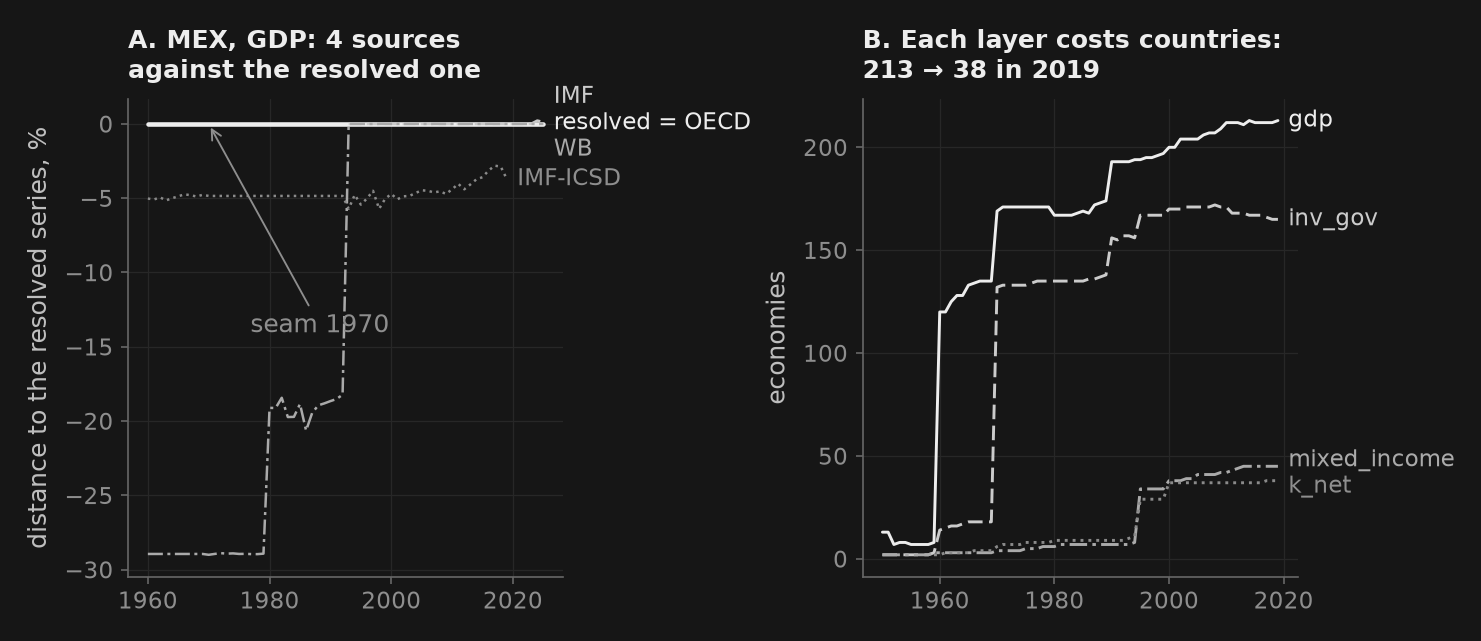

In [20]:
fig, axes = _nbstyle.figura(1, 2)
ticks = pd.to_datetime([f"{y}-01-01" for y in range(1960, 2021, 20)])
# A. Every source as its distance to the resolved series: a flat line grows like it, at another level.
# The primary is not drawn apart: where it publishes, it IS the resolved series.
ax = axes[0]
res = annual.query("code == @EXAMPLE and variable == 'gdp'").set_index("date").value
primary = prov_Y.query("code == @EXAMPLE and variable == 'gdp'").source.iloc[0]
gdp_raw = raw_Y.query("code == @EXAMPLE and variable == 'gdp' and source != @primary")
blocks = [b for b in RANK_Y if (gdp_raw.source == b).any()]
dashes = _nbstyle.styles(len(blocks) + 1)[1:]
ax.plot(res.index, 0 * res, color=_nbstyle.TINTA, lw=2.2, label=tr("resolved", "resuelta") + f" = {SHORT[primary]}")
for i, b in enumerate(blocks):
    s = gdp_raw[gdp_raw.source == b].set_index("date").value.sort_index()
    ax.plot(s.index, 100 * np.log(s / res.reindex(s.index)), color=cols[i + 1], ls=dashes[i], lw=1.2, label=SHORT[b])
seam = seams_Y.query("code == @EXAMPLE and variable == 'gdp' and method == 'ratio'")
if len(seam):
    d = seam.date.min()
    ax.annotate(tr("seam", "costura") + f" {d:%Y}", xy=(d, 0), xytext=(20, -100), textcoords="offset points",
                color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax.set_title(tr(f"A. {EXAMPLE}, GDP: {len(blocks) + 1} sources\nagainst the resolved one",
                f"A. {EXAMPLE}, PIB: {len(blocks) + 1} fuentes\ncontra la resuelta"))
ax.set_ylabel(tr("distance to the resolved series, %", "distancia a la serie resuelta, %"))
ax.set_xticks(ticks, [f"{t:%Y}" for t in ticks])

# B. Economies per year with each layer, up to the last year every layer is at 80% of its own peak
# (after it, what falls is the publication lag, not the coverage).
ax = axes[1]
layers = ["gdp", "inv_gov", "mixed_income", "k_net"]
per_year = {v: annual.loc[annual.variable == v].groupby("date").code.nunique() for v in layers}
last = min(s[s >= 0.8 * s.max()].index.max() for s in per_year.values())
for i, v in enumerate(layers):
    s = per_year[v].loc[:last]
    ax.plot(s.index, s, color=cols[i], ls=_nbstyle.styles(4)[i], lw=1.4, label=v)
ax.set_title(tr(f"B. Each layer costs countries:\n{per_year['gdp'][last]} → {per_year['k_net'][last]} in {last:%Y}",
                f"B. Cada capa cuesta países:\n{per_year['gdp'][last]} → {per_year['k_net'][last]} en {last:%Y}"))
ax.set_ylabel(tr("economies", "economías"))
ax.set_xticks(ticks, [f"{t:%Y}" for t in ticks])
_nbstyle.etiquetar(axes[0], donde="fin", fuera=True)
_nbstyle.etiquetar(axes[1], donde="fin")
plt.show()
del raw_Y, gdp_raw          # the annual stack before precedence is not read again
release_memory()

**What to look at in each panel.** In A each source is drawn as its distance, in percent, to the resolved series, which is the thick line at zero. A flat line is a source that grows like the resolved one even if it sits at another level: that is exactly what a ratio seam can fix, because it keeps each one's growth. A line that rises or falls is a source that grows differently, and if it does so over the overlap years the seam is flagged as unstable. Left of the arrow, the line of the source that extends the history is flat by construction —the resolved series *is* that source, rescaled by the overlap ratio— and its distance to zero is that ratio. A line that **jumps** is something else: a source that changed its base inside its own series, so that what it publishes before and after the jump does not grow like the resolved one. In B, each layer of detail costs economies —GDP is there for almost all of them, public investment for fewer, mixed income and capital for fewer still— and the fall is not smooth: it comes in steps, when a club of offices enters or leaves.

### 2.7 Step 9 — What the next notebook needs

The next notebook builds two economies per country: the one the accounts publish, and an **imputed** one, in which durable consumption is investment that accumulates into a stock of durable goods and public investment accumulates into public capital that yields services. For that it needs, and here it is checked that they are present: consumption by durability **with its deflator** —without it there is no stock of durables—, government investment separated from the rest and a price for it, the stocks where they are published and the consumption of fixed capital, compensation of employees, mixed income and the surplus, and self-employment.

Two things this notebook does **not** do, on purpose. It estimates no stock: a perpetual inventory requires deciding depreciation rates and an initial capital, and that decision belongs to the notebook that uses it. And it does not adjust the labour share itself: it leaves it the ingredients, with their provenance, and also the two already adjusted versions others publish —the ILO's (`labour_share`) and PWT's (`labsh`)— to compare with.

#### What is not here, and why

Where there is none, there is no column. The list for the three frequencies, because it is part of the delivery:
- **Investment deflators by institutional sector** (households, corporations, government), annual and quarterly. The sector accounts are published at current prices; none of the offices that enter here publishes their volume. For public investment the cell offers two substitutes: the deflator of total investment or of construction, and the IMF's implicit price, its public investment at current prices over the same at 2017 PPPs.
- **Annual vacancies.** No source publishes them at that frequency; they are aggregated from the quarterly panel with the record's rule.
- **Inter-country input-output.** They are files of a hundred megabytes per year, not an API; they have their own notebook.
- **Quarterly accounts from the World Bank and monthly IMF-WEO.** They do not exist: WDI is annual and the WEO, semiannual.
- The monthly panel's own absences —rates, yields, credit— are in §4.2.

In [21]:
INGREDIENTS = ["cons_dur", "cons_dur_defl", "inv_gov", "inv_defl", "inv_struct_defl", "inv_gov_ppp2017",
               "k_net", "k_gov_net", "k_gov_pim", "cfc", "comp_emp", "mixed_income", "surplus_mixed",
               "emp_selfemp", "emp_self_lfs", "labour_share"]
first = prov_Y.set_index(["variable", "code"])["first"]
for v in INGREDIENTS:
    pv = prov_Y[prov_Y.variable == v]
    by = " · ".join(f"{SHORT[b]} {n}" for b, n in pv.source.value_counts().items())
    print(tr(f"{v}: {len(pv)} economies ({by}), {int((first[v].dt.year < 1970).sum())} from before 1970.",
             f"{v}: {len(pv)} economías ({by}), {int((first[v].dt.year < 1970).sum())} desde antes de 1970."))
n_labsh = pwt.dropna(subset=["labsh"]).code.nunique()
print(tr(f"labsh (PWT 11.0, t01_pwt110.csv.gz): {n_labsh} economies.",
         f"labsh (PWT 11.0, t01_pwt110.csv.gz): {n_labsh} economías."))

# Identities run only where every part comes from one office: a cross-source sum tests the precedence, not the data.
one = prov_Y.set_index(["code", "variable"]).source
parts = ["cons_dur", "cons_semidur", "cons_nondur", "cons_serv"]
src = pd.concat([one.xs(v, level="variable") for v in parts], axis=1)
same = src.index[src.nunique(axis=1).eq(1) & src.notna().all(axis=1)]
dur = ann.loc[ann.index.get_level_values("code").isin(same), parts + ["cons_hh"]].dropna()
dur_gap = (dur[parts].sum(axis=1) / dur.cons_hh - 1).abs()
print(tr(f"Durable + semi-durable + non-durable + services against household consumption, within one office: "
         f"median |gap| {dur_gap.median():.1%} in {dur_gap.index.get_level_values('code').nunique()} countries "
         f"(the split covers households only, S14; cons_hh adds the non-profits and, depending on the office, residents' purchases abroad).",
         f"Duraderos + semiduraderos + no duraderos + servicios contra el consumo de los hogares, dentro de una oficina: "
         f"mediana de |brecha| {dur_gap.median():.1%} en {dur_gap.index.get_level_values('code').nunique()} países "
         f"(el desglose cubre sólo a los hogares, S14; cons_hh suma las ISFLSH y, según la oficina, las compras de los residentes fuera)."))

ig = prov_Y[prov_Y.variable == "inv_gov"]
n_acc = int(ig.source.isin(["y_oecd_ana", "y_eurostat_na"]).sum())
n_imf = int((ig.source == "y_imf_icsd").sum())
r = (ann.inv_gov / ann.inv).dropna()
print(tr(f"Public investment: {n_acc} economies with accounts data, {n_imf} only through the IMF, in the currency of "
         f"each country's GDP (§2.6); the median of inv_gov / inv is {r.median():.1%}.",
         f"Inversión pública: {n_acc} economías con dato de cuentas, {n_imf} sólo por el FMI, en la moneda del PIB de "
         f"cada país (§2.6); la mediana de inv_gov / inv es {r.median():.1%}."))

has = {v: set(prov_Y.code[prov_Y.variable == v]) for v in INGREDIENTS}
stock = has["k_net"] | has["k_gov_net"] | has["k_gov_pim"]
price_gov = has["inv_defl"] | has["inv_struct_defl"] | has["inv_gov_ppp2017"]
durables = has["cons_dur"] & has["cons_dur_defl"]
both_ = durables & has["inv_gov"] & price_gov & stock
g_mixed = both_ & has["mixed_income"]
g_self = both_ & (has["emp_selfemp"] | has["emp_self_lfs"])
print(tr(f"B's two economies, the published and the imputed, can be built in {len(both_)} countries: durables with "
         f"their deflator, public investment with a price, and a stock. The layer that binds is durables "
         f"({len(has['cons_dur'])} economies, {len(durables)} with the deflator). Gollin's adjustment, within those: "
         f"with mixed income in {len(g_mixed)}, with self-employment in {len(g_self)}.",
         f"Las dos economías de B, la publicada y la imputada, pueden construirse en {len(both_)} países: duraderos con "
         f"su deflactor, inversión pública con un precio y un acervo. La capa que ata es la de los duraderos "
         f"({len(has['cons_dur'])} economías, {len(durables)} con el deflactor). El ajuste de Gollin, dentro de ellos: "
         f"con renta mixta en {len(g_mixed)}, con cuenta propia en {len(g_self)}."))

n_dur, n_invgov = len(has["cons_dur"]), len(ig)
# The four parts add up to household consumption within one office, up to the S15 difference named above.
assert dur_gap.median() < 0.05
# Enough of each ingredient to make the next notebook worth running.
assert n_dur >= 30 and n_invgov >= 150 and len(g_mixed) >= 25
# The binding layer is durables, not the stocks or the price of public investment.
assert len(both_) >= len(durables) - 5

cons_dur: 51 economies (OECD 43 · Eurostat 8), 2 from before 1970.
cons_dur_defl: 49 economies (OECD 41 · Eurostat 8), 2 from before 1970.
inv_gov: 174 economies (IMF-ICSD 128 · OECD 42 · Eurostat 4), 18 from before 1970.
inv_defl: 177 economies (IMF 74 · OECD 61 · WB 37 · Eurostat 5), 40 from before 1970.
inv_struct_defl: 51 economies (OECD 47 · Eurostat 4), 6 from before 1970.
inv_gov_ppp2017: 173 economies (IMF-ICSD 173), 173 from before 1970.
k_net: 38 economies (OECD 35 · Eurostat 3), 4 from before 1970.
k_gov_net: 33 economies (OECD 33), 1 from before 1970.
k_gov_pim: 172 economies (IMF-ICSD 172), 19 from before 1970.
cfc: 45 economies (OECD 39 · Eurostat 6), 2 from before 1970.
comp_emp: 65 economies (OECD 59 · Eurostat 6), 4 from before 1970.
mixed_income: 45 economies (OECD 39 · Eurostat 6), 3 from before 1970.
surplus_mixed: 65 economies (OECD 59 · Eurostat 6), 4 from before 1970.
emp_selfemp: 51 economies (OECD 47 · Eurostat 4), 3 from before 1970.
emp_self_lfs: 201 economie

## 3. Quarterly: all the history each office publishes

The quarterly panel is the one the cycles read, and that is why it asks for something other than the annual one: not breadth, but **length and detail at once** —every expenditure component with its deflator, hours and employment from the same accounts, unemployment from the surveys— for a few dozen economies, from wherever each one starts.

| Step | Question | Source |
|---|---|---|
| §3.1 | Expenditure, output, income and labour, since when? | OECD, `qna_panel` |
| §3.2 | Who invests, and how many are they? | OECD, sector accounts and population |
| §3.3 | Unemployment, activity and vacancies? | surveys: OECD, Eurostat, ILO |
| §3.4 | How much do two offices disagree? And credit? | Eurostat, IMF, BIS |
| §3.5 | Who wins, and how many economies have it all? | precedence and ladder |

### 3.1 Step 10 — One call, every product, since 1947

`qna_panel` downloads the OECD quarterly accounts —expenditure, output, income, labour, durability and assets— and returns them as a `(code, date)` panel. Four arguments decide what arrives:

- `start="1947"`. Asking from 1995 was a quota decision, not a data one: the start date is set by each office, not by us. The United States starts in 1947 and the flow delivers all of it; the cell prints how many economies gain history before 1995.
- `real=False`. No volumes: with the nominal series and the deflator the volume is rebuilt exactly (§1).
- `sa="x13"`. It takes the official adjustment where there is one and applies X-13 where there is not — in the download, with its provenance recorded country by country; never here.
- `labor=True`. Employment and hours from the same accounts, with their time base **already repaired**. Some office publishes hours on another time base; `qna_panel` corrects them and keeps the factor, which travels in the panel as `hours_factor` so that the correction can be seen. It is a claim with an arithmetic consequence: divide hours by employment and by the thirteen weeks of a quarter and a plausible working week must come out. The cell checks it; the factor is identified, not chosen.

**Look at the receipt.** Each country publishes in its own price reference year, and some —those with base `Q`— do not chain: their deflators are fixed-base. Nothing in the column names says so; the numbers simply arrive.

In [22]:
from puremacro.fetch import qna_countries, qna_panel, qna_meta

qna = load_block("q_oecd_qna", lambda: qna_panel(qna_countries(), start="1947", assets=True, durability=True,
                                                  output=True, income=True, labor=True, labor_activities=True,
                                                  sa="x13", real=False),
                 tr("OECD quarterly national accounts", "cuentas nacionales trimestrales de la OCDE"))
qmeta = qna_meta(qna).set_index("code")      # per-country records: the attrs travel with the block, offline too


def quarter(d):
    """2020T2 in Spanish, 2020Q2 in English."""
    return f"{d.year}{tr('Q', 'T')}{d.quarter}"


# hours_factor is per-country metadata (qna_meta's hours_scale), broadcast as rows to every quarter
# with hours: B reads it from the quarterly panel, so the repair can be seen where the hours are used.
scale = pd.to_numeric(qmeta.hours_scale, errors="coerce")
hours_factor = (qna.loc[qna.variable == "hours", ["code", "date"]].astype({"code": str})
                .assign(variable="hours_factor", value=lambda d: d.code.map(scale), source="q_oecd_qna")
                .dropna(subset=["value"]))

q = wide_panel(qna[qna.variable.isin(["gdp", "inv", "hours", "emp"])])     # the four this section reads
start = q.gdp.dropna().reset_index().groupby("code").date.min()
n_pre95 = int((start < "1995-01-01").sum())
print(tr(f"Panel: {len(start)} economies, {quarter(start.min())}–{quarter(qna.date.max())}; "
         f"{n_pre95} gain history before 1995, USA since {quarter(start['USA'])}.",
         f"Panel: {len(start)} economías, {quarter(start.min())}–{quarter(qna.date.max())}; "
         f"{n_pre95} ganan historia anterior a 1995, EUA desde {quarter(start['USA'])}."))

refs = qmeta.price_ref_year.dropna().astype(int)
q_codes = sorted(qmeta.index[qmeta.price_base == "Q"])
print(tr(f"Price reference years: {refs.nunique()} different ones, from {refs.min()} to {refs.max()}. "
         f"Fixed base (Q): {', '.join(q_codes)} — a downloader that keeps only chained series (L) returns an "
         f"empty frame for them, and without a warning.",
         f"Años de referencia de precios: {refs.nunique()} distintos, de {refs.min()} a {refs.max()}. "
         f"De base fija (Q): {', '.join(q_codes)} — un descargador que filtre sólo encadenados (L) les devuelve "
         f"un marco vacío, y sin avisar."))

# The implied working week: hours (millions per quarter) / employment (thousands) / 13 weeks.
week = (q.hours * 1e6 / (q.emp * 1e3) / 13).dropna()
repaired = scale[scale.notna() & scale.ne(1)]
for c, f in repaired.items():
    wk = week.xs(c, level="code").median()
    print(tr(f"hours_factor different from 1: {c} ×{f:g}. Without the repair its working week would be "
             f"{wk / f:.1f} hours; with it, {wk:.1f}.",
             f"hours_factor distinto de 1: {c} ×{f:g}. Sin la reparación su jornada sería de {wk / f:.1f} horas "
             f"semanales; con ella, {wk:.1f}."))
med = week.median()
out = week[~week.between(25, 50)]
print(tr(f"Implied working week, hours / (employment × 13): median {med:.1f} hours in "
         f"{week.index.get_level_values('code').nunique()} economies; outside 25–50 hours, {len(out)} country-quarters: ",
         f"Jornada implícita, horas / (ocupados × 13): mediana de {med:.1f} horas en "
         f"{week.index.get_level_values('code').nunique()} economías; fuera de 25–50 horas, {len(out)} país-trimestres: ")
      + ", ".join(f"{c} {quarter(d)} ({v:.1f})" for (c, d), v in out.items()) + ".")

# Price bases are the two the OECD publishes, and nothing else.
assert set(qmeta.price_base) <= {"L", "Q"}
# The hours repair is the one the arithmetic identifies, and it is applied: absurd without it, plausible with it.
assert len(repaired) > 0
for c, f in repaired.items():
    assert week.xs(c, level="code").median() / f < 25 < week.xs(c, level="code").median() < 50
assert 25 < med < 50
# Outside the band only the 2020 lockdown, when hours fell and headcounts did not (furlough schemes).
assert set(out.index.get_level_values("date").year) <= {2020}
# Asking from 1947 is what buys the history.
assert start["USA"] <= pd.Timestamp("1950-01-01")

q_oecd_qna             444,584 rows ·  49 economies ·  86 variables · 1947–2026 · frozen
Panel: 49 economies, 1947Q1–2026Q2; 19 gain history before 1995, USA since 1947Q1.
Price reference years: 14 different ones, from 1995 to 2025. Fixed base (Q): ARG, CHN, IDN, IND, MEX, ZAF — a downloader that keeps only chained series (L) returns an empty frame for them, and without a warning.
hours_factor different from 1: CHL ×13. Without the repair its working week would be 3.2 hours; with it, 41.3.
Implied working week, hours / (employment × 13): median 32.9 hours in 33 economies; outside 25–50 hours, 5 country-quarters: DEU 2020Q2 (24.5), DEU 2020Q3 (25.0), DNK 2020Q2 (25.0), FRA 2020Q2 (23.4), LUX 2020Q2 (23.8).


### 3.2 Step 11 — Who invests, and how many are they

Two things the quarterly panel needs and `qna_panel` does not bring. The first is investment by institutional sector, and the OECD publishes it along two roads that do not fully overlap: an expenditure-by-sector flow for a handful of economies, and the quarterly sector accounts for many more. `qna_sector_gfcf` joins the two, country by country, and records in the metadata which road each one took.

**Mind the double count.** In the sector accounts the same item appears as a resource and as a use, and a query that does not pin that dimension returns investment twice. puremacro pins the use side (`ACCOUNTING_ENTRY = D`); the cell checks the consequence: government plus the rest must add up to the whole economy, not to twice it.

The second is population, in thousands of persons, which turns any aggregate into a per-capita one without leaving the same source.

In [23]:
from puremacro.fetch import qna_sector_gfcf, qna_population

gfcf_q = load_block("q_oecd_gfcf_sector", lambda: qna_sector_gfcf(start="1947", sa="x13"),
                    tr("OECD quarterly GFCF by sector", "FBCF trimestral por sector, OCDE"))
pop_q = load_block("q_oecd_pop", lambda: qna_population(start="1947"),
                   tr("OECD quarterly population", "población trimestral, OCDE"))

# Which road each economy took, read from the block's own metadata.
road = pd.DataFrame(gfcf_q.attrs["meta"]).query("variable == 'inv_gov'")
by_sector = road.source.str.contains("GFCF_SECTOR")
g = wide_panel(gfcf_q)
gov0 = g.inv_gov.dropna().reset_index().groupby("code").date.min()
print(tr(f"Quarterly public investment: {len(gov0)} economies — {by_sector.sum()} through the expenditure-by-sector "
         f"flow, {(~by_sector).sum()} through the sector accounts; USA since {quarter(gov0['USA'])}.",
         f"Inversión pública trimestral: {len(gov0)} economías — {by_sector.sum()} por el flujo de gasto por sector, "
         f"{(~by_sector).sum()} por las cuentas sectoriales; EUA desde {quarter(gov0['USA'])}."))

# The sum of the two sectors against the whole economy of qna_panel (same office, another table).
both = g.join(q[["inv"]], how="inner").dropna()
gap = ((both.inv_gov + both.inv_priv) / both.inv - 1).abs()
(wc, wd), sector_gap = gap.idxmax(), gap.median()
print(tr(f"inv_gov + inv_priv against inv (same office): median |gap| {sector_gap:.2%} in {len(gap):,} "
         f"country-quarters; worst {wc} {quarter(wd)} ({gap.max():.1%}). A double count would put it near 100%.",
         f"inv_gov + inv_priv frente a inv (misma oficina): mediana de |brecha| {sector_gap:.2%} en {len(gap):,} "
         f"país-trimestres; la peor, {wc} {quarter(wd)} ({gap.max():.1%}). Un doble conteo la pondría cerca del 100%."))

pop0 = pop_q.loc[pop_q.variable == "population"].groupby("code", observed=True).date.min()
print(tr(f"Quarterly population: {len(pop0)} economies, USA since {quarter(pop0['USA'])}.",
         f"Población trimestral: {len(pop0)} economías, EUA desde {quarter(pop0['USA'])}."))

# Deduplicated: the two sectors add up to the whole economy, not to twice it.
assert sector_gap < 0.01
# The repeated entry did not survive.
assert not gfcf_q.duplicated(["code", "date", "variable"]).any()

q_oecd_gfcf_sector       8,594 rows ·  34 economies ·   2 variables · 1947–2026 · frozen
q_oecd_pop              20,672 rows ·  43 economies ·   8 variables · 1947–2026 · frozen
Quarterly public investment: 34 economies — 11 through the expenditure-by-sector flow, 23 through the sector accounts; USA since 1947Q1.
inv_gov + inv_priv against inv (same office): median |gap| 0.07% in 4,178 country-quarters; worst BGR 1999Q1 (52.1%). A double count would put it near 100%.
Quarterly population: 42 economies, USA since 1947Q1.


### 3.3 Step 12 — Surveys next to accounts: unemployment, activity, vacancies

Unemployment is not in the national accounts; it is in the labour force surveys, and the OECD compiles them quarterly since 1955 for whoever has them. Vacancies arrive along two roads that do not measure the same thing: Eurostat publishes the vacancy **rate** —unfilled posts over all posts— for the Union and its periphery, and the OECD the **number** of vacancies registered with the public employment offices, an administrative count whose level depends on how much of the market goes through those offices: it is compared within a country, not across countries. The ILO brings quarterly unemployment and informality for the economies that measure them outside those clubs. With the vacancy rate and the unemployment rate, §3.5 computes labour-market tightness, $\theta = v/u$.

**A number that is promised is checked where it is used.** That the US survey starts in 1955 is a claim about the panel, not about the downloader; the cell checks it with the number, not with the call.

A naming rule that repeats from here on: **a series' name says its adjustment**. The ILO's quarterly unemployment arrives unadjusted and is stored as `urate_nsa`, and the number of unemployed as `unemp_nsa`. If it shared a name with the OECD's adjusted `urate`, the precedence would mix the two and nothing would notice. And another one that already appeared in §2.3: the accounts count **jobs** in the territory and the survey **residents** in work; where they differ most is where most people work in one country and live in another.

In [24]:
from puremacro.fetch import oecd_lfs_panel, oecd_vacancies, fetch_eurostat_vacancies, ilostat_panel

lfs_q = load_block("q_oecd_lfs", lambda: oecd_lfs_panel(freq="Q", start="1950"),
                   tr("OECD labour force surveys, quarterly", "encuestas de fuerza de trabajo, OCDE, trimestral"))
vac_q = load_block("q_oecd_vac", lambda: oecd_vacancies(freq="Q", start="1950"),
                   tr("OECD registered vacancies", "vacantes registradas, OCDE"))
esvac_q = load_block("q_eurostat_vac", lambda: fetch_eurostat_vacancies(indicator="JVR", nace="B-T", s_adj="SA"),
                     tr("Eurostat job vacancy rate", "tasa de vacantes de Eurostat"))
ilo_q = load_block("q_ilo", lambda: ilostat_panel(freq="Q"),
                   tr("ILOSTAT quarterly labour panel", "panel laboral trimestral de ILOSTAT"))

u0 = lfs_q.loc[lfs_q.variable == "urate"].groupby("code", observed=True).date.min()
print(tr(f"Seasonally adjusted unemployment (OECD): {len(u0)} economies; {int((u0 < '1970-01-01').sum())} since "
         f"before 1970, USA since {quarter(u0['USA'])}.",
         f"Paro desestacionalizado (OCDE): {len(u0)} economías; {int((u0 < '1970-01-01').sum())} desde antes "
         f"de 1970, EUA desde {quarter(u0['USA'])}."))
vac0 = vac_q.loc[vac_q.variable == "vacancies"].groupby("code", observed=True).date.min().sort_values()
print(tr(f"Vacancy rate (Eurostat): {esvac_q.code.nunique()} economies, {quarter(esvac_q.date.min())}–"
         f"{quarter(esvac_q.date.max())}. Registered vacancies (OECD, a count): {len(vac0)} economies, "
         f"{vac0.index[0]} since {quarter(vac0.iloc[0])}.",
         f"Tasa de vacantes (Eurostat): {esvac_q.code.nunique()} economías, {quarter(esvac_q.date.min())}–"
         f"{quarter(esvac_q.date.max())}. Vacantes registradas (OCDE, un conteo): {len(vac0)} economías, "
         f"{vac0.index[0]} desde {quarter(vac0.iloc[0])}."))
ilo_u = set(ilo_q.code[ilo_q.variable == "urate_nsa"])
beyond = ilo_u - set(lfs_q.code.unique()) - set(esvac_q.code.unique())
n_inf = ilo_q.loc[ilo_q.variable == "informal_rate"].code.nunique()
print(tr(f"Unadjusted unemployment (ILO): {len(ilo_u)} economies, {len(beyond)} of them beyond the OECD and "
         f"Eurostat surveys. Quarterly informality: {n_inf}.",
         f"Paro sin desestacionalizar (OIT): {len(ilo_u)} economías, {len(beyond)} de ellas más allá de las "
         f"encuestas de la OCDE y Eurostat. Informalidad trimestral: {n_inf}."))

# Heads in the accounts (jobs in the territory) against employed in the survey (residents in work).
heads = pd.concat([q.emp, wide_panel(lfs_q[lfs_q.variable == "emp_lfs"]).emp_lfs], axis=1).dropna()
diff = heads.emp / heads.emp_lfs - 1
by_code = diff.groupby(level="code").median()
far = by_code.abs().idxmax()
print(tr(f"Heads in the accounts against employed in the survey: median |difference| {diff.abs().median():.1%} in "
         f"{len(by_code)} economies; the largest, {far} ({by_code[far]:+.0%}) — two concepts, two names.",
         f"Cabezas de las cuentas frente a ocupados de la encuesta: mediana de |diferencia| {diff.abs().median():.1%} en "
         f"{len(by_code)} economías; la mayor, {far} ({by_code[far]:+.0%}) — dos conceptos, dos nombres."))

# US survey unemployment since 1955, as promised.
assert u0["USA"] <= pd.Timestamp("1955-01-01")
# Names carry the adjustment: no NSA series under an SA name, and the ILO's counts say they are unadjusted.
assert not set(ilo_q.variable.unique()) & {"urate", "emp_lfs", "lf", "wap", "unemp"}
# Rates are rates.
assert lfs_q.query("variable == 'urate'").value.between(0, 100).all()
assert esvac_q.value.between(0, 100).all()

q_oecd_lfs              42,390 rows ·  45 economies ·   9 variables · 1955–2026 · frozen
q_oecd_vac               9,510 rows ·  32 economies ·   4 variables · 1955–2026 · frozen
q_eurostat_vac           1,818 rows ·  29 economies ·   1 variables · 2003–2026 · frozen


   set aside (historical or territory): JEY
q_ilo                   89,297 rows · 130 economies ·  11 variables · 1948–2026 · frozen


Seasonally adjusted unemployment (OECD): 44 economies; 4 since before 1970, USA since 1955Q1.
Vacancy rate (Eurostat): 29 economies, 2003Q2–2026Q2. Registered vacancies (OECD, a count): 18 economies, AUT since 1955Q1.
Unadjusted unemployment (ILO): 122 economies, 75 of them beyond the OECD and Eurostat surveys. Quarterly informality: 54.
Heads in the accounts against employed in the survey: median |difference| 2.5% in 37 economies; the largest, LUX (+61%) — two concepts, two names.


### 3.4 Step 13 — Second opinions, and credit

Eurostat is not here to fill the OECD's gaps: it is here to tell us how much two offices that read the same accounts disagree, and to bring the European economies the OECD does not cover. The IMF does the same outside the two clubs. The cell measures the disagreement where both publish: a small median is what to expect, and the worst one says where to look.

Credit to the private sector is published by the BIS **quarterly**, as a percentage of GDP, and that is how it is stored, together with house prices. A quarter is not interpolated to make up months (§4.2).

In [25]:
from puremacro.fetch import eurostat_na_panel, imf_nea_panel

eurostat_q = load_block("q_eurostat_na", lambda: eurostat_na_panel(freq="Q", durability=True, assets=True, output=True,
                                                                    income=True, labor=True, real=True),
                        tr("Eurostat quarterly national accounts", "cuentas nacionales trimestrales de Eurostat"))
imf_q = load_block("q_imf_nea", lambda: imf_nea_panel(freq="Q", sa="SA", real=True),
                   tr("IMF quarterly national accounts (SA)", "cuentas nacionales trimestrales del FMI (desestacionalizadas)"))


def gdp_of(block):
    """Nominal GDP of one block, as a (code, date) series."""
    return block.loc[block.variable == "gdp"].set_index(["code", "date"]).value


oecd_gdp, es_gdp, imf_gdp = gdp_of(qna), gdp_of(eurostat_q), gdp_of(imf_q)
for other, label in [(es_gdp, "Eurostat"), (imf_gdp, tr("the IMF", "el FMI"))]:
    pair = pd.concat([oecd_gdp, other], axis=1, keys=["oecd", "other"]).dropna()
    dlog = np.log(pair.oecd / pair.other).abs()
    worst = dlog.groupby(level="code").median().idxmax()
    print(tr(f"Where the OECD and {label} publish the nominal GDP of the same economy and quarter "
             f"({len(pair):,} country-quarters): median |Δ log| {dlog.median():.4f}; the worst economy, {worst} "
             f"({dlog.xs(worst, level='code').median():.3f}).",
             f"Donde la OCDE y {label} publican el PIB nominal de la misma economía y trimestre "
             f"({len(pair):,} país-trimestres): mediana de |Δ log| {dlog.median():.4f}; la peor economía, {worst} "
             f"({dlog.xs(worst, level='code').median():.3f})."))
    if other is es_gdp:
        d_es = dlog.median()
codes = {k: set(s.index.get_level_values("code")) for k, s in [("oecd", oecd_gdp), ("es", es_gdp), ("imf", imf_gdp)]}
only_es = sorted(codes["es"] - codes["oecd"])
only_imf = sorted(codes["imf"] - codes["oecd"] - codes["es"])
nsa_es = sorted(set(eurostat_q.code[eurostat_q.variable == "gdp_nsa"]))
print(tr(f"Only through Eurostat: {', '.join(only_es)}; and, unadjusted under gdp_nsa, {', '.join(nsa_es)}. "
         f"Only through the IMF: {len(only_imf)} economies, among them {', '.join(only_imf[:6])}.",
         f"Sólo por Eurostat: {', '.join(only_es)}; y, sin desestacionalizar bajo gdp_nsa, {', '.join(nsa_es)}. "
         f"Sólo por el FMI: {len(only_imf)} economías, entre ellas {', '.join(only_imf[:6])}."))

# Two offices reading the same accounts agree to rounding, almost everywhere.
assert d_es < 0.01
# Each second opinion also brings economies of its own.
assert only_es and only_imf

q_eurostat_na          306,811 rows ·  39 economies · 119 variables · 1978–2026 · frozen
q_imf_nea              127,273 rows ·  66 economies ·  18 variables · 1950–2026 · frozen


Where the OECD and Eurostat publish the nominal GDP of the same economy and quarter (3,928 country-quarters): median |Δ log| 0.0000; the worst economy, GBR (0.006).
Where the OECD and the IMF publish the nominal GDP of the same economy and quarter (6,685 country-quarters): median |Δ log| 0.0000; the worst economy, GBR (0.004).
Only through Eurostat: ALB, BIH, CYP, MKD, MLT, MNE, SRB; and, unadjusted under gdp_nsa, MDA, XKX. Only through the IMF: 13 economies, among them ARM, CMR, ECU, HND, JOR, KAZ.


In [26]:
from puremacro.fetch import bis_panel

bis_q = load_block("q_bis", lambda: bis_panel(freq="Q"),
                   tr("BIS credit, property prices and exchange rates", "crédito, vivienda y tipos de cambio del BIS"))

c0 = bis_q.loc[bis_q.variable == "credit_gdp"].groupby("code", observed=True).date.min()
n_hp = bis_q.loc[bis_q.variable == "house_price"].code.nunique()
n_dsr = bis_q.loc[bis_q.variable == "dsr"].code.nunique()
print(tr(f"Private credit / GDP: {len(c0)} economies, {int((c0 < '1970-01-01').sum())} since before 1970 "
         f"(USA since {quarter(c0['USA'])}). House prices: {n_hp}. Debt service ratio: {n_dsr}.",
         f"Crédito privado / PIB: {len(c0)} economías, {int((c0 < '1970-01-01').sum())} desde antes de 1970 "
         f"(EUA desde {quarter(c0['USA'])}). Precios de la vivienda: {n_hp}. Servicio de la deuda: {n_dsr}."))
print(tr(f"The exchange rate against the dollar reaches {bis_q.loc[bis_q.variable == 'fx_usd'].code.nunique()} "
         f"economies: the BIS is the broadest quarterly source of the panel, not only the one for credit.",
         f"El tipo de cambio contra el dólar llega a {bis_q.loc[bis_q.variable == 'fx_usd'].code.nunique()} "
         f"economías: el BIS es la fuente trimestral más ancha del panel, no sólo la del crédito."))

# The euro area is an aggregate: it never reaches the panel as an economy.
assert not set(bis_q.code.unique()) & AGGREGATES
# Credit reaches at least forty economies.
assert len(c0) >= 40

   set aside (historical or territory): AIA, ANT, MSR
q_bis                  236,767 rows · 186 economies ·  21 variables · 1791–2026 · frozen


Private credit / GDP: 43 economies, 20 since before 1970 (USA since 1947Q4). House prices: 57. Debt service ratio: 32.
The exchange rate against the dollar reaches 186 economies: the BIS is the broadest quarterly source of the panel, not only the one for credit.


### 3.5 Step 14 — The same rule at another frequency, and the coverage ladder

The precedence is the same and is applied the same way, because a criterion that changes with the frequency is not a criterion. The OECD beats Eurostat, and Eurostat the IMF; the OECD's surveys beat the ILO's, which besides arrive under another name. The thresholds change units, not ideas: in the annual panel, eight years to be primary and three of overlap to measure a seam; here, five years of quarters and one of overlap.

Three series are not downloaded: they are computed here, after the precedence, and the dictionary marks them as `derived`. The working week (`hours_week`) and the self-employed share of employment (`self_emp_share`) only where numerator and denominator come from the same source —a ratio between two offices measures their disagreement, not the economy—; tightness $\theta$ joins two surveys by definition, Eurostat's vacancy rate and the OECD's unemployment rate. None is extended backwards, and each has its own provenance row.

Then, the question that decides any quarterly study: how many economies have **everything** the study asks for? Each layer of detail costs countries, and the step that costs the most is not always the one you expect. The panel is the union; the ladder is what each question can afford.

In [27]:
MIN_OBS_Q = 20       # five years of quarters before a source can be primary
MIN_OVERLAP_Q = 4    # one year of common quarters to measure a seam
RANK_Q = {"q_oecd_qna": 1, "q_oecd_gfcf_sector": 1, "q_oecd_pop": 1, "q_oecd_lfs": 1, "q_oecd_vac": 1, "q_bis": 1,
          "q_eurostat_na": 2, "q_eurostat_vac": 2,
          "q_imf_nea": 3, "q_ilo": 3}
raw_Q = stack([qna, hours_factor, gfcf_q, pop_q, lfs_q, vac_q, esvac_q, ilo_q, eurostat_q, imf_q, bis_q])
# The blocks live on in raw_Q: one copy is enough.
del gfcf_q, pop_q, lfs_q, vac_q, esvac_q, ilo_q, eurostat_q, imf_q, bis_q, hours_factor
release_memory()

audit_Q = audit_units(raw_Q, "Q")
count = audit_Q.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"Quarterly audit: {count['same']:,} of {len(audit_Q):,} comparisons agree; {count['pow10']} powers of ten; "
         f"{count['currency']} other currencies or bases; {count['concept']} {'different concept' if count['concept'] == 1 else 'different concepts'} — ",
         f"Auditoría trimestral: {count['same']:,} de {len(audit_Q):,} comparaciones coinciden; {count['pow10']} "
         f"potencias de diez; {count['currency']} monedas o bases distintas; {count['concept']} "
         f"{'concepto distinto' if count['concept'] == 1 else 'conceptos distintos'} — ")
      + ", ".join(f"{r.code} {r.variable} ({r.pair}, {10 ** r.log10_ratio:.3g})"
                  for r in audit_Q.query("verdict == 'concept'").itertuples()) + ".")
# Where they come from: how far each side of the clashing pairs reaches.
clash = audit_Q.query("verdict == 'concept'")
for c in sorted(set(clash.code)):
    pair_blocks = {b for p in clash.pair[clash.code == c] for b in p.split(" / ")}
    ends = raw_Q.loc[(raw_Q.code == c) & raw_Q.source.isin(pair_blocks)].groupby("source", observed=True).date.max()
    print(f"   {c}: " + ", ".join(f"{b} " + tr("until ", "hasta ") + quarter(d) for b, d in ends.items())
          + tr(" — a vintage that stopped against one that kept being revised.",
               " — una edición que se detuvo frente a otra que se siguió revisando."))

# The precedence of §2.6, with the quarterly thresholds.
quarterly, prov_Q, seams_Q = splice(raw_Q, "Q", RANK_Q, min_obs=MIN_OBS_Q, min_overlap=MIN_OVERLAP_Q)
seam_receipts(prov_Q, seams_Q)
n_ext = int((prov_Q.n_extended > 0).sum())
print(tr(f"In quarters the OECD is already the longest source wherever it publishes: {n_ext} of {len(prov_Q):,} "
         f"country-variables are extended backwards; the other offices add economies and series, not history.",
         f"En trimestres la OCDE ya es la fuente más larga allí donde publica: {n_ext} de {len(prov_Q):,} "
         f"país-variables se extienden hacia atrás; las otras oficinas añaden economías y series, no historia."))
del raw_Q, qna          # the quarterly stack before precedence is not read again
release_memory()

# After puremacro's rescaling, overlaps agree (first frozen run: 99.6%) ...
assert (audit_Q.verdict == "same").mean() > 0.95
# ... and the concept clashes are few enough to list one by one (first frozen run: 0.4%).
assert (audit_Q.verdict == "concept").mean() < 0.02
# The OECD already carries the longest history almost everywhere: few seams, and those few are stable.
ratio_Q = seams_Q.query("method == 'ratio'")
assert len(ratio_Q) < 0.01 * len(prov_Q) and (ratio_Q.empty or ratio_Q.stable.mean() > 0.75)

Quarterly audit: 1,667 of 1,674 comparisons agree; 0 powers of ten; 6 other currencies or bases; 1 different concept — GBR va_fin (q_eurostat_na / q_oecd_qna, 0.824).
   GBR: q_eurostat_na until 2020Q3, q_oecd_qna until 2026Q2 — a vintage that stopped against one that kept being revised.


Primary by block (country-variables): q_oecd_qna 3,436 · q_ilo 1,200 · q_bis 1,168 · q_eurostat_na 584 · q_oecd_lfs 343 · q_imf_nea 283 · q_oecd_pop 163 · q_oecd_gfcf_sector 67 · q_oecd_vac 51 · q_eurostat_vac 29
1 seam accepted, 100% of the ratio seams stable; it extends the history by a median of 4 periods. 0 extensions rejected.
0 seams absorb an exact power of ten; the factor stays in t01_seams.csv.
In quarters the OECD is already the longest source wherever it publishes: 1 of 7,324 country-variables are extended backwards; the other offices add economies and series, not history.


In [28]:
def ratio_rows(num, den, name, scale=1.0, same=True):
    """num / den on the spliced panel, as long rows of a derived series (rounded: stable hashes in §7)."""
    p = (quarterly.loc[quarterly.variable.isin([num, den])].astype({"code": str, "variable": str, "source": str})
         .pivot(index=["code", "date"], columns="variable", values=["value", "source"]).dropna())
    keep = (p["source", num] == p["source", den]) if same else np.ones(len(p), bool)
    v = (scale * p["value", num].astype(float) / p["value", den].astype(float))[keep]
    return v.round(9).rename("value").reset_index().assign(variable=name, source="derived")


# hours (millions per quarter) / employment (thousands) / 13 weeks; self-employed / employed; v / u.
derived = pd.concat([ratio_rows("hours", "emp", "hours_week", scale=1e3 / 13),
                     ratio_rows("emp_selfemp", "emp", "self_emp_share"),
                     ratio_rows("vrate", "urate", "theta", same=False)], ignore_index=True)
derived = derived[np.isfinite(derived.value)]
span = derived.groupby(["code", "variable"]).date.agg(first="min", last="max", n="size").reset_index()
prov_D = span.assign(freq="Q", source="derived", alternatives="", extended_from="", n_extended=0)
quarterly = stack([quarterly, derived])
prov_Q = pd.concat([prov_Q, prov_D.reindex(columns=prov_Q.columns)], ignore_index=True)
print(tr("Derived after the splice: ", "Derivadas después de la precedencia: ")
      + " · ".join(f"{v} {span.code[span.variable == v].nunique()} " + tr("economies", "economías")
                   for v in ["hours_week", "self_emp_share", "theta"]))

prim = prov_Q.query("variable == 'gdp'").source.value_counts()
print(tr(f"Quarterly GDP: {prim.sum()} economies ({prim.get('q_oecd_qna', 0)} OECD, "
         f"{prim.get('q_eurostat_na', 0)} Eurostat, {prim.get('q_imf_nea', 0)} IMF).",
         f"PIB trimestral: {prim.sum()} economías ({prim.get('q_oecd_qna', 0)} OCDE, "
         f"{prim.get('q_eurostat_na', 0)} Eurostat, {prim.get('q_imf_nea', 0)} FMI)."))

# The contract: unique keys, finite values, period-start dates.
quarterly = validate_long(quarterly, "Q")
# One provenance row per country-variable in the panel, and no other.
assert len(prov_Q) == quarterly.groupby(["code", "variable"], observed=True).ngroups
# Every name B and C read survived the stacking.
assert set(CONTRACT["Q"]) <= set(quarterly.variable.unique())
# At least the 49 economies with quarterly GDP of the October 2026 panel; more is the point of §3.4.
assert prim.sum() >= 49

Derived after the splice: hours_week 37 economies · self_emp_share 42 economies · theta 27 economies
Quarterly GDP: 69 economies (49 OECD, 7 Eurostat, 13 IMF).


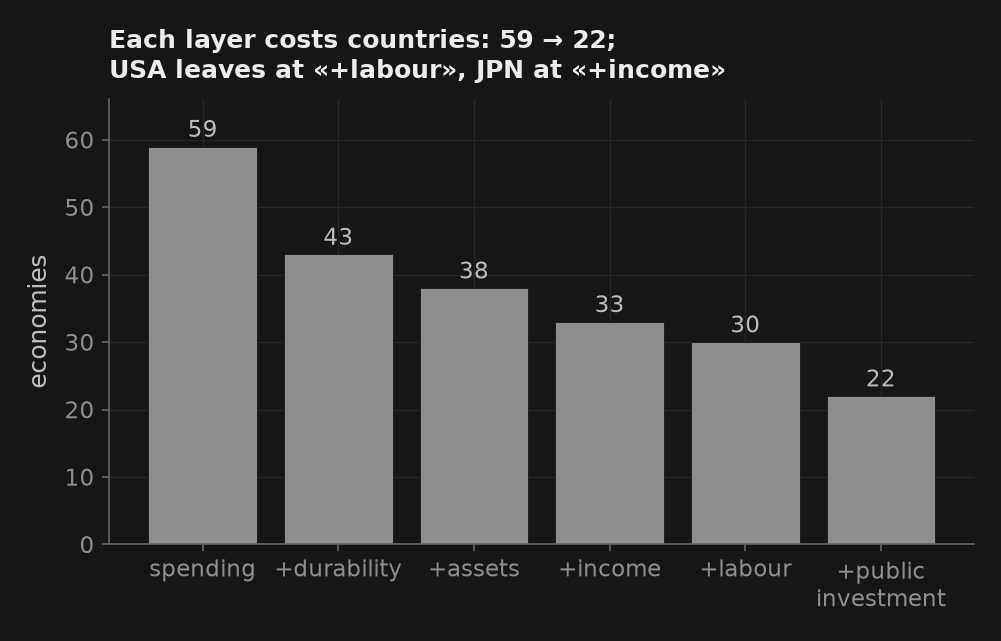

spending 59 → +durability 43 → +assets 38 → +income 33 → +labour 30 → +public investment 22
The step that drops USA is «+labour»; the one that drops JPN, «+income».


In [29]:
LADDER = [
    (tr("spending", "gasto"), ["gdp", "cons_hh", "cons_gov", "inv", "exports", "imports"]),
    (tr("+durability", "+durabilidad"), ["cons_dur", "cons_nondur", "cons_serv"]),
    (tr("+assets", "+activos"), ["inv_dwell", "inv_struct", "inv_equip", "inv_ipp"]),
    (tr("+income", "+renta"), ["comp_emp", "surplus_mixed"]),
    (tr("+labour", "+trabajo"), ["emp", "hours"]),
    (tr("+public\ninvestment", "+inversión\npública"), ["inv_gov"]),
]
MIN_Q = 40         # ten years of a series before it counts as "having" it

cov_Q = coverage(quarterly, "Q")
has = cov_Q[cov_Q.n >= MIN_Q].groupby("variable").code.apply(set)
steps, codes = [], None
for label, names in LADDER:
    for v in names:
        codes = set(has.get(v, set())) if codes is None else codes & has.get(v, set())
    steps.append((label, codes))
counts = [len(c) for _, c in steps]
# The step at which each of the two largest OECD economies leaves the ladder.
drop = {c: next((label.replace("\n", " ") for label, s in steps if c not in s), "—") for c in ("USA", "JPN")}

fig, ax = _nbstyle.figura()
x = np.arange(len(steps))
ax.bar(x, counts, color=_nbstyle.BARRA_COLORES[1], edgecolor=_nbstyle.FONDO, lw=0.4)
ax.set_xticks(x, [label for label, _ in steps])
_nbstyle.etiquetar_barras(ax, fmt="{:.0f}")
ax.set_ylim(0, 1.12 * counts[0])        # room for the first bar's label under the title
ax.set_ylabel(tr("economies", "economías"))
ax.set_title(tr(f"Each layer costs countries: {counts[0]} → {counts[-1]};\nUSA leaves at «{drop['USA']}», JPN at «{drop['JPN']}»",
                f"Cada capa cuesta países: {counts[0]} → {counts[-1]};\nEUA sale en «{drop['USA']}», JPN en «{drop['JPN']}»"))
plt.show()

print(" → ".join(f"{label.replace(chr(10), ' ')} {n}" for (label, _), n in zip(steps, counts)))
print(tr(f"The step that drops USA is «{drop['USA']}»; the one that drops JPN, «{drop['JPN']}».",
         f"El escalón que expulsa a EUA es «{drop['USA']}»; el que expulsa a JPN, «{drop['JPN']}»."))

# A ladder only goes down.
assert all(a >= b for a, b in zip(counts, counts[1:]))
assert counts[0] >= 45

**How to read the ladder without exaggerating.** Each bar counts economies with at least ten years of **every** series of its step and of the ones before, in any period; it does not say those years coincide. A regression with every layer needs, besides, a common contiguous block, and that is what `regular_block` gives (§6), not this figure. The steps that drop the United States and Japan are a property of what the OECD publishes quarterly, not of those economies: the annual accounts of §2.2 and §2.3 do bring their income and their labour.

## 4. Monthly: discover countries, do not invent observations

The monthly panel is the one of the current situation: few accounts and many signals —industrial production, unemployment, prices, rates, exchange rates— for every economy someone publishes each month. The rule is the title's: the queries discover which countries there are, and no cell fills a month the source did not publish.

| Step | Question | Source |
|---|---|---|
| §4.1 | Activity, labour and prices, and since when? | OECD, Eurostat |
| §4.2 | Exchange rates, rates, yields and commodities? Who wins? | BIS, IMF, markets, FRED; precedence |

### 4.1 Step 15 — Activity, labour and prices

The queries leave the country dimension open but fix every other one —frequency, concept, unit, sex, age, branch, adjustment—: each row of the concept table fixes everything but the country, and what the source does not publish stays as a missing row, not as a zero. If after fixing them more than one series is left per country and month, `stes_panel` refuses to choose —"Ambiguous"— instead of keeping the first one.

The OECD enters with three calls: `stes_panel` brings the short-term indicators —activity, rates, exchange rate, confidence surveys, money, unemployment and prices—, `oecd_lfs_panel` the labour force survey with its levels and the 15-to-64 age band, and `oecd_vacancies` the vacancies and the unemployment **registered** at the employment offices, which are not those of the survey. Survey unemployment appears in the first two: it is the same figure in two tables, and the cell checks that they say the same thing. Eurostat reads the same European surveys with another age band —15 to 74, not 15 and over— under the same name, `urate`; the record says so, and the cell measures how much it weighs.

Industrial production is not monthly GDP: it is industry, one part of output and almost everywhere not the largest. It serves as a signal of activity, and it is kept as such.

**Mind the prices.** In January 2026 the OECD changed the classification of its consumer price index: the old flow was frozen for the whole European Union and the new one does not bring everybody. The union of the two lives in puremacro, not here. And a reminder that has already cost dearly in this course: `CPALTT01MXM659N` is not monthly inflation but the year-on-year rate, and accumulating it as if it were monthly produces an absurd "price level". Here we keep **indices**, with their base year in the record; inflation is computed, not downloaded.

In [30]:
from puremacro.fetch import stes_panel, STES_CONCEPTS, oecd_lfs_panel, oecd_vacancies

stes = load_block("m_oecd_stes", lambda: stes_panel(start="1900"),
                  tr("OECD monthly short-term indicators", "indicadores mensuales de corto plazo de la OCDE"))
lfs_m = load_block("m_oecd_lfs", lambda: oecd_lfs_panel(freq="M", start="1950"),
                   tr("OECD monthly labour force survey", "encuesta mensual de fuerza de trabajo de la OCDE"))
vac_m = load_block("m_oecd_vac", lambda: oecd_vacancies(freq="M", start="1950"),
                   tr("OECD registered vacancies and unemployment", "vacantes y paro registrados de la OCDE"))


def codes_with(d, v):
    """Economies with at least one value of ``v`` in a long block."""
    return set(d.code[d.variable == v].astype(str))


# One line per concept, in the order of the OECD's own table: activity, rates, exchange rate, surveys,
# money, labour, prices. The course name is the record's; the unit and the adjustment are the OECD's.
spec = {course_name(c, NAMES["m_oecd_stes"]): s for c, s in STES_CONCEPTS.items()}
cov = (coverage(stes, "M").groupby("variable")
       .agg(n=("code", "size"), first=("first", "min"), last=("last", "max")))
cov = cov.reindex([v for v in spec if v in cov.index])
cov["sa"] = [{True: "SA", False: "NSA"}.get(spec[v].sa, "—") for v in cov.index]
cov["unit"] = [spec[v].unit for v in cov.index]
print(cov.reset_index().rename(columns={"n": tr("economies", "economías"), "first": tr("from", "desde"),
                                        "last": tr("to", "hasta"), "unit": tr("unit", "unidad")})
      .to_string(index=False))

# The CPI under the new classification, and the economies whose history still comes from the old flow.
cpi_meta = next(m for m in stes.attrs["meta"] if m["concept"] == "cpi")
stale = sorted(cpi_meta["stale_countries"])
cpi_last = stes.loc[stes.variable == "cpi"].groupby("code", observed=True).date.max()
print(tr(f"\nCPI: the old flow (frozen since the 2026 reclassification) completes the history of "
         f"{len(cpi_meta['countries_fallback'])} economies; for {len(stale)} the new one brings nothing and the series "
         f"stops where the old one ends: ",
         f"\nIPC: el flujo viejo (congelado desde la reclasificación de 2026) completa la historia de "
         f"{len(cpi_meta['countries_fallback'])} economías; para {len(stale)} el nuevo no trae nada y la serie "
         f"se queda donde termina el viejo: ")
      + ", ".join(f"{c} {cpi_last[c]:%Y-%m}" for c in stale) + ".")

# Survey unemployment is published twice by the OECD: the two tables must say the same thing.
both = pd.concat([d.loc[d.variable == "urate"].set_index(["code", "date"]).value for d in (stes, lfs_m)],
                 axis=1, keys=["stes", "lfs"]).dropna()
gap_u = (both.stes - both.lfs).abs()
print(tr(f"Labour force survey: unemployment in {len(codes_with(stes, 'urate') | codes_with(lfs_m, 'urate'))} "
         f"economies; the 15-64 band in {len(codes_with(lfs_m, 'urate_1564'))}. The same rate in both OECD tables: "
         f"{len(both):,} common country-months, largest difference {gap_u.max():.2f} pp.",
         f"Encuesta de fuerza de trabajo: paro en {len(codes_with(stes, 'urate') | codes_with(lfs_m, 'urate'))} "
         f"economías; el tramo de 15 a 64 años en {len(codes_with(lfs_m, 'urate_1564'))}. La misma tasa en los dos "
         f"cuadros de la OCDE: {len(both):,} país-meses en común, diferencia máxima {gap_u.max():.2f} pp."))
usa_v = "USA" in codes_with(vac_m, "vacancies")
print(tr(f"Registered at the employment offices: vacancies in {len(codes_with(vac_m, 'vacancies'))} economies "
         f"({'the USA among them' if usa_v else 'without the USA'}), registered unemployment in "
         f"{len(codes_with(vac_m, 'reg_unemp'))}.",
         f"Registrados en las oficinas de empleo: vacantes en {len(codes_with(vac_m, 'vacancies'))} economías "
         f"({'EUA entre ellas' if usa_v else 'sin EUA'}), paro registrado en "
         f"{len(codes_with(vac_m, 'reg_unemp'))}."))

# Labour rates are shares of a population: between 0 and 100. Prices and production indices are positive.
LAB_RATES = list(SERIES.query("freq == 'M' and family == 'labour_survey' and kind == 'rate'").variable)
for d in (stes, lfs_m):
    assert d.value[d.variable.isin(LAB_RATES)].between(0, 100).all()
assert (stes.value[stes.variable.astype(str).str.match(r"(cpi|hicp|ip)")] > 0).all()
# B's two monthly series, at least with the breadth of the panel they replace (41 and 39 economies).
assert len(codes_with(stes, "ip")) >= 39
assert len(codes_with(stes, "urate") | codes_with(lfs_m, "urate")) >= 39
# One survey, two tables, one number.
assert gap_u.max() < 0.05

m_oecd_stes            543,434 rows ·  49 economies ·  31 variables · 1914–2026 · frozen
m_oecd_lfs              46,833 rows ·  41 economies ·  13 variables · 1955–2026 · frozen
m_oecd_vac              28,034 rows ·  31 economies ·   4 variables · 1955–2026 · frozen
   variable  economies    from      to  sa                                             unit
         ip         41 1919-01 2026-08  SA                                index, 2015 = 100
     ip_mfg         44 1919-01 2026-08  SA                                index, 2015 = 100
  ip_constr         30 1955-01 2026-08  SA                                index, 2015 = 100
 retail_vol         40 1955-01 2026-08  SA                                index, 2015 = 100
    rate_on         47 1954-07 2026-09   —                                percent per annum
    rate_3m         45 1956-01 2026-09   —                                percent per annum
  yield_10y         46 1953-04 2026-09   —                                percent per ann

Registered at the employment offices: vacancies in 17 economies (the USA among them), registered unemployment in 27.


In [31]:
# The FRED code's suffix 659 is the change over the same month of the previous year. The index kept
# here reproduces it; read as a monthly rate and accumulated, it invents a price level.
fred_mx = (pd.read_csv(ruta_dato("CPALTT01MXM659N.csv"), parse_dates=["observation_date"])
           .set_index("observation_date").iloc[:, 0])
cpi_mx = stes.query("code == 'MEX' and variable == 'cpi'").set_index("date").value
yoy = (100 * (cpi_mx / cpi_mx.shift(12, freq="MS") - 1)).reindex(fred_mx.index)
gap_yoy = (yoy - fred_mx).dropna().abs()
since = fred_mx.loc["2000":]
fake = (1 + since / 100).prod() ** (12 / len(since)) - 1
print(tr(f"CPALTT01MXM659N is the 12-month change of MEX's index kept here: {len(gap_yoy)} months, largest "
         f"difference {gap_yoy.max():.4f} pp. Accumulated as if it were monthly, it would make Mexican prices grow "
         f"{fake:.0%} a year since 2000.",
         f"CPALTT01MXM659N es la variación a doce meses del índice de MEX que se guarda aquí: {len(gap_yoy)} meses, "
         f"diferencia máxima {gap_yoy.max():.4f} pp. Acumulada como si fuera mensual, haría crecer los precios de "
         f"México {fake:.0%} al año desde 2000."))

# The FRED series is year-on-year: the index reproduces it to rounding.
assert gap_yoy.max() < 0.01

CPALTT01MXM659N is the 12-month change of MEX's index kept here: 655 months, largest difference 0.0001 pp. Accumulated as if it were monthly, it would make Mexican prices grow 75% a year since 2000.


In [32]:
from puremacro.fetch import eurostat_monthly_panel

eurostat_m = load_block("m_eurostat", lambda: eurostat_monthly_panel(),
                        tr("Eurostat monthly indicators", "indicadores mensuales de Eurostat"))

n_h = len(codes_with(eurostat_m, "hicp_core"))
ip_new = sorted(codes_with(eurostat_m, "ip") - codes_with(stes, "ip"))
print(tr(f"Eurostat adds the HICP by component (energy, food, core, excluding energy) for {n_h} economies; "
         f"industrial production for {len(codes_with(eurostat_m, 'ip'))}, {len(ip_new)} of them without OECD data: ",
         f"Eurostat añade el IAPC por componente (energía, alimentos, subyacente, sin energía) para {n_h} economías; "
         f"producción industrial para {len(codes_with(eurostat_m, 'ip'))}, {len(ip_new)} de ellas sin dato de la OCDE: ")
      + ", ".join(f"{c} ({name[c]})" for c in ip_new) + ".")
base_es = next(m["units"] for m in eurostat_m.attrs["meta"] if m["variable"] == "ip")
print(tr(f"A base that moved: Eurostat publishes industrial production as '{base_es}', the OECD as "
         f"'{STES_CONCEPTS['ip'].unit}'. Within a country the seam of §4.2 rescales to the primary's base; across "
         f"countries, the level of an index is not compared.",
         f"Una base que se movió: Eurostat publica la producción industrial como «{base_es}», la OCDE como "
         f"«{STES_CONCEPTS['ip'].unit}». Dentro de un país la costura de §4.2 reescala a la base de la primaria; "
         f"entre países, el nivel de un índice no se compara."))

# Same name, another age band: Eurostat's urate is 15-74, the OECD's 15+. How much does it weigh?
pair = pd.concat([d.loc[d.variable == "urate"].set_index(["code", "date"]).value for d in (eurostat_m, lfs_m)],
                 axis=1, keys=["estat", "oecd"]).dropna()
gap_age = (pair.estat - pair.oecd).abs()
print(tr(f"Unemployment 15-74 (Eurostat) against 15+ (OECD): {pair.index.get_level_values('code').nunique()} "
         f"economies, {len(pair):,} months; median difference {gap_age.median():.2f} pp, within 0.1 pp in "
         f"{(gap_age <= 0.1 + 1e-9).mean():.0%} of them. Those over 74 who look for work are too few to move the rate.",
         f"Paro de 15 a 74 años (Eurostat) contra 15 y más (OCDE): {pair.index.get_level_values('code').nunique()} "
         f"economías, {len(pair):,} meses; diferencia mediana {gap_age.median():.2f} pp, dentro de 0.1 pp en el "
         f"{(gap_age <= 0.1 + 1e-9).mean():.0%} de ellos. Los mayores de 74 que buscan trabajo son muy pocos para "
         f"mover la tasa."))
for note in eurostat_m.attrs.get("missing", ()):
    print("   " + tr("declared by the source: ", "declarado por la fuente: ") + str(note))

# The HICP by component reaches well beyond the euro area.
assert n_h >= 25
# The age band is in the record, and in the data it is a rounding matter.
assert gap_age.median() < 0.1

m_eurostat             189,688 rows ·  52 economies ·  15 variables · 1970–2026 · frozen


Eurostat adds the HICP by component (energy, food, core, excluding energy) for 38 economies; industrial production for 36, 8 of them without OECD data: ALB (Albania), BIH (Bosnia and Herzegovina), CYP (Cyprus), MKD (North Macedonia), MLT (Malta), MNE (Montenegro), SRB (Serbia), UKR (Ukraine).
A base that moved: Eurostat publishes industrial production as 'index, 2021 = 100', the OECD as 'index, 2015 = 100'. Within a country the seam of §4.2 rescales to the primary's base; across countries, the level of an index is not compared.
Unemployment 15-74 (Eurostat) against 15+ (OECD): 31 economies, 13,110 months; median difference 0.00 pp, within 0.1 pp in 99% of them. Those over 74 who look for work are too few to move the rate.
   declared by the source: rate_on: euro members end 2021-12 (EONIA discontinued; irt_st_m carries no euro short-term rate)


### 4.2 Step 16 — Exchange rates, rates, yields and commodities

Three traps, one per line.

- **Effective exchange rate.** In the BIS index a rise is an **appreciation**, the opposite of the bilateral rate expressed in national currency per dollar. And the base changes from source to source: the BIS publishes 2020 = 100, the IMF 2010 = 100. An index has its own reference year: its growth rates are comparable, its levels do not say who is more expensive. The seam rescales to the primary's base, and the provenance records which one it is.
- **Rates.** A rate is not spliced by ratio —a ratio of interest rates means nothing when one of the two crosses zero—; it is extended without rescaling, and only if the two sources differ little over the overlap.
- **Baskets.** The BIS publishes a broad basket since 1994 and a narrow one since 1964. It is not the same variable with more history: it is another basket, and it is kept under another name (`neer_narrow`). Whoever wants the long series splices it knowing what they are doing.

Commodities belong to no economy: they are kept apart, in `t01_commodities.csv.gz`, so that nobody loops over `WLD` as if it were a country. And the three Sahm-rule files B reads are downloaded from FRED as they are, in FRED's layout.

#### What is not in the monthly panel, and why

Where there is nothing, there is no column. The annual and quarterly list is in §2.7; this one is the monthly panel's:
- **One-month rate outside Europe.** Eurostat publishes it for the European economies —for the euro members it is EURIBOR, the area's rate repeated in each of them—; outside Europe there is no comparable free series.
- **Policy rate of the euro members since 1999.** Since then the ECB sets it for the area, which is an aggregate; it is not assigned to each member.
- **Corporate yields outside the United States.** The European and emerging-market indices FRED used to carry were cut down to a three-year window; only Moody's, for the USA.
- **Two-year yield.** The OECD family that carried it disappeared from FRED.
- **Monthly credit.** The BIS publishes it quarterly (§3.4) and WDI annually (§2.1).
- **Seasonal adjustment done here, and estimated stocks.** They are decisions for the notebook that uses them; here we record what arrived adjusted and what did not.

In [33]:
from puremacro.fetch import bis_panel, imf_monthly_panel

bis_m = load_block("m_bis", lambda: bis_panel(freq="M"),
                   tr("BIS exchange rates, consumer prices and policy rates",
                      "tipos de cambio, precios al consumidor y tasas de política del BIS"))
imf_m = load_block("m_imf", lambda: imf_monthly_panel(),
                   tr("IMF monthly indicators", "indicadores mensuales del FMI"))


def since(d, v):
    """Number of economies with ``v`` and the first month any of them has it."""
    s = d.loc[d.variable == v]
    return s.code.nunique(), s.date.min()


(n, first), (n_n, first_n) = since(bis_m, "neer"), since(bis_m, "neer_narrow")
starts = bis_m.loc[bis_m.variable == "policy_rate"].groupby("code", observed=True).date.agg(["min", "max"])
print(tr(f"Broad NEER and REER (BIS): {n} economies since {first:%Y}; narrow: {n_n} since {first_n:%Y}. Policy rate: "
         f"{len(starts)} economies, {int((starts['min'].dt.year < 1960).sum())} since before 1960.",
         f"NEER y REER amplios (BIS): {n} economías desde {first:%Y}; estrechos: {n_n} desde {first_n:%Y}. Tasa de "
         f"política: {len(starts)} economías, {int((starts['min'].dt.year < 1960).sum())} desde antes de 1960."))
euro_end = sorted(starts.index[starts["max"] == "1998-12-01"].astype(str))
print(tr(f"The policy rates of {len(euro_end)} euro members end in 1998-12 at the BIS ({', '.join(euro_end)}): from "
         f"1999 the rate is the ECB's, which the BIS publishes for the euro area —an aggregate— and is not assigned here.",
         f"Las tasas de política de {len(euro_end)} miembros del euro acaban en 1998-12 en el BIS ({', '.join(euro_end)}): "
         f"desde 1999 la tasa es la del BCE, que el BIS publica para la zona del euro —un agregado— y aquí no se asigna."))
base = {b: next(m["units"] for m in d.attrs["meta"] if m["variable"] == "neer")
        for b, d in (("BIS", bis_m), (tr("IMF", "FMI"), imf_m), ("Eurostat", eurostat_m))}
print(tr("NEER bases: ", "Bases del NEER: ")
      + " · ".join(tr(f"{b} '{u}'", f"{b} «{u}»") for b, u in base.items()))

other = codes_with(stes, "cpi") | codes_with(bis_m, "cpi") | codes_with(eurostat_m, "hicp")
n_cpi, cpi_new = len(codes_with(imf_m, "cpi")), codes_with(imf_m, "cpi") - other
print(tr(f"The IMF extends the CPI to {n_cpi} economies ({len(cpi_new)} without another monthly source) and seasonally "
         f"adjusted industrial production to {len(codes_with(imf_m, 'ip'))}; unadjusted, to {len(codes_with(imf_m, 'ip_nsa'))}.",
         f"El FMI extiende el IPC a {n_cpi} economías ({len(cpi_new)} sin otra fuente mensual) y la producción "
         f"industrial desestacionalizada a {len(codes_with(imf_m, 'ip'))}; sin desestacionalizar, a "
         f"{len(codes_with(imf_m, 'ip_nsa'))}."))
print(tr(f"The IMF's unemployment arrives unadjusted for {len(codes_with(imf_m, 'urate_nsa'))} economies: it enters as "
         f"urate_nsa and does not widen B's urate. The name says the adjustment.",
         f"El paro del FMI llega sin desestacionalizar para {len(codes_with(imf_m, 'urate_nsa'))} economías: entra como "
         f"urate_nsa y no amplía el urate de B. El nombre dice el ajuste."))

# BIS publishes no aggregates into the panel; the IMF's group codes never reach it.
assert not set(bis_m.code.unique()) & AGGREGATES and not set(imf_m.code.unique()) & AGGREGATES
assert bis_m.loc[bis_m.variable == "reer"].code.nunique() >= 60
# An unadjusted rate never hides under the adjusted name.
assert "urate" not in set(imf_m.variable.unique()) and "urate_nsa" not in ADJUSTED["M"]

   set aside (historical or territory): AIA, ANT, MSR
m_bis                  447,913 rows · 186 economies ·   8 variables · 1791–2026 · frozen


   set aside (historical or territory): AIA, ANT, CSK, CWX, DDR, GGY, GLP, GUF, JEY, MSR, MTQ, REU, SPM, SUN, YAR, YMD, YUG
m_imf                  891,066 rows · 207 economies ·  21 variables · 1914–2026 · frozen


Broad NEER and REER (BIS): 63 economies since 1994; narrow: 25 since 1964. Policy rate: 48 economies, 16 since before 1960.
The policy rates of 8 euro members end in 1998-12 at the BIS (AUT, BEL, DEU, ESP, FRA, ITA, NLD, PRT): from 1999 the rate is the ECB's, which the BIS publishes for the euro area —an aggregate— and is not assigned here.
NEER bases: BIS 'index, 2020=100' · IMF 'index, 2010 = 100' · Eurostat 'index, 2015 = 100 (42 trading partners)'
The IMF extends the CPI to 188 economies (122 without another monthly source) and seasonally adjusted industrial production to 48; unadjusted, to 64.
The IMF's unemployment arrives unadjusted for 87 economies: it enters as urate_nsa and does not widen B's urate. The name says the adjustment.


In [34]:
from puremacro.fetch import rates_panel, stock_index_monthly, commodity_prices_monthly, fetch_fred_many
from _t01 import sahm

rates_m = load_block("m_rates", lambda: rates_panel(start="1950"),
                     tr("interest rates and bond yields, longest free history",
                        "tasas de interés y rendimientos, la historia gratuita más larga"))
stocks_m = load_block("m_stocks", lambda: stock_index_monthly(),
                      tr("headline stock indices", "índices bursátiles principales"))
# Not an economy: its own file, never in the monthly panel (§4.2).
commodities = load_block("m_commodities", lambda: commodity_prices_monthly(),
                         tr("World Bank Pink Sheet", "Pink Sheet del Banco Mundial"), allowed={"WLD"})
# The three FRED files B reads, as FRED publishes them: one date column, no country.
fred_sahm, sahm_origin = from_source("t01_blocks/sahm.csv.gz",
                                     lambda: fetch_fred_many(["UNRATE", "SAHMCURRENT", "SAHMREALTIME"]),
                                     tr("FRED: US unemployment and the Sahm rule", "FRED: paro de EUA y regla de Sahm"))
if "date" in fred_sahm.columns:                  # the frozen copy is a plain table
    fred_sahm = fred_sahm.assign(date=pd.to_datetime(fred_sahm.date)).set_index("date")



def first_month(d, v):
    """First month with ``v``, per economy (plain string codes)."""
    s = d.loc[d.variable == v]
    return s.groupby(s.code.astype(str)).date.min()


# Where rates_panel starts before the OECD's own table, or has what the table lacks: the reason it exists.
earlier = {}
for v in ("rate_on", "rate_3m", "yield_10y"):
    r = first_month(rates_m, v)
    earlier[v] = int((~(first_month(stes, v).reindex(r.index) <= r)).sum())
print(tr(f"rates_panel ({rates_m.attrs.get('source', '—')}): overnight rate in {len(codes_with(rates_m, 'rate_on'))} "
         f"economies, three-month in {len(codes_with(rates_m, 'rate_3m'))}, ten-year in "
         f"{len(codes_with(rates_m, 'yield_10y'))}; it starts before the OECD's table, or has what the table lacks, in ",
         f"rates_panel ({rates_m.attrs.get('source', '—')}): tasa a un día en {len(codes_with(rates_m, 'rate_on'))} "
         f"economías, a tres meses en {len(codes_with(rates_m, 'rate_3m'))}, a diez años en "
         f"{len(codes_with(rates_m, 'yield_10y'))}; empieza antes que el cuadro de la OCDE, o tiene lo que al cuadro le falta, en ")
      + ", ".join(f"{v} {k}" for v, k in earlier.items()) + ".")
aaa0 = rates_m.loc[rates_m.variable == "yield_corp_aaa"].date.min()
print(tr(f"Corporate yields (Moody's Aaa and Baa): only the USA, since {aaa0:%Y-%m}.",
         f"Rendimientos corporativos (Moody's Aaa y Baa): sólo EUA, desde {aaa0:%Y-%m}."))
n_s, s0 = since(stocks_m, "stock_idx")
print(tr(f"Stock indices: {n_s} economies, month-end close since {s0:%Y}, in points of the local index: "
         f"a level that is only compared with itself.",
         f"Índices bursátiles: {n_s} economías, cierre de mes desde {s0:%Y}, en puntos del índice local: "
         f"un nivel que sólo se compara consigo mismo."))
print(tr(f"Commodities ({BLOCKS['m_commodities']['origin']}): {commodities.variable.nunique()} series, "
         f"{commodities.date.min():%Y-%m}–{commodities.date.max():%Y-%m}, code WLD, in t01_commodities.csv.gz.",
         f"Materias primas ({BLOCKS['m_commodities']['origin']}): {commodities.variable.nunique()} series, "
         f"{commodities.date.min():%Y-%m}–{commodities.date.max():%Y-%m}, código WLD, en t01_commodities.csv.gz."))

# B computes the Sahm rule with _t01.sahm: on FRED's UNRATE it must give FRED's own SAHMCURRENT.
rule = (sahm(fred_sahm.UNRATE.dropna()) - fred_sahm.SAHMCURRENT).dropna().abs()
print(tr(f"Sahm rule (FRED, {sahm_origin}): UNRATE since {fred_sahm.UNRATE.first_valid_index():%Y-%m}; _t01.sahm on "
         f"UNRATE reproduces SAHMCURRENT in {len(rule)} months, largest difference {rule.max():.4f} pp (FRED rounds to "
         f"hundredths). SAHMREALTIME, computed with the data of each moment, starts in "
         f"{fred_sahm.SAHMREALTIME.first_valid_index():%Y-%m}.",
         f"Regla de Sahm (FRED, {sahm_origin}): UNRATE desde {fred_sahm.UNRATE.first_valid_index():%Y-%m}; _t01.sahm "
         f"sobre UNRATE reproduce SAHMCURRENT en {len(rule)} meses, con diferencia máxima {rule.max():.4f} pp (FRED "
         f"redondea a centésimas). SAHMREALTIME, calculada con los datos de cada momento, empieza en "
         f"{fred_sahm.SAHMREALTIME.first_valid_index():%Y-%m}."))

# Moody's is a US index; nothing else carries a corporate yield.
assert set(rates_m.code[rates_m.variable.isin(["yield_corp_aaa", "yield_corp_baa"])]) == {"USA"}
# Commodities are the world's, not a country's.
assert set(commodities.code.unique()) == {"WLD"}
# The rule B uses is FRED's rule, up to FRED's rounding.
assert rule.max() <= 0.005 + 1e-9

m_rates                 61,854 rows ·  47 economies ·   5 variables · 1950–2026 · frozen
m_stocks                13,890 rows ·  34 economies ·   2 variables · 1964–2026 · frozen
m_commodities           37,187 rows ·   1 economies ·  48 variables · 1960–2026 · frozen
rates_panel (FRED (OECD MEI mirror; Moody's); ECB Data Portal (FM, IRS); Deutsche Bundesbank (BBSIS)): overnight rate in 46 economies, three-month in 45, ten-year in 42; it starts before the OECD's table, or has what the table lacks, in rate_on 2, rate_3m 4, yield_10y 7.
Corporate yields (Moody's Aaa and Baa): only the USA, since 1950-01.
Stock indices: 34 economies, month-end close since 1985, in points of the local index: a level that is only compared with itself.
Commodities (frozen): 48 series, 1960-01–2026-09, code WLD, in t01_commodities.csv.gz.
Sahm rule (FRED, frozen): UNRATE since 1948-01; _t01.sahm on UNRATE reproduces SAHMCURRENT in 919 months, largest difference 0.0033 pp (FRED rounds to hundredths). SAHMREALTIM

In [35]:
MIN_OBS_M = 60       # five years of months: with fewer, a source cannot be primary for anything
MIN_OVERLAP_M = 12   # a whole year: a shorter overlap of unadjusted prices measures the season, not the level
RANK_M = {"m_oecd_stes": 1, "m_oecd_lfs": 1, "m_oecd_vac": 1, "m_bis": 1, "m_stocks": 1,
          "m_rates": 2, "m_eurostat": 2, "m_imf": 3}
# BIS before OECD for the effective rates: the broad basket is the one the course uses.
PREFER_M = {"reer": ["m_bis", "m_oecd_stes", "m_eurostat", "m_imf"],
            "fx_usd": ["m_bis", "m_oecd_stes", "m_imf"],
            "cpi": ["m_oecd_stes", "m_bis", "m_imf"]}
raw_M = stack([stes, lfs_m, vac_m, eurostat_m, bis_m, imf_m, rates_m, stocks_m])
del stes, lfs_m, vac_m, eurostat_m, bis_m, imf_m, rates_m, stocks_m     # they live on in raw_M
release_memory()

audit_M = audit_units(raw_M, "M")
count = audit_M.verdict.value_counts().reindex(VERDICTS, fill_value=0)
print(tr(f"Monthly units audit: {len(audit_M)} comparisons of levels in persons ("
         + ", ".join(sorted(audit_M.variable.unique())) + f"), {count['same']} agree. Everything else in the monthly "
         f"panel is an index or a rate: the audit does not divide them, and the seam sets their scale.",
         f"Auditoría de unidades mensual: {len(audit_M)} comparaciones de niveles en personas ("
         + ", ".join(sorted(audit_M.variable.unique())) + f"), {count['same']} coinciden. Todo lo demás del panel "
         f"mensual es un índice o una tasa: la auditoría no los divide, y su escala la fija la costura."))

# The precedence of §2.6, with this cell's thresholds.
monthly, prov_M, seams_M = splice(raw_M, "M", RANK_M, PREFER_M, min_obs=MIN_OBS_M, min_overlap=MIN_OVERLAP_M)
seam_receipts(prov_M, seams_M)
n_by = {v: monthly.loc[monthly.variable == v].code.nunique() for v in ("cpi", "ip", "urate")}
print(tr(f"Monthly: {monthly.variable.nunique()} variables, {monthly.code.nunique()} economies; CPI in {n_by['cpi']}, "
         f"industrial production in {n_by['ip']}, seasonally adjusted unemployment in {n_by['urate']}.",
         f"Mensual: {monthly.variable.nunique()} variables, {monthly.code.nunique()} economías; IPC en {n_by['cpi']}, "
         f"producción industrial en {n_by['ip']}, paro desestacionalizado en {n_by['urate']}."))
method = seams_M.method.value_counts()
rate_rej = seams_M.note.str.contains("rate_tol", na=False)
print(tr(f"Seams: {method.get('ratio', 0)} by ratio (indices), {method.get('level', 0)} without rescaling (rates), "
         f"{int(rate_rej.sum())} rates rejected for differing by more than 0.25 pp over the overlap.",
         f"Costuras: {method.get('ratio', 0)} por cociente (índices), {method.get('level', 0)} sin reescalar (tasas), "
         f"{int(rate_rej.sum())} tasas rechazadas por diferir más de 0.25 pp en el solape."))
print(tr("Primary of NEER: ", "Primaria de NEER: ")
      + " · ".join(f"{b} {k}" for b, k in prov_M.query("variable == 'neer'").source.value_counts().items()))
del raw_M               # the monthly stack before precedence is not read again
release_memory()

# The contract: unique keys, finite values, period-start dates.
monthly = validate_long(monthly, "M")
# B's contract survives the stacking, and the monthly breadth did not shrink below the panel it replaces.
assert set(CONTRACT["M"]) <= set(monthly.variable.unique())
assert monthly.code.nunique() >= 43
# B's two series are at least as broad as in the panel they replace (41 and 39 economies).
assert n_by["ip"] >= 41 and n_by["urate"] >= 39
# Commodities never entered the monthly panel.
assert "WLD" not in set(monthly.code.unique())
# One provenance row per country-variable in the panel, and the source changes only at a recorded seam.
assert len(prov_M) == monthly.groupby(["code", "variable"], observed=True).ngroups
n_src = monthly.groupby(["code", "variable"], observed=True).source.nunique()
n_seam = seams_M.query("method != 'rejected'").groupby(["code", "variable"]).size()
assert (n_src - 1).eq(n_seam.reindex(n_src.index, fill_value=0)).all()
# The level audit finds no unit clash (first frozen run: all of them agree).
assert (audit_M.verdict == "same").mean() > 0.9
# Rates spliced without rescaling never moved by more than the tolerance.
assert seams_M.query("method == 'level'").ratio.abs().le(0.25).all()   # for rates, 'ratio' holds the mean gap in pp

Monthly units audit: 67 comparisons of levels in persons (emp_lfs, lf, lf_nsa, reg_unemp, vacancies), 67 agree. Everything else in the monthly panel is an index or a rate: the audit does not divide them, and the seam sets their scale.


Primary by block (country-variables): m_imf 1,521 · m_oecd_stes 895 · m_bis 615 · m_eurostat 136 · m_oecd_lfs 107 · m_stocks 36 · m_oecd_vac 5 · m_rates 2
203 seams accepted, 91% of the ratio seams stable; they extend the history by a median of 180 periods. 9 extensions rejected.
   Why rejected: 9 rates that differ on the overlap
0 seams absorb an exact power of ten; the factor stays in t01_seams.csv.
The one that drifts most: RUS neer, m_imf → m_bis in 1994, drift 20.1%.
Monthly: 65 variables, 207 economies; CPI in 189, industrial production in 53, seasonally adjusted unemployment in 46.
Seams: 156 by ratio (indices), 47 without rescaling (rates), 9 rates rejected for differing by more than 0.25 pp over the overlap.
Primary of NEER: m_bis 63 · m_imf 49


## 5. Compare calendars before comparing economies

A monthly total flow is summed to the quarter; an index or a rate is averaged; an end-of-period stock takes the last observation. The rule is not chosen cell by cell: it is a column of the record, `aggregation`, and the cell reads it from there.

The code requires three months for a quarter and four quarters for a year; it never presents a quarter with one month as if it were complete. And the sum of the four nominal quarters is the year — where it is not, what differs is the source, the vintage or the calendar itself, not the arithmetic: some offices keep a year that does not end in December. The cell tells them apart: when the quarterly and the annual come from the same office the difference is a revision or a calendar; when the annual came from another office because precedence decided so, the difference is the price of that decision.

In [36]:
AGG = SERIES.set_index(["freq", "variable"]).aggregation


def to_lower_freq(long, variable, freq_from, freq_to):
    """Aggregate one variable with its dictionary rule; incomplete periods stay missing.

    A period is complete when every month (quarter) in it has a row: rows exist
    only where there is a number (§1), so counting rows counts observations.
    """
    rule = AGG[(freq_from, variable)]
    need = {("M", "Q"): 3, ("Q", "Y"): 4}[(freq_from, freq_to)]
    d = long.loc[long.variable == variable]
    period = d.date.dt.to_period(freq_to).dt.start_time.rename("date")
    g = d.value.groupby([d.code.astype(str), period])
    return g.agg(rule).where(g.count() == need)


# (a) The same survey at two frequencies: three monthly rates averaged against the published quarter.
u_m = to_lower_freq(monthly.loc[monthly.source == "m_oecd_lfs"], "urate", "M", "Q")
u_q = quarterly.loc[(quarterly.variable == "urate") & (quarterly.source == "q_oecd_lfs")]
u_q = u_q.set_index([u_q.code.astype(str), "date"]).value
both_u = pd.concat([u_m, u_q], axis=1, keys=["m", "q"]).dropna()
d = (both_u.m - both_u.q).abs().median()
print(tr(f"Unemployment: the three-month mean against the published quarter, same survey (OECD): "
         f"{both_u.index.get_level_values(0).nunique()} countries, {len(both_u):,} quarters, median |difference| {d:.2f} pp.",
         f"Paro: la media de tres meses frente al trimestral publicado, misma encuesta (OCDE): "
         f"{both_u.index.get_level_values(0).nunique()} países, {len(both_u):,} trimestres, mediana |diferencia| {d:.2f} pp."))

# (b) Four quarters against the year, split by who published each side (a row keeps its own source).
q_gdp = quarterly.loc[quarterly.variable == "gdp"]
q_src = q_gdp.groupby([q_gdp.code.astype(str), q_gdp.date.dt.to_period("Y").dt.start_time.rename("date")]).source.first()
y_gdp = annual.loc[annual.variable == "gdp"]
y_gdp = y_gdp.set_index([y_gdp.code.astype(str), "date"])
sum4 = to_lower_freq(quarterly, "gdp", "Q", "Y").dropna()
yq = pd.DataFrame({"ratio": sum4 / y_gdp.value.reindex(sum4.index), "q_src": q_src.reindex(sum4.index),
                   "y_src": y_gdp.source.reindex(sum4.index)}).dropna().astype({"q_src": str, "y_src": str})
yq["gap"] = (yq.ratio - 1).abs()
OFFICE = {"q_oecd_qna": "y_oecd_ana", "q_eurostat_na": "y_eurostat_na", "q_imf_nea": "y_imf_nea"}
yq["same_office"] = yq.q_src.map(OFFICE) == yq.y_src
for (qs, ys), g in yq.groupby(["q_src", "y_src"]):
    k = g.index.get_level_values(0).nunique()
    print(tr(f"   {qs} summed / {ys}: median ratio {g.ratio.median():.4f}, {k} {'country' if k == 1 else 'countries'}, "
             f"{int((g.gap > 0.01).sum())} of {len(g)} years outside ±1%.",
             f"   {qs} sumado / {ys}: razón mediana {g.ratio.median():.4f}, {k} {'país' if k == 1 else 'países'}, "
             f"{int((g.gap > 0.01).sum())} de {len(g)} años fuera de ±1%."))
same, diff = yq.gap[yq.same_office].median(), yq.gap[~yq.same_office].median()
print(tr(f"Same office: {same:.2%} median difference; different office: {diff:.2%} — that is the price of precedence.",
         f"Misma oficina: {same:.2%} de diferencia mediana; oficina distinta: {diff:.2%} — ése es el precio de la precedencia."))

# Same office: four quarters are the year, up to revisions (first frozen run: 0.03 %).
assert abs(same) < 0.005
# The same survey averaged is the published quarter.
assert d < 0.1

Unemployment: the three-month mean against the published quarter, same survey (OECD): 41 countries, 5,962 quarters, median |difference| 0.00 pp.
   q_eurostat_na summed / y_eurostat_na: median ratio 0.9999, 2 countries, 4 of 46 years outside ±1%.
   q_eurostat_na summed / y_oecd_ana: median ratio 1.0000, 5 countries, 8 of 149 years outside ±1%.
   q_imf_nea summed / y_eurostat_na: median ratio 0.9986, 1 country, 0 of 12 years outside ±1%.
   q_imf_nea summed / y_imf_nea: median ratio 1.0000, 11 countries, 43 of 207 years outside ±1%.
   q_imf_nea summed / y_oecd_ana: median ratio 1.0000, 3 countries, 9 of 53 years outside ±1%.
   q_oecd_qna summed / y_imf_nea: median ratio 1.0000, 1 country, 0 of 20 years outside ±1%.
   q_oecd_qna summed / y_oecd_ana: median ratio 1.0000, 49 countries, 165 of 1710 years outside ±1%.
   q_oecd_qna summed / y_wdi: median ratio 1.0866, 1 country, 3 of 3 years outside ±1%.
Same office: 0.03% median difference; different office: 0.05% — that is the price o

In [37]:
def best_window(c):
    """The twelve months that best add up to the office's year: (k, median gap).

    The window starts 3k months after January of the year it is labelled with: k = -3..-1 are fiscal
    years labelled by the year they end in (April, July, October of the year before), k = 1..3 by the
    year they start in.
    """
    s = quarterly.loc[(quarterly.code == c) & (quarterly.variable == "gdp")].set_index("date").value
    four = s.sort_index().asfreq("QS").rolling(4).sum()      # the sum of the four quarters up to each date
    a = y_gdp.value.loc[c]
    gaps = {k: np.nanmedian(np.abs(four.reindex(a.index + pd.DateOffset(months=9 + 3 * k)).to_numpy()
                                   / a.to_numpy() - 1))
            for k in range(-3, 4)}
    k = min(gaps, key=gaps.get)
    return k, gaps[k]


# Where one office does not add up to its own year, slide the window: a fiscal year shows itself, and
# a window that does not close the gap says the calendar is not the explanation.
MONTH = dict(zip((1, 4, 7, 10), tr("January April July October", "enero abril julio octubre").split()))
CLOSES = 0.005
worst = yq.gap[yq.same_office].groupby(level=0).median().nlargest(3)
fiscal = {c: best_window(c) for c in worst.index}
print(tr("Where one office does not add up to its own year, the suspect is the calendar:",
         "Donde una oficina no suma su propio año, el sospechoso es el calendario:"))
for c, g in worst.items():
    k, g_best = fiscal[c]
    month = MONTH[1 + 3 * (k % 4)]
    before = tr(" of the year before", " del año anterior") if k < 0 else ""
    if k != 0 and g_best < CLOSES:
        print(tr(f"   {c} ({name[c]}): {g:.1%} with the calendar year; {g_best:.2%} with a year that starts in {month}{before}.",
                 f"   {c} ({name[c]}): {g:.1%} con el año de calendario; {g_best:.2%} con un año que empieza en {month}{before}."))
    else:
        print(tr(f"   {c} ({name[c]}): {g:.1%} with the calendar year; no twelve-month window closes it (the best, "
                 f"{g_best:.2%}): not the calendar, but a revision or another edition.",
                 f"   {c} ({name[c]}): {g:.1%} con el año de calendario; ninguna ventana de doce meses lo cierra (la mejor, "
                 f"{g_best:.2%}): no es el calendario, sino una revisión u otra edición."))

# (c) A quarter with one month is not a quarter: Mexico's industrial production at the end of the panel.
ip_q = to_lower_freq(monthly, "ip", "M", "Q").loc[EXAMPLE]
ip_m = monthly.loc[(monthly.variable == "ip") & (monthly.code == EXAMPLE)]
counts = ip_m.groupby(ip_m.date.dt.to_period("Q").dt.start_time.rename("date")).size()
print(pd.DataFrame({tr("observed months", "meses observados"): counts,
                    tr("ip, quarterly mean", "ip, media trimestral"): ip_q.reindex(counts.index).round(2)})
      .rename(index=quarter).rename_axis(tr("quarter", "trimestre")).tail(8).to_string())

# A quarter needs its three months.
assert ip_q.reindex(counts.index)[counts < 3].isna().all()
# At least one of the three is a fiscal year, and a window is named only when it closes the gap.
assert any(k != 0 and g_best < CLOSES for k, g_best in fiscal.values())

Where one office does not add up to its own year, the suspect is the calendar:
   UGA (Uganda): 5.9% with the calendar year; no twelve-month window closes it (the best, 1.10%): not the calendar, but a revision or another edition.
   IND (India): 5.9% with the calendar year; no twelve-month window closes it (the best, 1.10%): not the calendar, but a revision or another edition.
   AUS (Australia): 3.5% with the calendar year; 0.05% with a year that starts in July.
         observed months  ip, quarterly mean
quarter                                     
2024Q4                 3              101.94
2025Q1                 3              102.48
2025Q2                 3              102.30
2025Q3                 3              101.08
2025Q4                 3              102.23
2026Q1                 3              101.72
2026Q2                 3              103.26
2026Q3                 1                 NaN


**What the numbers say.** Within one office, four quarters add up to the year: the median difference is 0.03%, what a revision moves. Between different offices it is 0.05%: that is the price of the precedence, and it is small. The exceptions are read one by one. Australia closes with a year that starts in July: its fiscal year. India and Uganda close with no twelve-month window —5.9% with the calendar year, 1.1% with the best window—, so the calendar is not the explanation: the office's quarterly and annual figures are different editions, and before comparing one with the other one has to know which is which.

## 6. The broad panel and the estimation sample are different objects

Intersecting every variable would drop the countries the seminar will ask about — the United States and Japan, at the income and labour steps of §3.5. The panel delivered is the **union**: every economy with what it publishes. The sample is chosen afterwards, question by question, with `regular_block`, and it is declared. The counts below carry no weights: an economy is an economy, whatever its size.

annual real GDP: 213 economies
quarterly GDP: 69 economies
monthly IP: 53 economies
monthly unemployment: 46 economies
Annual union: 218. Intersection of the four concepts: 46 — AUS, AUT, BEL, BGR, BIH, BRA, CAN, CHE, CHL, COL…
Interior gaps (country-variables with a missing period between the first and the last): 2,285 annual, 830 quarterly, 506 monthly.
   the worst annual: PRK gdp_pc_maddison, 135 periods without data between 1820 and 2022.
   the worst quarterly: BOL emp_ees_lfs, 108 periods without data between 1989Q1 and 2025Q4.
   the worst monthly: NZL urate_nsa, 431 periods without data between 1987-01 and 2025-09.


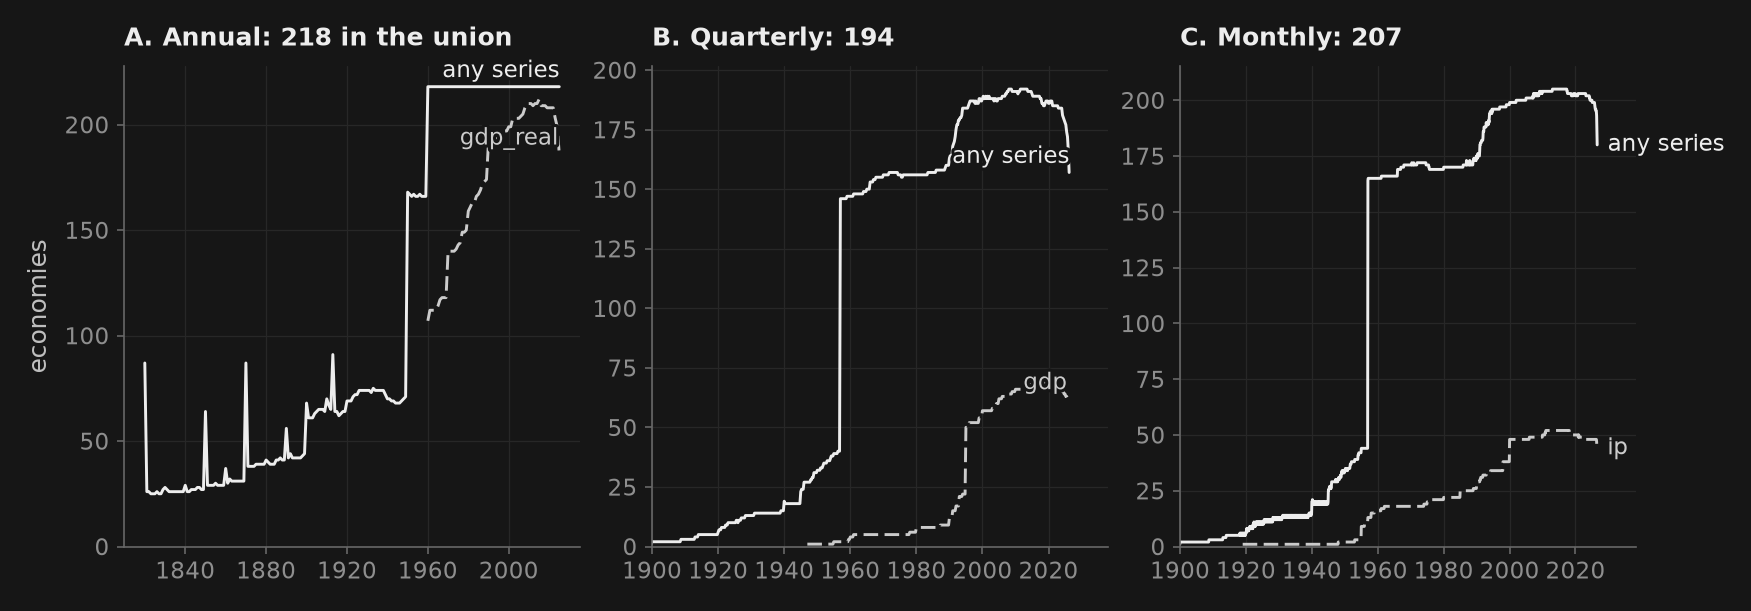

The quarterly and monthly panels begin in 1791 with a single series, GBR fx_usd (q_bis): the figure starts in 1900. Each line stops at the last period with 80% of its peak; after it, what falls is publication lag, not coverage.


In [38]:
receipts = {"Y": coverage(annual, "Y"), "Q": cov_Q, "M": coverage(monthly, "M")}   # cov_Q: §3.5's, same panel
sets = {tr("annual real GDP", "PIB real anual"): set(annual.code[annual.variable == "gdp_real"]),
        tr("quarterly GDP", "PIB trimestral"): set(quarterly.code[quarterly.variable == "gdp"]),
        tr("monthly IP", "producción industrial mensual"): set(monthly.code[monthly.variable == "ip"]),
        tr("monthly unemployment", "paro mensual"): set(monthly.code[monthly.variable == "urate"])}
inter = set.intersection(*sets.values())
union = {f: p.code.nunique() for f, p in (("Y", annual), ("Q", quarterly), ("M", monthly))}

for label, s in sets.items():
    print(tr(f"{label}: {len(s)} economies", f"{label}: {len(s)} economías"))
print(tr(f"Annual union: {union['Y']}. Intersection of the four concepts: {len(inter)} — ",
         f"Unión anual: {union['Y']}. Intersección de los cuatro conceptos: {len(inter)} — ")
      + ", ".join(sorted(inter)[:10]) + "…")
word = {"Y": tr("annual", "anuales"), "Q": tr("quarterly", "trimestrales"), "M": tr("monthly", "mensuales")}
print(tr("Interior gaps (country-variables with a missing period between the first and the last): ",
         "Huecos interiores (país-variables con un período sin dato entre el primero y el último): ")
      + ", ".join(f"{int((r.internal_gaps > 0).sum()):,} {word[f]}" for f, r in receipts.items()) + ".")
for f, r in receipts.items():
    w = r.loc[r.internal_gaps.idxmax()]
    lo, hi = (x.replace("Q", tr("Q", "T")) for x in (w["first"], w["last"]))      # 1989T1 in Spanish
    print(tr(f"   the worst {word[f]}: {w.code} {w.variable}, {w.internal_gaps} periods without data between {lo} and {hi}.",
             f"   la peor de las {word[f]}: {w.code} {w.variable}, {w.internal_gaps} períodos sin dato entre {lo} y {hi}."))

# Figure C: economies per period with any series, and with the core concept of each frequency.
fig, axes = _nbstyle.figura(1, 3)
core = {"Y": ("gdp_real", annual), "Q": ("gdp", quarterly), "M": ("ip", monthly)}
titles = {"Y": tr(f"A. Annual: {union['Y']} in the union", f"A. Anual: {union['Y']} en la unión"),
          "Q": tr(f"B. Quarterly: {union['Q']}", f"B. Trimestral: {union['Q']}"),
          "M": tr(f"C. Monthly: {union['M']}", f"C. Mensual: {union['M']}")}


def upto(s):
    """A count per period, up to its last period at 80 % of its peak: after it, what falls is publication lag."""
    return s.loc[:s[s >= 0.8 * s.max()].index.max()]


for ax, (f, (v, p)) in zip(axes, core.items()):
    every = upto(p.groupby("date").code.nunique())
    one = upto(p.loc[p.variable == v].groupby("date").code.nunique())
    ax.plot(every.index, every, color=cols[0], lw=1.4, label=tr("any series", "alguna serie"))
    ax.plot(one.index, one, color=cols[1], ls=_nbstyle.styles(2)[1], lw=1.4, label=v)
    ax.set_ylim(bottom=0)
    if f != "Y":
        ax.set_xlim(left=pd.Timestamp("1900-01-01"))             # before 1900, a single series (receipt below)
    ax.set_title(titles[f])
    _nbstyle.etiquetar(ax, donde="fin")
axes[0].set_ylabel(tr("economies", "economías"))
plt.show()
r0 = quarterly.loc[quarterly.date.idxmin()]
print(tr(f"The quarterly and monthly panels begin in {r0.date:%Y} with a single series, {r0.code} {r0.variable} "
         f"({r0.source}): the figure starts in 1900. Each line stops at the last period with 80% of its peak; after "
         f"it, what falls is publication lag, not coverage.",
         f"El trimestral y el mensual empiezan en {r0.date:%Y} con una sola serie, {r0.code} {r0.variable} "
         f"({r0.source}): la figura empieza en 1900. Cada línea se detiene en el último período con el 80% de su "
         f"máximo; después, lo que cae es el rezago de publicación, no la cobertura."))

# The union is what the contract promised: every registered economy that publishes anything.
assert annual.code.nunique() >= 217
# An intersection is never larger than its smallest set.
assert len(inter) <= min(map(len, sets.values()))
# Receipts count exactly the rows of the panel.
assert all(r.n.sum() == len(p) for r, p in zip(receipts.values(), (annual, quarterly, monthly)))

## 7. Freeze: manifest, hashes, round trip

The lesson ends where it began: with files. But here there is a decision that differs from the national accounts notebook: **files are written only when something was refreshed**. The default run downloads nothing, so it has nothing new to write. What it does is prove that the delivered files are exactly what this notebook produces from the frozen blocks, bit for bit. The manifest's hash stops being only a test of integrity and becomes a test of reproducibility.

Three decisions, all three from §1:
1. **Levels and deflators, no volumes.** In the panels, the volume is $100\times$ nominal / deflator, exact to the last bit; storing it would store the same information twice and risk the copies ceasing to agree. The blocks, instead, keep what each call returned, as it returned it: they are the raw material, and the course names are applied when they are read.
2. **One source per row; the rest, in the records.** Units, adjustment and aggregation rule live in `t01_series.csv`; who won and why, in `t01_provenance.csv`.
3. **Column names in English.** The files are read by notebooks in two languages; their schema cannot depend on the language of whoever wrote them. For the same reason nothing that is written goes through `tr`: the two versions of the notebook write the same bytes.

And a technical point that is not cosmetic: the panels' values are rounded to twelve **significant digits** before writing, and the gzip files carry the time set to zero. Without that the file changes its hash with the machine and the hour although no number changed. Significant digits and not decimals, because rounding to nine decimals erases what is small: Argentina's price index in 1975 is a billionth of today's, and with nine decimals it came out flat —five months of zero inflation in the middle of an acceleration—. Freezing half the data halfway through is how one ends up with two versions of the same panel; that is why there is a single writer, and it is at the end. To rehearse a refresh without touching the delivery, `MAV_T01_DEST` sends what is written to another folder.

In [39]:
from _t01 import frozen

# Where a refresh writes: data_curso/, or MAV_T01_DEST to rehearse one without touching the delivery.
OUT = Path(os.environ["MAV_T01_DEST"]) if VIVO and os.environ.get("MAV_T01_DEST") else DATA
NAME, PANELS = {"Y": "annual", "Q": "quarterly", "M": "monthly"}, {"Y": annual, "Q": quarterly, "M": monthly}


def where(file):
    """This run's copy if it wrote one; otherwise the delivery's (a partial refresh rewrites only part)."""
    return OUT / file if readable(OUT / file) else DATA / file


def significant(x, digits=12):
    """Round to significant digits, not decimals: a 1975 Argentine price index is a billionth of today's."""
    return np.fromiter((float(f"{v:.{digits}g}") for v in np.asarray(x, dtype=float).tolist()), float, len(x))


# The panels in memory become what the files hold: twelve significant digits, once.
for p in (annual, quarterly, monthly, commodities):
    p["value"] = significant(p.value)
# One table each for provenance and seams; the OECD's quarterly deflators get the reference year their metadata declares.
provenance = pd.concat([prov_Y, prov_Q, prov_M], ignore_index=True)
oecd_defl = (provenance.freq == "Q") & (provenance.source == "q_oecd_qna") & provenance.variable.str.endswith("_defl")
provenance.loc[oecd_defl, "ref_year"] = provenance.code[oecd_defl].map(qmeta.price_ref_year.dropna().astype(int).astype(str))
provenance["ref_year"] = provenance.ref_year.fillna("")
seams = pd.concat([seams_Y, seams_Q, seams_M], ignore_index=True)
countries_out = COUNTRIES.assign(**{f"in_{f}": COUNTRIES.code.isin(set(p.code.unique())) for f, p in PANELS.items()})
# Every file the panels make, built only when it is its turn: three sorted copies at once would not fit an iPad.
products = {**{f"t01_{NAME[f]}.csv.gz": (lambda p=p: frozen(p)) for f, p in PANELS.items()},
            "t01_commodities.csv.gz": lambda: frozen(commodities),
            "t01_provenance.csv": lambda: provenance, "t01_seams.csv": lambda: seams,
            **{f"t01_coverage_{NAME[f]}.csv": (lambda f=f: receipts[f]) for f in "YQM"},
            "t01_countries.csv": lambda: countries_out}

arg = monthly.loc[(monthly.code == "ARG") & (monthly.variable == "cpi") & (monthly.date.dt.year == 1975), "value"]
print(tr(f"Argentina's CPI in 1975, as it will be written: {arg.iloc[0]:.6g} in January, {arg.iloc[-1]:.6g} in "
         f"December (×{arg.iloc[-1] / arg.iloc[0]:.1f}); nine decimals would have kept {arg.round(9).nunique()} "
         f"distinct values of {len(arg)}.",
         f"El IPC de Argentina en 1975, tal como se escribirá: {arg.iloc[0]:.6g} en enero, {arg.iloc[-1]:.6g} en "
         f"diciembre (×{arg.iloc[-1] / arg.iloc[0]:.1f}); nueve decimales habrían dejado {arg.round(9).nunique()} "
         f"valores distintos de {len(arg)}."))

# Twelve significant digits keep the small: Argentina's 1975 index still rises every month.
assert len(arg) == 12 and (arg.diff().dropna() > 0).all()
# Every panel the manifest lists is a file this notebook makes.
assert {e["file"] for e in manifest["panels"].values()} <= set(products)

Argentina's CPI in 1975, as it will be written: 1.06904e-09 in January, 4.51932e-09 in December (×4.2); nine decimals would have kept 5 distinct values of 12.


In [40]:
import puremacro
from _t01 import csv_digest, content_digest, write_csv, write_block, new_manifest, release_memory

written = []
if VIVO:      # 1. every block refreshed in this run, as its call returned it, with its attrs beside it
    for block, e in ((b, e) for b, e in BLOCKS.items() if e["frame"] is not None):
        d = e["frame"]
        if block in ("t01_pwt110", "t01_pwt110_labor"):
            d = pwt if block == "t01_pwt110" else pwt_labor        # the wide code-year shape C reads
        elif block == "sahm" or ("date" not in d.index.names and "date" not in d.columns):
            d = d.reset_index()                                    # FRED's dated table; the country list
        else:
            d = as_long(d)[["code", "date", "variable", "value"]].sort_values(["code", "date", "variable"])
        write_block(OUT, e, d, e["frame"].attrs)
        written.append(e["file"])
    for sid in ("UNRATE", "SAHMCURRENT", "SAHMREALTIME") if BLOCKS["sahm"]["frame"] is not None else ():
        written.append(f"t01_{sid}.csv")      # B's three FRED files, in FRED's own layout
        write_csv(OUT / written[-1], fred_sahm[sid].dropna().rename_axis("observation_date").reset_index())
# 2. The panels and their receipts: written under VIVO; rebuilt and compared byte for byte always.
same = {}
for file, make in products.items():
    same[file] = (write_csv(OUT / file, make()) if VIVO else csv_digest(make())) == content_digest(where(file))
    written += [file] if VIVO else []
    release_memory()        # one sorted copy at a time
if VIVO:      # 3. the manifest: one entry per file, every hash, and who refreshed what
    new = new_manifest(manifest, where, BLOCKS, pwt={"t01_pwt110": pwt, "t01_pwt110_labor": pwt_labor},
                            panels={**{NAME[f]: (f"t01_{NAME[f]}.csv.gz", f, p) for f, p in PANELS.items()},
                                    "commodities": ("t01_commodities.csv.gz", "M", commodities)},
                            extra={"ranks": {"Y": RANK_Y, "Q": RANK_Q, "M": RANK_M}, "prefer": {"Y": PREFER_Y, "M": PREFER_M},
                                   "thresholds": {f: {"min_obs": o, "min_overlap": v} for f, o, v in
                                                  (("Y", MIN_OBS, MIN_OVERLAP), ("Q", MIN_OBS_Q, MIN_OVERLAP_Q),
                                                   ("M", MIN_OBS_M, MIN_OVERLAP_M))}},
                            version=puremacro.__version__)
    (OUT / "t01_manifest.json").write_text(json.dumps(new, indent=2, ensure_ascii=False, default=str) + "\n")
    manifest = json.loads((OUT / "t01_manifest.json").read_text())
    tables = [f for f in written if not f.startswith("t01_blocks/")]
    print(tr(f"Written to {OUT.name}/: {len(written) - len(tables)} block files with their attrs, ",
             f"Escritos en {OUT.name}/: {len(written) - len(tables)} archivos de bloque con sus atributos, ")
          + ", ".join(tables) + tr(" and t01_manifest.json.", " y t01_manifest.json."))
else:
    mb = sum(where(f).stat().st_size for f in same) / 1e6
    print(tr(f"Reproduced bit for bit from the frozen blocks: {len(same)} files, {mb:.1f} MB; nothing was written.",
             f"Reproducido bit a bit desde los bloques congelados: {len(same)} archivos, {mb:.1f} MB; nada se escribió."))

# Every product was rebuilt and compared; a refresh wrote every one.
assert set(same) == set(products) and (not VIVO or set(products) <= set(written))
# The delivery is what this notebook makes from the blocks: same content, bit for bit.
assert all(same.values()), [f for f, ok in same.items() if not ok]

Reproduced bit for bit from the frozen blocks: 10 files, 29.4 MB; nothing was written.


In [41]:
from _t01 import listed, assert_same_rows, peak_rss_mb


def reread(freq, variables=None, codes=None):
    """What B and C get from load_panel; a rehearsal reads its own folder the same way."""
    return load_panel(freq, variables=variables, codes=codes, folder=None if OUT == DATA else OUT)


# Receipts: what was delivered, from which blocks, and what it cost.
table = pd.DataFrame([{tr("file", "archivo"): e["file"], "series": e["variables"], tr("economies", "economías"): e["countries"],
                       tr("periods", "períodos"): f"{e['first'][:7]}–{e['last'][:7]}",
                       tr("observations", "observaciones"): f"{e['observations']:,}", "sha256": e["sha256"][:12]}
                      for e in manifest["panels"].values()])
print(table.to_string(index=False))
stamps = sorted(str(e["fetched_utc"])[:16].replace("T", " ") for e in BLOCKS.values() if e["fetched_utc"])
fresh_list = sorted(b for b, e in BLOCKS.items() if e["frame"] is not None)
print(tr(f"Blocks: {len(BLOCKS)}, {len(fresh_list)} refreshed in this run ({', '.join(fresh_list) or 'none'}); "
         f"the oldest downloaded on {stamps[0]}, the newest on {stamps[-1]} (UTC).",
         f"Bloques: {len(BLOCKS)}, {len(fresh_list)} refrescados en esta corrida ({', '.join(fresh_list) or 'ninguno'}); "
         f"el más viejo descargado el {stamps[0]}, el más reciente el {stamps[-1]} (UTC)."))

# Every file the manifest lists is, byte for byte, the file on disk.
for e in listed(manifest):
    assert sha256(where(e["file"])) == e["sha256"], e["file"]
# B and C read back exactly the panels in memory (one frequency at a time: memory).
for f, p in PANELS.items():
    assert_same_rows(frozen(reread(f)), frozen(p))
    release_memory()
# The volume we do not store is rebuilt from the two series we do.
q = wide_panel(reread("Q", variables=["gdp", "gdp_defl"], codes=["USA"]))
mem = wide_panel(quarterly.loc[(quarterly.code == "USA") & quarterly.variable.isin(["gdp", "gdp_defl"])])
assert np.allclose(100 * q.gdp / q.gdp_defl, 100 * mem.gdp / mem.gdp_defl, rtol=1e-9)

t = time.perf_counter()
reread("Q", variables=CONTRACT["Q"])
t_read = time.perf_counter() - t
print(tr(f"Filtered read of the {len(CONTRACT['Q'])} quarterly series B and C use: {t_read:.2f} s. Whole notebook: "
         f"{time.perf_counter() - T0:.0f} s; peak resident memory (ru_maxrss, which on a Mac also counts freed pages "
         f"the system has not reclaimed yet) {peak_rss_mb():.0f} MB.",
         f"Lectura filtrada de las {len(CONTRACT['Q'])} series trimestrales de B y C: {t_read:.2f} s. Cuaderno completo: "
         f"{time.perf_counter() - T0:.0f} s; memoria residente máxima (ru_maxrss, que en una Mac cuenta también páginas "
         f"liberadas que el sistema aún no reclama) {peak_rss_mb():.0f} MB."))

                  file  series  economies         periods observations       sha256
     t01_annual.csv.gz     190        218 1820-01–2026-01      911,066 f5a701d31766
  t01_quarterly.csv.gz     203        194 1791-01–2026-07      964,497 4562af81c399
    t01_monthly.csv.gz      65        207 1791-01–2026-09    1,485,477 fcc39868b80b
t01_commodities.csv.gz      48          1 1960-01–2026-09       37,187 d2dbe738001b
Blocks: 30, 0 refreshed in this run (none); the oldest downloaded on 2026-10-07 23:47, the newest on 2026-10-07 23:48 (UTC).


Filtered read of the 23 quarterly series B and C use: 0.29 s. Whole notebook: 26 s; peak resident memory (ru_maxrss, which on a Mac also counts freed pages the system has not reclaimed yet) 1409 MB.


## 8. Your turn

1. **Coverage of the labour share.** In 1970–2019, how many economies have compensation of employees, value added and either mixed income or self-employment in a contiguous block of at least 30 years? Report them, with the primary source of each ingredient.
2. **Precedence.** Put WDI first for `gdp` —in `PREFER_Y`, which orders by variable; `RANK_Y` orders blocks— and stack again. Compare the number of seams, their drift and the mean 1970–2019 growth of five economies with those of the original precedence.
3. **A seam.** Pick an unstable seam in `t01_seams.csv`. Explain what differs between the two sources before and after the date, and whether you would use it for a long-run average.
4. **Public capital.** For an economy with `k_gov_net` and `k_gov_pim`, compare levels and growth rates. Which part of the difference is method?
5. **Calendar.** Build quarterly industrial production with the record's rule and compare it, in growth rates, with the quarterly industrial value added of the accounts.
6. **Extension.** Add the rent price index as a monthly series: its record in the dictionary, its call and its receipt. Do not touch any other cell.

### Solutions (sketch)
1. `regular_block(..., freq="Y", start="1970", end="2019", min_obs=30)` on the needed columns; the source comes from `t01_provenance.csv`.
2. A `PREFER_Y` with WDI first for `gdp` is enough; `splice_sources` returns the new seams.
3. Read `ratio_drift`, `ratio_min` and `ratio_max`; a large drift means different growth rates, not a unit error.
4. The IMF's method fixes depreciation rates and an initial stock; the national balance sheet uses its own service lives.
5. The record says `mean` for an index; industrial production excludes construction and services.
6. One row in `t01_series.csv`, the call inside its own `load_block` —if `stes_panel` does not know the concept, it is added in puremacro, not here— and `MAV_T01_VIVO` with the block's name.

### Explore with AI
- "Read `t01_provenance.csv` for Mexico: which source won for each annual variable, and which alternatives were set aside? Quote the rows."
- "With `t01_series.csv`, which quarterly variables are not seasonally adjusted, and why do they carry that name? Quote the record, do not invent coverage."

**Summary.** We started by asking which economies there are, not which ones we want: the World Bank's registry, plus Taiwan, separates 218 economies from 79 aggregates by one piece of metadata, not by the shape of the code. Every source came in through a single door —one puremacro call, one frozen file, one record per series— and a variable without a record or a code outside the registry stopped the notebook.

The annual panel stacks WDI, the OECD, Eurostat, the IMF, the ILO and Maddison. The audit of §2.5 showed that the units trap is real and identified —a factor of a million between pesos and millions of pesos— and that, once corrected at the source, almost every comparison agrees; what is left splits into misdeclared tables, other currencies or bases, and other concepts. The precedence of §2.6 put each country's accounts in the currency of the GDP that wins, chose one primary source per country and variable and extended history through 1,581 seams, each with its ratio and its drift; those that drift and also move the level by more than a factor of two were rejected.

The quarterly panel asks for everything since 1947 and gains pre-1995 history for 19 economies; quarterly public investment arrives by two routes joined country by country without counting twice, US unemployment from 1955, and the ladder of §3.5 shows that the United States leaves at the labour step and Japan at the income step.

The monthly panel brings together activity, employment, prices by component, effective exchange rates, rates and yields for 207 economies; what does not exist for free was written down as absence, not as zero.

§5 showed that four quarters from one office are its year —except where the year is fiscal, or where the quarterly and annual figures are different editions— and that the difference between offices is the price of precedence. §6, that the union and the intersection are different objects.

And §7 closed with files: the three panels are rebuilt bit for bit from the frozen blocks, and B and C read them with `load_panel(freq, variables=…)`.

**Next:** [B — measurement, vintages and cycle diagnostics](T01_B_measurement_and_cycles.ipynb). The [national accounts companion](T01_B_cross_country_facts.ipynb) keeps the construction details: it is a lab for going deeper, not a prerequisite placed after this notebook.